In [ ]:
#3D viewer
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go

def get_particle_name(pdg):
    """Convert PDG code to particle name"""
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")

def get_particle_group(pdg):
    """Color group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"

# ---------------------------------------------------------------
# 1) Load + label particle types
# ---------------------------------------------------------------
Sim_Folder = "/scratch/general/vast/u1520754/test3d_proton_1e4GeV"
path = Sim_Folder + "/particles_3d/particles_3d.parquet"
df = pd.read_parquet(path)
df = df[np.isfinite(df[["X", "Y", "Z", "time"]]).all(axis=1)].reset_index(drop=True)
df["name"]  = df["pdg"].map(get_particle_name)
df["group"] = df["pdg"].map(get_particle_group)

# (optional) keep the notebook snappy on big showers
# df = df.sample(min(len(df), 30_000), random_state=0)

tmin, tmax = df["time"].min(), df["time"].max()
print("rows:", len(df), "| t range [s]:", tmin, "->", tmax)

# ---------------------------------------------------------------
# 2) Coordinates -> km, compact float32
# ---------------------------------------------------------------
R_EARTH    = 6371e3
E_UNIT  = "GeV"          # <-- change to the unit of df["kinetic_energy"]

def compact(a, decimals=4):
    return np.round(a, decimals).astype(np.float32)

X = compact(df["X"].to_numpy() / 1e3)
Y = compact(df["Y"].to_numpy() / 1e3)
Z = compact((df["Z"].to_numpy() - R_EARTH) / 1e3)
T = df["time"].to_numpy()
EK = df["kinetic_energy"].to_numpy().astype(np.float32)
NAMES  = df["name"].to_numpy()
GROUPS = df["group"].to_numpy()

# hover data: [exact type, kinetic energy, time in µs]
CUSTOM = np.empty((len(df), 3), dtype=object)
CUSTOM[:, 0] = NAMES
CUSTOM[:, 1] = EK
CUSTOM[:, 2] = np.round(T * 1e6, 3)
HOVER = ("<b>%{customdata[0]}</b><br>"
         f"E_kin = %{{customdata[1]:.4g}} {E_UNIT}<br>"
         "t = %{customdata[2]} µs<extra></extra>")

# ---------------------------------------------------------------
# 3) One color per group
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±":      "#BBACED",  # 
    "e±":      "#D4F30A",  # 
    "γ":       "#F5FAF8",  # 
    "τ±":      "#4CC804",  # 
    "hadrons": "#009E73",  # 
    "ν":       "#DDDDDD",  # 
}
ORDER = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]
groups = [g for g in ORDER if g in set(GROUPS)]
group_idx = {g: np.flatnonzero(GROUPS == g) for g in groups}

print("Legend (group -> color):")
for g in groups:
    print(f"  {g:<8} -> {GROUP_COLOR[g]}  ({len(group_idx[g])} rows)")

# ---------------------------------------------------------------
# 4) Axis limits: region containing 95% of particles (2.5–97.5 percentile)
# ---------------------------------------------------------------
def rng95(a, pad=0.05):
    lo, hi = np.percentile(a, [0, 100])#np.percentile(a, [2.5, 97.5])
    span = max(hi - lo, 1e-3)
    return [float(lo - pad * span), float(hi + pad * span)]

XR, YR, ZR = rng95(X), rng95(Y), rng95(Z)
spans = np.array([XR[1] - XR[0], YR[1] - YR[0], ZR[1] - ZR[0]])
aspect = spans / spans.max()          # true proportions inside the cropped box
print(f"X range {XR} km\nY range {YR} km\nZ range {ZR} km")

# ---------------------------------------------------------------
# 5) Time window for the slider
# ---------------------------------------------------------------
nsteps = 100
times = np.linspace(tmin, tmax, nsteps)
width = (tmax - tmin) / nsteps * 1.5    # half-width of highlight window [s]

BRIGHT_SIZE, DIM_SIZE = 1.5, 0.7
DIM_OPACITY = 0.12
DIM_MAX_PER_TYPE = 1_000
rng = np.random.default_rng(0)

def bright(g, t0):
    sel = group_idx[g]
    return sel[np.abs(T[sel] - t0) <= width]

# ---------------------------------------------------------------
# 6) Traces per group: [legend-only, dim (static), bright (animated)]
# ---------------------------------------------------------------
fig = go.Figure()
data_trace_idx = []

for g in groups:
    c = GROUP_COLOR[g]

    # (a) legend-only
    fig.add_trace(go.Scatter3d(
        x=[None], y=[None], z=[None], mode="markers",
        name=g, legendgroup=g, showlegend=True,
        marker=dict(size=10, color=c, opacity=1.0), hoverinfo="skip"))

    # (b) dim background (static, hoverable)
    idx = group_idx[g]
    if DIM_MAX_PER_TYPE and len(idx) > DIM_MAX_PER_TYPE:
        idx = rng.choice(idx, DIM_MAX_PER_TYPE, replace=False)
    fig.add_trace(go.Scatter3d(
        x=X[idx], y=Y[idx], z=Z[idx], mode="markers",
        name=g, legendgroup=g, showlegend=False,
        customdata=CUSTOM[idx], hovertemplate=HOVER,
        marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY, line=dict(width=0))))

    # (c) bright: current time window (animated, hoverable)
    s = bright(g, times[0])
    fig.add_trace(go.Scatter3d(
        x=X[s], y=Y[s], z=Z[s], mode="markers",
        name=g, legendgroup=g, showlegend=False,
        customdata=CUSTOM[s], hovertemplate=HOVER,
        marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0, line=dict(width=0))))
    data_trace_idx.append(len(fig.data) - 1)

# ---------------------------------------------------------------
# 7) Animation frames (positions + hover data)
# ---------------------------------------------------------------
SAVE_HTML = True
OUT_HTML  = Sim_Folder + "/shower_3d.html"
FRAME_MS  = 0.0001

labels = [f"{t0*1e6:.1f} µs" for t0 in times]

frames, n_frame_pts = [], 0
for t0, lab in zip(times, labels):
    fdata = []
    for g in groups:
        s = bright(g, t0)
        n_frame_pts += len(s)
        fdata.append(go.Scatter3d(x=X[s], y=Y[s], z=Z[s], customdata=CUSTOM[s]))
    frames.append(go.Frame(data=fdata, traces=data_trace_idx, name=lab))
fig.frames = frames
print(f"points stored in frames: {n_frame_pts:,}")

play_args  = dict(frame=dict(duration=FRAME_MS, redraw=True),
                  transition=dict(duration=0), fromcurrent=True, mode="immediate")
pause_args = dict(frame=dict(duration=0, redraw=False),
                  transition=dict(duration=0), mode="immediate")
slider_steps = [dict(method="animate", label=lab,
                     args=[[lab], dict(frame=dict(duration=0, redraw=True),
                                       transition=dict(duration=0), mode="immediate")])
                for lab in labels]

# ---------------------------------------------------------------
# 8) Layout
# ---------------------------------------------------------------
axis_style = dict(backgroundcolor="black", gridcolor="gray",
                  color="white", zerolinecolor="gray", showbackground=True,
                  autorange=False)

fig.update_layout(
    updatemenus=[dict(
        type="buttons", direction="left",
        x=0.02, y=0.02, xanchor="left", yanchor="bottom",
        pad=dict(r=10, t=10),
        bgcolor="#333333", bordercolor="white", font=dict(color="white"),
        buttons=[
            dict(label="▶ Play",  method="animate", args=[None, play_args]),
            dict(label="⏸ Pause", method="animate", args=[[None], pause_args]),
        ],
    )],
    sliders=[dict(
        active=0, steps=slider_steps,
        x=0.15, len=0.83, y=0.02, yanchor="bottom",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        transition={"duration": 0},
        font=dict(color="white"),
        pad=dict(t=30),
    )],
    title="Particle positions in 3D — color = particle group, bright = current time window "
          "(axes: central 95% of particles)",
    legend=dict(
        title=dict(text="Particle type", font=dict(size=22)),
        font=dict(size=20),
        itemsizing="constant",
        bgcolor="rgba(0,0,0,0.6)",
        bordercolor="white",
        borderwidth=1,
        x=0.01, y=0.99, xanchor="left", yanchor="top",
    ),
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black",
    plot_bgcolor="black",
    font=dict(color="white"),
    scene=dict(
        xaxis=dict(title="X [km]", range=XR, **axis_style),
        yaxis=dict(title="Y [km]", range=YR, **axis_style),
        zaxis=dict(title="Z [km]", range=ZR, **axis_style),
        bgcolor="black",
        aspectmode="manual",
        aspectratio=dict(x=aspect[0], y=aspect[1], z=aspect[2]),
        uirevision="constant",
    ),
    margin=dict(l=0, r=0, b=0, t=40),
)

ZOOM = 5   # >1 = zoom in (axes are already cropped to 95%, so 1 is a good start)
fig.update_layout(scene_camera=dict(
    eye=dict(x=1.25/ZOOM, y=1.25/ZOOM, z=1.25/ZOOM),
    center=dict(x=0, y=0, z=0),
    up=dict(x=0, y=0, z=1),
))

# ---------------------------------------------------------------
# 9) Save + show
# ---------------------------------------------------------------
if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", auto_play=False, full_html=True)
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()

In [ ]:
#SHower Axis
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def get_particle_name(pdg):
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")

def get_particle_group(pdg):
    """Color group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"

# ---------------------------------------------------------------
# Settings
# ---------------------------------------------------------------
#Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau2"
path       = Sim_Folder + "/particles_3d/particles_3d.parquet"
OUT_HTML   = Sim_Folder + "/shower_coords.html"
SAVE_HTML  = True
R_EARTH    = 6375e3
E_UNIT     = "GeV"          # <-- unit of df["kinetic_energy"] (hover label only)

nsteps    = 100            # number of slider frames
TIME_MODE = "linear"     # "quantile" = equal #particles per frame, "linear" = equal Δt
LAT_PCT   = 90             # lateral axis range = this percentile of r  (try 70–99)
DIM_MAX_PER_TYPE = 2000
BRIGHT_SIZE, DIM_SIZE, DIM_OPACITY = 4, 3, 0.3
FRAME_MS  = 0.001

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
df = pd.read_parquet(path)
df = df[np.isfinite(df[["X", "Y", "Z", "time"]]).all(axis=1)].reset_index(drop=True)
df["name"]  = df["pdg"].map(get_particle_name)
df["group"] = df["pdg"].map(get_particle_group)

T      = df["time"].to_numpy(np.float64)
NAMES  = df["name"].to_numpy()
GROUPS = df["group"].to_numpy()
EK     = df["kinetic_energy"].to_numpy().astype(np.float32)
Pm = np.column_stack([df["X"].to_numpy(np.float64),
                      df["Y"].to_numpy(np.float64),
                      df["Z"].to_numpy(np.float64) - R_EARTH])     # [m]
print("rows:", len(df), "| t range [s]:", T.min(), "->", T.max())

# hover data: [exact type, kinetic energy, time in µs]
CUSTOM = np.empty((len(df), 3), dtype=object)
CUSTOM[:, 0] = NAMES
CUSTOM[:, 1] = EK
CUSTOM[:, 2] = np.round(T * 1e6, 3)
HOVER = ("<b>%{customdata[0]}</b><br>"
         f"E_kin = %{{customdata[1]:.4g}} {E_UNIT}<br>"
         "t = %{customdata[2]} µs<extra></extra>")

# ---------------------------------------------------------------
# 2) Colors: one per group
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±":      "#BBACED",  # 
    "e±":      "#D4F30A",  # 
    "γ":       "#F5FAF8",  # 
    "τ±":      "#4CC804",  # 
    "hadrons": "#009E73",  # 
    "ν":       "#DDDDDD",  # 
}
ORDER  = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]
groups = [g for g in ORDER if g in set(GROUPS)]
group_idx = {g: np.flatnonzero(GROUPS == g) for g in groups}

print("Legend (group -> color):")
for g in groups:
    print(f"  {g:<8} -> {GROUP_COLOR[g]}  ({len(group_idx[g])} rows)")

# ---------------------------------------------------------------
# 3) Shower axis (first two frames with >1 m centroid separation)
# ---------------------------------------------------------------
lin_times = np.linspace(T.min(), T.max(), 1000)
lin_w = (T.max() - T.min()) / 1000 * 1.5
c0 = c1 = None
for t0 in lin_times:
    m = np.abs(T - t0) <= lin_w
    if not m.any():
        continue
    c = Pm[m].mean(axis=0)
    if c0 is None:
        c0 = c
    elif np.linalg.norm(c - c0) > 1.0:
        c1 = c
        break
ez = (c1 - c0); ez /= np.linalg.norm(ez)
ref = np.array([0.0, 0.0, 1.0]) if abs(ez[2]) < 0.999 else np.array([1.0, 0.0, 0.0])
ex = np.cross(ref, ez); ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
zen = np.degrees(np.arccos(np.clip(-ez[2], -1, 1)))
azi = np.degrees(np.arctan2(ez[1], ez[0]))
print(f"axis ez = {ez.round(4)}  zenith {zen:.1f}°, azimuth {azi:.1f}°")

Prel = Pm - c0
SU = Prel @ ex                   # x' [m]
SV = Prel @ ey                   # y' [m]
SW = Prel @ ez / 1e3             # z' [km]
SR = np.maximum(np.hypot(SU, SV), 1e-2)   # r [m], floored for log axis

# ---------------------------------------------------------------
# 4) Time bins
# ---------------------------------------------------------------
if TIME_MODE == "quantile":
    edges = np.unique(np.quantile(T, np.linspace(0, 1, nsteps + 1)))
else:
    edges = np.linspace(T.min(), T.max(), nsteps + 1)
nbins = len(edges) - 1
BIN = np.clip(np.searchsorted(edges, T, side="right") - 1, 0, nbins - 1)
labels = [f"{0.5*(edges[k]+edges[k+1])*1e6:.2f} µs" for k in range(nbins)]
names  = [f"f{k}" for k in range(nbins)]          # unique frame names

# per group: indices grouped by bin
group_bins = {}
for g in groups:
    idx = group_idx[g]
    order = idx[np.argsort(BIN[idx], kind="stable")]
    cuts = np.searchsorted(BIN[order], np.arange(nbins + 1))
    group_bins[g] = [order[cuts[k]:cuts[k+1]] for k in range(nbins)]

# ---------------------------------------------------------------
# 5) Figure: 2x2 panels
# ---------------------------------------------------------------
PANELS = [(1, 1, SU, SV),   # shower plane
          (1, 2, SW, SR),   # r vs z' (log r)
          (2, 1, SW, SU),   # z' vs x'
          (2, 2, SW, SV)]   # z' vs y'

fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                    subplot_titles=("Shower plane (⊥ axis)", "Radial distance vs depth (log)",
                                    "Longitudinal vs x′", "Longitudinal vs y′"))
rng = np.random.default_rng(0)
anim = []
for g in groups:
    c = GROUP_COLOR[g]
    idx = group_idx[g]
    if len(idx) > DIM_MAX_PER_TYPE:
        idx = rng.choice(idx, DIM_MAX_PER_TYPE, replace=False)
    s0 = group_bins[g][0]

    # legend-only entry
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                             showlegend=True, hoverinfo="skip",
                             marker=dict(size=12, color=c)), row=1, col=1)
    for r_, c_, A, B in PANELS:
        # dim background (static, hoverable)
        fig.add_trace(go.Scatter(x=A[idx], y=B[idx], mode="markers", name=g, legendgroup=g,
                                 showlegend=False,
                                 customdata=CUSTOM[idx], hovertemplate=HOVER,
                                 marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY)),
                      row=r_, col=c_)
        # bright: current time bin (animated, hoverable)
        fig.add_trace(go.Scatter(x=A[s0], y=B[s0], mode="markers", name=g, legendgroup=g,
                                 showlegend=False,
                                 customdata=CUSTOM[s0], hovertemplate=HOVER,
                                 marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0)),
                      row=r_, col=c_)
        anim.append(len(fig.data) - 1)

frames = []
for k in range(nbins):
    fdata = []
    for g in groups:
        s = group_bins[g][k]
        for _, _, A, B in PANELS:
            fdata.append(go.Scatter(x=A[s], y=B[s], customdata=CUSTOM[s]))
    frames.append(go.Frame(data=fdata, traces=anim, name=names[k]))
fig.frames = frames

# ---------------------------------------------------------------
# 6) Axis ranges: robust, core-focused (unchanged)
# ---------------------------------------------------------------
lat = float(np.percentile(SR, LAT_PCT)) * 1.1
LAT = [-lat, lat]
LON = [0.0, float(np.percentile(SW, 99.5)) * 1.05]
RLOG = [np.log10(max(np.percentile(SR, 0.5), 1e-2)), np.log10(SR.max()) + 0.1]
print(f"lateral range ±{lat:.1f} m | z' range {LON} km | r range 10^{RLOG[0]:.1f}–10^{RLOG[1]:.1f} m")

ax = dict(gridcolor="#333333", zerolinecolor="#777777", color="white",
          showline=True, linecolor="gray", mirror=True)
fig.update_xaxes(**ax); fig.update_yaxes(**ax)
fig.update_xaxes(title_text="x′ [m]", range=LAT, row=1, col=1)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=1, col=1, scaleanchor="x", scaleratio=1)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=1, col=2)
fig.update_yaxes(title_text="r [m]", type="log", range=RLOG, row=1, col=2)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=1)
fig.update_yaxes(title_text="x′ [m]", range=LAT, row=2, col=1)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=2)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=2, col=2)

# ---------------------------------------------------------------
# 7) Controls + layout
# ---------------------------------------------------------------
play_args  = dict(frame=dict(duration=FRAME_MS, redraw=False),
                  transition=dict(duration=0), fromcurrent=True, mode="immediate")
pause_args = dict(frame=dict(duration=0, redraw=False),
                  transition=dict(duration=0), mode="immediate")
steps = [dict(method="animate", label=labels[k],
              args=[[names[k]], dict(frame=dict(duration=0, redraw=False),
                                     transition=dict(duration=0), mode="immediate")])
         for k in range(nbins)]

fig.update_layout(
    height=1100, width=1500,
    title=f"Shower coordinates (zenith {zen:.1f}°, azimuth {azi:.1f}°) — time bins: {TIME_MODE}",
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.06,
        xanchor="left", yanchor="top", bgcolor="#333333", bordercolor="white",
        font=dict(color="white"),
        buttons=[dict(label="▶ Play",  method="animate", args=[None, play_args]),
                 dict(label="⏸ Pause", method="animate", args=[[None], pause_args])])],
    sliders=[dict(active=0, steps=steps, x=0.12, len=0.85, y=-0.06, yanchor="top",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        font=dict(color="white"), transition={"duration": 0})],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=18),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.01, y=1.0),
    hovermode="closest",
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=20, b=140, t=80),
)
fig.update_annotations(font=dict(size=16, color="white"))

if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", auto_play=False, full_html=True)
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()

In [ ]:
# Shower viewer - 2x2 animated panels
#   (1,1) global X-Z          (1,2) global Y-Z
#   (2,1) selectable          (2,2) particle counts vs time (3 components)
#         LAT_AXIS = "x"  -> z' along axis vs x'      (longitudinal)
#         LAT_AXIS = "y"  -> z' along axis vs y'      (longitudinal)
#         LAT_AXIS = "xy" -> X global vs Y global     (plan view)
#   The Earth's surface (sphere of radius R_M + Ground_Height) is drawn as a
#   filled brown region in the three particle panels (not in the histogram one).
#
# Optimised for HTML size and render speed:
#   * float32 arrays -> plotly >= 6 stores them base64-encoded (not JSON text)
#   * no per-point strings; numeric customdata only (and optional)
#   * bounded number of animated points (ANIM_MAX) and of dim-context points
#   * plain SVG Scatter: VERIFIED that Scattergl traces do NOT refresh during
#     frame animation (headless-Chrome test: stale with redraw=False, blank with
#     redraw=True), so WebGL is opt-in only (USE_GL).
# =====================================================================
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def get_particle_name(pdg):
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")


def get_particle_group(pdg):
    """Colour group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"


# ---------------------------------------------------------------
# Settings
# ---------------------------------------------------------------
Sim_Folder  = "/scratch/general/vast/u1520754/test3d_proton_1e7GeV"
#Sim_Folder  = "/scratch/general/vast/u1520754/test3d_gamma_1e4GeV"
#Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV_h1500_zen92_az270"

# Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_muon"

path        = Sim_Folder + "/particles_3d/particles_3d.parquet"
SLICES_YAML = Sim_Folder + "/particles_3d/particles_3d_slices.yaml"
OUT_HTML    = Sim_Folder + "/shower_coords.html"
SAVE_HTML   = True
Ground_Height = 1500                         # height of the drawn ground level [m]
R_EARTH     = 6371e3 + Ground_Height         # fallback Earth radius [m]
E_UNIT      = "GeV"
Z_MIN_KM    = -50 #None#-50       # lower limit of the Z axis [km]; None = automatic

nsteps       = 100         # number of slider frames
TIME_MODE    = "linear"    # "quantile" = equal #particles per frame, "linear" = equal dt
LAT_PCT      = 90          # longitudinal panels: lateral range = this percentile of |lat| (70-99)
GLOBAL_PCT   = 100         # percentile clip for the two global panels (100 = full range)
EQUAL_ASPECT = False       # True -> 1:1 data units in the two global panels / plan view
START_AT_MAX = False       # True -> open the slider at the shower maximum
FRAME_MS     = 40          # animation speed [ms per frame]

# --- HTML size / rendering speed ---
ANIM_MAX          = 30_000   # particles in the animated (bright) layer; None = keep all
DIM_MAX_PER_GROUP = 1_200    # particles per group in the static dim context layer
BRIGHT_SIZE, DIM_SIZE, DIM_OPACITY = 4, 3, 0.3
USE_GL            = False    # True -> Scattergl (see the note in the header; NOT recommended)
HOVER_DETAIL      = True     # True -> add [E_kin, t] customdata (bigger file)

# --- bottom-right panel ---
HIST_LOG_Y = True            # log-scale the counts axis
HIST_MODE  = "per_bin"       # "per_bin" = particles per time bin, "cumulative"

# --- Earth surface (drawn in the three particle panels) ---
SHOW_EARTH        = True
SHOW_EARTH_LONG   = False    # draw the Earth band in the longitudinal panel
EARTH_FILL        = "rgba(139, 90, 43, 0.55)"   # brown, semi-transparent
EARTH_XY_FILL     = "rgba(139, 90, 43, 0.30)"   # plan view: ground is the backdrop
EARTH_LINE_COLOR  = "#C68642"                   # lighter brown for the surface line
EARTH_DEPTH_FRAC  = 0.18     # filled depth below the surface = this fraction of the
                             # panel's data span (keeps the Earth clearly visible)
EARTH_NPTS        = 400      # points per surface profile

LAT_AXIS = "xy"      # "x" -> z' vs x'   "y" -> z' vs y'   "xy" -> X global vs Y global

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
cols = ["X", "Y", "Z", "time", "kinetic_energy", "pdg"]
df = pd.read_parquet(path, columns=cols)
df = df[np.isfinite(df[cols]).all(axis=1)].reset_index(drop=True)
df["name"]  = df["pdg"].map(get_particle_name)
df["group"] = df["pdg"].map(get_particle_group)

# frame metadata: R_E and the origin of the global X/Y/Z columns
try:
    import yaml
    _m = yaml.safe_load(open(SLICES_YAML))
    R_M, ORIGIN_M = float(_m["earth_radius_m"]), np.asarray(_m["output_origin_m"], float)
    R_M = R_M + Ground_Height
    print(f"frame: R_E = {R_M/1e3:.3f} km | output origin = {ORIGIN_M} m "
          f"(X/Y/Z are telescope-centred; ground level = z = {(R_M-ORIGIN_M[2])/1e3:.1f} km)")
except Exception as exc:
    R_M, ORIGIN_M = R_EARTH, np.array([0.0, 0.0, R_EARTH])
    print(f"NOTE: cannot read {SLICES_YAML} ({exc}); using R_E = {R_EARTH/1e3:.0f} km")

T      = df["time"].to_numpy(np.float64)
PDG    = df["pdg"].to_numpy()
GROUPS = df["group"].to_numpy()
EK     = df["kinetic_energy"].to_numpy().astype(np.float32)

# global coordinates (telescope-centred, as written by CORSIKA 8) in km
XG = (df["X"].to_numpy(np.float64) / 1e3).astype(np.float32)
YG = (df["Y"].to_numpy(np.float64) / 1e3).astype(np.float32)
ZG = (df["Z"].to_numpy(np.float64) / 1e3).astype(np.float32)
print("rows:", len(df), "| t range [s]:", T.min(), "->", T.max())
print("X global [km] %.3f .. %.3f | Y global [km] %.3f .. %.3f | Z global [km] %.3f .. %.3f"
      % (XG.min(), XG.max(), YG.min(), YG.max(), ZG.min(), ZG.max()))

# ---------------------------------------------------------------
# 2) Colours: one per group
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±":      "#BBACED",
    "e±":      "#D4F30A",
    "γ":       "#F5FAF8",
    "τ±":      "#4CC804",
    "hadrons": "#009E73",
    "ν":       "#DDDDDD",
}
ORDER  = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]
groups = [g for g in ORDER if g in set(GROUPS)]
group_idx = {g: np.flatnonzero(GROUPS == g) for g in groups}

print("Legend (group -> colour):")
for g in groups:
    print(f"  {g:<8} -> {GROUP_COLOR[g]}  ({len(group_idx[g])} rows)")

# ---------------------------------------------------------------
# 3) Shower axis (first two frames with >1 m centroid separation)
# ---------------------------------------------------------------
Pm = np.column_stack([df["X"].to_numpy(np.float64),
                      df["Y"].to_numpy(np.float64),
                      df["Z"].to_numpy(np.float64)])          # [m]

lin_times = np.linspace(T.min(), T.max(), 1000)
lin_w = (T.max() - T.min()) / 1000 * 1.5
c0 = c1 = None
for t0 in lin_times:
    m = np.abs(T - t0) <= lin_w
    if not m.any():
        continue
    c = Pm[m].mean(axis=0)
    if c0 is None:
        c0 = c
    elif np.linalg.norm(c - c0) > 1.0:
        c1 = c
        break
ez = (c1 - c0); ez /= np.linalg.norm(ez)
ref = np.array([0.0, 0.0, 1.0]) if abs(ez[2]) < 0.999 else np.array([1.0, 0.0, 0.0])
ex = np.cross(ref, ez); ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
zen = np.degrees(np.arccos(np.clip(-ez[2], -1, 1)))
azi = np.degrees(np.arctan2(ez[1], ez[0]))
print(f"axis ez = {ez.round(4)}  zenith {zen:.1f}°, azimuth {azi:.1f}°")

Prel = Pm - c0
SU = (Prel @ ex).astype(np.float32)             # x' [m]
SV = (Prel @ ey).astype(np.float32)             # y' [m]
SW = (Prel @ ez / 1e3).astype(np.float32)       # z' along axis [km]
SR = np.maximum(np.hypot(SU, SV), 1e-2)         # r [m]

# --- which quantity goes on the vertical axis of panel (2,1)? ---
if LAT_AXIS not in ("x", "y", "xy"):
    raise ValueError(f"LAT_AXIS must be 'x', 'y' or 'xy', got {LAT_AXIS!r}")
LONG_MODE = LAT_AXIS in ("x", "y")            # (2,1) = longitudinal z' vs lateral
if LONG_MODE:
    SLAT, lat_name = (SU, "x′") if LAT_AXIS == "x" else (SV, "y′")
    lat  = float(np.percentile(np.abs(SLAT), LAT_PCT)) * 1.1
    LAT  = [-lat, lat]
    P21  = (2, 1, SW, SLAT, f"z′ = %{{x:.3f}} km<br>{lat_name} = %{{y:.1f}} m")
    P21_TITLE = f"Longitudinal vs {lat_name}"
    print(f"panel (2,1): longitudinal z′ vs {lat_name} (lateral range ±{lat:.1f} m)")
else:                                           # "xy": plan view, both axes global
    SLAT, lat_name, LAT, lat = None, None, None, None
    P21  = (2, 1, XG, YG, "X = %{x:.3f} km<br>Y = %{y:.3f} km")
    P21_TITLE = "Global X-Y (plan view)"
    print("panel (2,1): global X vs global Y (plan view)")

# ---------------------------------------------------------------
# 4) Time bins
# ---------------------------------------------------------------
if TIME_MODE == "quantile":
    edges = np.unique(np.quantile(T, np.linspace(0, 1, nsteps + 1)))
else:
    edges = np.linspace(T.min(), T.max(), nsteps + 1)
nbins  = len(edges) - 1
BIN    = np.clip(np.searchsorted(edges, T, side="right") - 1, 0, nbins - 1)
labels = [f"{0.5*(edges[k]+edges[k+1])*1e6:.2f} µs" for k in range(nbins)]
names  = [f"f{k}" for k in range(nbins)]
bin_totals = np.bincount(BIN, minlength=nbins)
k0 = int(np.argmax(bin_totals)) if START_AT_MAX else 0

# ---------------------------------------------------------------
# 5) Sub-sampling - this is what keeps the HTML small
#    * one sample per group for the animated layer; all of its points are spread
#      over the frames, so the total frame payload is bounded by ANIM_MAX
#    * a smaller static sample per group for the dim context layer
# ---------------------------------------------------------------
rng = np.random.default_rng(0)

if ANIM_MAX and len(df) > ANIM_MAX:
    anim_idx = {}
    for g in groups:
        idx = group_idx[g]
        share = max(200, int(round(ANIM_MAX * len(idx) / len(df))))
        anim_idx[g] = rng.choice(idx, min(share, len(idx)), replace=False)
else:
    anim_idx = {g: group_idx[g] for g in groups}

anim_bins = {}
for g in groups:
    idx = anim_idx[g]
    order = idx[np.argsort(BIN[idx], kind="stable")]
    cuts = np.searchsorted(BIN[order], np.arange(nbins + 1))
    anim_bins[g] = [order[cuts[k]:cuts[k+1]] for k in range(nbins)]

anim_total = sum(len(v) for v in anim_idx.values())
dim_idx = {g: (group_idx[g] if len(group_idx[g]) <= DIM_MAX_PER_GROUP
               else rng.choice(group_idx[g], DIM_MAX_PER_GROUP, replace=False))
           for g in groups}
dim_total = sum(len(v) for v in dim_idx.values())
print(f"sampling: animated {anim_total:,} particles, dim context {dim_total:,} "
      f"(the frames carry the animated ones)")
# ---------------------------------------------------------------
# 5b) Species (exact PDG codes) present in each group's samples
# ---------------------------------------------------------------
species = {}
for g in groups:
    present = set(np.unique(PDG[anim_idx[g]])) | set(np.unique(PDG[dim_idx[g]]))
    species[g] = sorted(present, key=lambda p: (abs(int(p)), int(p)))
    print(f"  {g:<8}: " + ", ".join(get_particle_name(int(p)) for p in species[g]))

def hover_tag(p):
    return f"<b>{get_particle_name(int(p))}</b>  (PDG {int(p)})<br>"
# ---------------------------------------------------------------
# 6) Bottom-right: particle counts per time bin, 3 components
# ---------------------------------------------------------------
ABS = np.abs(PDG)
COMPONENTS = [
    ("EM (e±, γ)",  "#D4F30A", np.isin(ABS, (11, 22))),
    ("muonic (μ±)", "#BBACED", ABS == 13),
    ("hadronic",    "#009E73", ~np.isin(ABS, (11, 13, 22))),
]

u_edges = edges * 1e6
hist_x, hist_y = {}, {}
for label, color, mask in COMPONENTS:
    counts = np.bincount(BIN[mask], minlength=nbins).astype(float)
    if HIST_MODE == "cumulative":
        counts = np.cumsum(counts)
    hist_x[label] = 0.5 * (u_edges[:-1] + u_edges[1:])
    hist_y[label] = counts
    print(f"  component {label:<12} total {int(mask.sum()):>7,} particles")

# ---------------------------------------------------------------
# 7) Axis ranges + Earth-surface profiles
# ---------------------------------------------------------------
def robust_range(a, pct=GLOBAL_PCT, pad=0.04):
    lo = float(np.percentile(a, 100 - pct))
    hi = float(np.percentile(a, pct))
    if hi <= lo:
        hi = lo + 1.0
    d = (hi - lo) * pad
    return [lo - d, hi + d]


RXG, RZG = robust_range(XG), robust_range(ZG)
RYG = robust_range(YG)
LON = [0.0, float(np.percentile(SW, 99.5)) * 1.05]      # only used in the longitudinal mode

# --- Earth surface: sphere of radius R_M centred at the root origin, which sits at
#     (-output_origin) in the plotted (telescope-centred) frame.
C_E = -ORIGIN_M / 1e3                                   # Earth centre in the plot frame [km]
R_K = R_M / 1e3                                         # Earth radius [km]


def z_surface(x_km, y_km):
    """Height [km] of the ground-level sphere at the horizontal position (x, y) [km]."""
    r2 = (R_K**2 - (np.asarray(x_km, dtype=float) - C_E[0])**2
          - (np.asarray(y_km, dtype=float) - C_E[1])**2)
    return C_E[2] + np.sqrt(np.maximum(r2, 0.0))


x_c, y_c = float(np.median(XG)), float(np.median(YG))   # profile line through the shower
earth = {}                                              # panel key -> (x, y) of the surface
earth_zg = earth_left = None

if SHOW_EARTH:
    # (1,1) X-Z : ground profile along x at the shower's y
    gx = np.linspace(RXG[0], RXG[1], EARTH_NPTS)
    earth[(1, 1)] = (gx, z_surface(gx, y_c))
    # (1,2) Y-Z : ground profile along y at the shower's x
    gy = np.linspace(RYG[0], RYG[1], EARTH_NPTS)
    earth[(1, 2)] = (gy, z_surface(x_c, gy))

    if LONG_MODE:
        # (2,1) z'-x' : the lateral axis is purely horizontal (ex is horizontal), so the
        # ground of the shower-frame cross-section (the plane holding the axis and the
        # local vertical) projects onto a LINE of constant z' -- the axial position where
        # the shower axis meets the Earth.  The Earth is drawn as a band on the side
        # towards which the altitude decreases (left for upgoing, right for downgoing).
        P0_root = c0 + ORIGIN_M                                 # axis point, root frame [m]
        b_ax = float(P0_root @ ez)
        disc_ax = max(b_ax**2 - float(P0_root @ P0_root) + R_M**2, 0.0)
        s1, s2 = -b_ax - np.sqrt(disc_ax), -b_ax + np.sqrt(disc_ax)
        z_g = (s1 if abs(s1) < abs(s2) else s2) / 1e3           # [km]
        earth_zg, earth_left = z_g, bool(ez[2] > 0.0)
        if SHOW_EARTH_LONG:
            pad = EARTH_DEPTH_FRAC * (LON[1] - LON[0])
            LON = ([min(LON[0], z_g) - pad, LON[1]] if earth_left
                   else [LON[0], max(LON[1], z_g) + pad])
        print("Earth: ground level z = %.3f..%.3f km (X-Z) / %.3f..%.3f km (Y-Z); axis "
              "crosses the ground at z' = %.3f km -> band on the %s"
              % (earth[(1, 1)][1].min(), earth[(1, 1)][1].max(),
                 earth[(1, 2)][1].min(), earth[(1, 2)][1].max(), z_g,
                 "left" if earth_left else "right"))
    else:
        print("Earth: ground level z = %.3f..%.3f km (X-Z) / %.3f..%.3f km (Y-Z); "
              "plan view -> brown backdrop in the X-Y panel"
              % (earth[(1, 1)][1].min(), earth[(1, 1)][1].max(),
                 earth[(1, 2)][1].min(), earth[(1, 2)][1].max()))

    # keep the ground (plus a slab below it) inside the vertical range
    z_lo = min(RZG[0], float(earth[(1, 1)][1].min()), float(earth[(1, 2)][1].min()))
    RZG = [z_lo - EARTH_DEPTH_FRAC * (RZG[1] - RZG[0]), RZG[1]]
if Z_MIN_KM is not None:
    RZG[0] = Z_MIN_KM

if LONG_MODE:
    print(f"ranges: X {RXG[0]:.2f}..{RXG[1]:.2f} km | Y {RYG[0]:.2f}..{RYG[1]:.2f} km | "
          f"Z {RZG[0]:.2f}..{RZG[1]:.2f} km | lateral ±{lat:.1f} m | z′ {LON[0]:.1f}..{LON[1]:.1f} km")
else:
    print(f"ranges: X {RXG[0]:.2f}..{RXG[1]:.2f} km | Y {RYG[0]:.2f}..{RYG[1]:.2f} km | "
          f"Z {RZG[0]:.2f}..{RZG[1]:.2f} km")

# ---------------------------------------------------------------
# 8) Figure
# ---------------------------------------------------------------
Xlab, Ylab, Zlab = "X global [km]", "Y global [km]", "Z global [km]"
PANELS = [  # (row, col, x, y, hovertemplate)
    (1, 1, XG, ZG, "X = %{x:.3f} km<br>Z = %{y:.3f} km"),
    (1, 2, YG, ZG, "Y = %{x:.3f} km<br>Z = %{y:.3f} km"),
    P21,
]
SCAT = go.Scattergl if USE_GL else go.Scatter

fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                    subplot_titles=("Global X-Z", "Global Y-Z", P21_TITLE,
                                    f"Particles per time bin ({HIST_MODE})"))


def ground_fill(xs, ys, ybottom, name="Earth (ground level)", show=False):
    """Filled brown slab: the surface profile closed onto the bottom of the panel."""
    return go.Scatter(
        x=np.concatenate([np.asarray(xs), np.asarray(xs)[::-1]]),
        y=np.concatenate([np.asarray(ys), np.full(len(ys), ybottom)]),
        mode="lines", name=name, legendgroup="earth", showlegend=show,
        line=dict(color=EARTH_LINE_COLOR, width=1.5),
        fill="toself", fillcolor=EARTH_FILL, hoverinfo="skip")


# the Earth first, so the particles are drawn on top of it
if SHOW_EARTH:
    fig.add_trace(ground_fill(*earth[(1, 1)], RZG[0], show=True), row=1, col=1)
    fig.add_trace(ground_fill(*earth[(1, 2)], RZG[0]), row=1, col=2)
    if LONG_MODE and SHOW_EARTH_LONG:
        x_edge = LON[0] if earth_left else LON[1]
        fig.add_trace(go.Scatter(
            x=[earth_zg, earth_zg, x_edge, x_edge],
            y=[LAT[0], LAT[1], LAT[1], LAT[0]],
            mode="lines", name="Earth (ground level)", legendgroup="earth", showlegend=False,
            line=dict(color=EARTH_LINE_COLOR, width=1.5),
            fill="toself", fillcolor=EARTH_FILL, hoverinfo="skip"), row=2, col=1)
    elif not LONG_MODE:
        # plan view: looking straight down, the ground is the whole background
        fig.add_trace(go.Scatter(
            x=[RXG[0], RXG[1], RXG[1], RXG[0]],
            y=[RYG[0], RYG[0], RYG[1], RYG[1]],
            mode="lines", name="Earth (ground level)", legendgroup="earth", showlegend=False,
            line=dict(color=EARTH_LINE_COLOR, width=1.5),
            fill="toself", fillcolor=EARTH_XY_FILL, hoverinfo="skip"), row=2, col=1)


def hov(panel_hover):
    if not HOVER_DETAIL:
        return panel_hover
    return (panel_hover + f"<br>E_kin = %{{customdata[0]:.4g}} {E_UNIT}"
                          "<br>t = %{customdata[1]:.3f} µs")


anim = []          # trace indices updated by every frame
for g in groups:
    c = GROUP_COLOR[g]
    # legend-only entry (one per group, as before)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                             showlegend=True, hoverinfo="skip",
                             marker=dict(size=12, color=c)), row=1, col=1)

    b_all = anim_bins[g][k0]
    for p in species[g]:
        pname = get_particle_name(int(p))
        tag   = hover_tag(p)
        d_idx = dim_idx[g][PDG[dim_idx[g]] == p]
        b_idx = b_all[PDG[b_all] == p]
        cd_dim = np.column_stack([EK[d_idx], T[d_idx] * 1e6]).astype(np.float32) if HOVER_DETAIL else None
        cd_bin = np.column_stack([EK[b_idx], T[b_idx] * 1e6]).astype(np.float32) if HOVER_DETAIL else None

        for r_, c_, A, B, hov_t in PANELS:
            tmpl = tag + hov(hov_t) + "<extra></extra>"   # hide the grey group box
            # static dim context
            fig.add_trace(SCAT(x=A[d_idx], y=B[d_idx], mode="markers", name=pname,
                               legendgroup=g, showlegend=False, customdata=cd_dim,
                               hovertemplate=tmpl,
                               marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY)),
                          row=r_, col=c_)
            # bright: current time bin (animated)
            fig.add_trace(SCAT(x=A[b_idx], y=B[b_idx], mode="markers", name=pname,
                               legendgroup=g, showlegend=False, customdata=cd_bin,
                               hovertemplate=tmpl,
                               marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0)),
                          row=r_, col=c_)
            anim.append(len(fig.data) - 1)

# bottom-right: static component spectra + animated "now" markers
for label, color, _ in COMPONENTS:
    fig.add_trace(go.Scatter(x=hist_x[label], y=hist_y[label], mode="lines+markers",
                             name=label, legendgroup="hist", showlegend=True,
                             line=dict(color=color, width=2, shape="hv"),
                             marker=dict(size=5, color=color),
                             hovertemplate=label + "<br>t = %{x:.2f} µs<br>N = %{y:.0f}<extra></extra>"),
                  row=2, col=2)
for label, color, _ in COMPONENTS:
    fig.add_trace(go.Scatter(x=[hist_x[label][k0]], y=[hist_y[label][k0]], mode="markers",
                             name=label + " (now)", legendgroup="hist", showlegend=False,
                             marker=dict(size=13, color=color, symbol="diamond",
                                         line=dict(color="white", width=1)),
                             hoverinfo="skip"), row=2, col=2)
    anim.append(len(fig.data) - 1)

# ---------------------------------------------------------------
# 9) Frames
# ---------------------------------------------------------------
frames = []
for k in range(nbins):
    fdata = []
    for g in groups:
        s_all = anim_bins[g][k]
        for p in species[g]:
            s = s_all[PDG[s_all] == p]
            cd = np.column_stack([EK[s], T[s] * 1e6]).astype(np.float32) if HOVER_DETAIL else None
            for _, _, A, B, _ in PANELS:
                fdata.append(SCAT(x=A[s], y=B[s], customdata=cd))
    for label, _, _ in COMPONENTS:                      # "now" markers
        fdata.append(go.Scatter(x=[hist_x[label][k]], y=[hist_y[label][k]]))
    frames.append(go.Frame(data=fdata, traces=anim, name=names[k]))
fig.frames = frames

# ---------------------------------------------------------------
# 10) Axes
# ---------------------------------------------------------------
ax = dict(gridcolor="#333333", zerolinecolor="#777777", color="white",
          showline=True, linecolor="gray", mirror=True)
fig.update_xaxes(**ax); fig.update_yaxes(**ax)

fig.update_xaxes(title_text=Xlab, range=RXG, row=1, col=1)
fig.update_yaxes(title_text=Zlab, range=RZG, row=1, col=1,
                 **({"scaleanchor": "x", "scaleratio": 1} if EQUAL_ASPECT else {}))
fig.update_xaxes(title_text=Ylab, range=RYG, row=1, col=2)
fig.update_yaxes(title_text=Zlab, range=RZG, row=1, col=2,
                 **({"scaleanchor": "x2", "scaleratio": 1} if EQUAL_ASPECT else {}))
if LONG_MODE:
    fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=1)
    fig.update_yaxes(title_text=f"{lat_name} [m]", range=LAT, row=2, col=1)
else:
    fig.update_xaxes(title_text=Xlab, range=RXG, row=2, col=1)
    fig.update_yaxes(title_text=Ylab, range=RYG, row=2, col=1,
                     **({"scaleanchor": "x3", "scaleratio": 1} if EQUAL_ASPECT else {}))
fig.update_xaxes(title_text="t [µs]", row=2, col=2)
fig.update_yaxes(title_text="particles per bin", type="log" if HIST_LOG_Y else "linear",
                 row=2, col=2)
if HIST_LOG_Y:
    ymax = max(float(v.max()) for v in hist_y.values())
    fig.update_yaxes(range=[0.0, np.log10(max(ymax, 10.0)) + 0.2], row=2, col=2)

# ---------------------------------------------------------------
# 11) Controls + layout
# ---------------------------------------------------------------
redraw = bool(USE_GL)          # SVG frames update reliably without a full redraw
play_args  = dict(frame=dict(duration=FRAME_MS, redraw=redraw),
                  transition=dict(duration=0), fromcurrent=True, mode="immediate")
pause_args = dict(frame=dict(duration=0, redraw=redraw),
                  transition=dict(duration=0), mode="immediate")
steps = [dict(method="animate", label=labels[k],
              args=[[names[k]], dict(frame=dict(duration=0, redraw=redraw),
                                     transition=dict(duration=0), mode="immediate")])
         for k in range(nbins)]

fig.update_layout(
    height=1100, width=1500,
    title=f"Shower coordinates (zenith {zen:.1f}°, azimuth {azi:.1f}°) — time bins: {TIME_MODE}",
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.06,
        xanchor="left", yanchor="top", bgcolor="#333333", bordercolor="white",
        font=dict(color="white"),
        buttons=[dict(label="▶ Play",  method="animate", args=[None, play_args]),
                 dict(label="⏸ Pause", method="animate", args=[[None], pause_args])])],
    sliders=[dict(active=k0, steps=steps, x=0.12, len=0.85, y=-0.06, yanchor="top",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        font=dict(color="white"), transition={"duration": 0})],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=18),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.01, y=1.0),
    hovermode="closest",
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=20, b=140, t=80),
)
fig.update_annotations(font=dict(size=16, color="white"))

# ---------------------------------------------------------------
# 12) Save
# ---------------------------------------------------------------
if int(plotly.__version__.split(".")[0]) < 6:
    print(f"NOTE: plotly {plotly.__version__} writes arrays as JSON text; "
          "plotly >= 6 base64-encodes them (much smaller).")
if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", auto_play=False, full_html=True,
                   config={"displaylogo": False})
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.2f} MB, plotly {plotly.__version__})")
fig.show()


energy cut: E >= 10 GeV -> kept 210 of 212 muons (E range 2.11 .. 8.39e+03 GeV)
altitude cut: h_tel = 1500.0 m, window ±100 m -> kept 194 of 210 muons (muon h range 1500.0 .. 2310.8 m)
loaded 194 muons (obsplane) | zenith 90.8°
muons used: 194 of 194 | pairs: 18,721 (weight 1)
range widened to include telescope box: Δd 0.1..4.72e+04 m, |Δt| 1..1.54e+04 ns
Δd range: 0.1 .. 4.72e+04 m | |Δt| range: 1 .. 1.54e+04 ns
saved: /scratch/general/vast/u1520754/test3d_proton_1e6GeV/muons_pair_dt_vs_dd_loglog.png


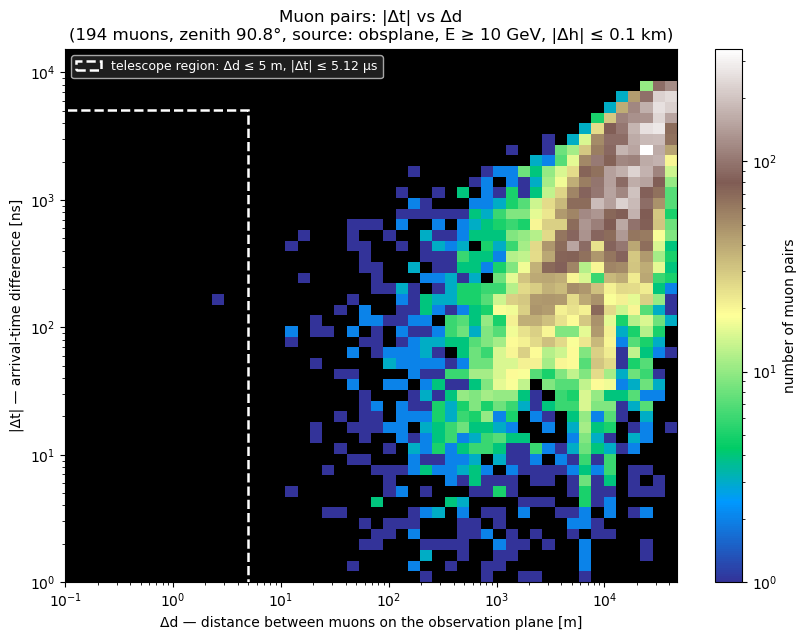

pairs in telescope box (bin-resolution): 1 of 18,609 plotted (0.01%) | full-sample estimate: 1


In [1]:
# Muon pair correlations at the observation plane (log-log), standalone
#   counts of muon pairs: |Δt| vs Δd
# Altitude cut: keep muons with |h_mu - h_tel| <= ALT_WIN_M, where h is the
# altitude above the (curved, spherical) Earth surface.
# Reads the CORSIKA 8 output directly:
#   SOURCE = "obsplane" -> <Sim_Folder>/particles/particles.parquet   (x, y on the plane)
#   SOURCE = "3d"       -> <Sim_Folder>/particles_3d/particles_3d.parquet
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ------------------------- input options ---------------------------------
#Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV_h1500_zen92_az270"
Sim_Folder  = "/scratch/general/vast/u1520754/test3d_proton_1e6GeV"

SOURCE      = "obsplane"           # "obsplane" or "3d"

OBS_FILE    = Sim_Folder + "/particles/particles.parquet"
P3D_FILE    = Sim_Folder + "/particles_3d/particles_3d.parquet"
SLICES_YAML = Sim_Folder + "/particles_3d/particles_3d_slices.yaml"

Ground_Height = 1500               # [m] ground / observation level (as in the viewer)
SHELL_TOL_M   = 5.0                # "3d" mode: keep muons with |r - R_ground| < this [m]
TIME_IN_UNIT  = 1.0                # seconds per unit of the time column (C8: seconds -> 1.0)
TIME_UNIT     = "ns"               # plotting unit: "ns", "us", "s"
ZENITH_DEG    = None               # None = estimate from the data; or e.g. 92.0

# --- altitude cut (curved Earth) ---
ALT_CUT     = True
ALT_WIN_M   = 100.0               # keep |h_mu - h_tel| <= this [m]
PLANE_ALT_M = None                 # altitude of the obs-plane tangent point [m]; None = Ground_Height
TEL_ALT_M   = None                 # telescope altitude [m]; None = from plane / YAML
TEL_X_M, TEL_Y_M = 0.0, 0.0        # telescope position in plane coordinates [m] (obsplane mode)

# --- telescope acceptance region (dashed box) ---
SHOW_TEL_BOX  = True
TEL_D_MAX_M   = 5.0               # muon-muon distance range: 0 .. this [m]
TEL_DT_MAX_S  = 5.12e-6            # time-difference range: 0 .. this [s]
TEL_BOX_COLOR = "white"

# --- energy cut ---
E_CUT       = True
E_MIN_GEV   = 10.0                 # keep muons with energy >= this [GeV]
E_COL       = "kinetic_energy"     # column used for the cut ("kinetic_energy" or "energy")
E_IN_GEV    = 1.0                  # GeV per unit of the energy column (CORSIKA 8 writes GeV -> 1.0; if eV use 1e-9)
INCLUDE_TEL_BOX_IN_RANGE = True    # force the plotted range to cover the telescope box
TEL_D_MIN_M  = 0.1                 # lowest distance to display when forcing the box in [m]
TEL_DT_MIN_S = 1e-9                # lowest |Δt| to display when forcing the box in [s]
# ------------------------- analysis options ------------------------------
MAX_MU      = 100000
CHUNK       = 1000
NBINS_D     = 50
NBINS_DT    = 50
D_PCT       = 99.0
DT_PCT      = 99.0
D_LO_PCT    = 0.1
DT_LO_PCT   = 0.1
SHOW_FRONT  = False
USE_LOGNORM = True
SHOW_AS      = "counts"     # "prob"   -> probability
                          # "counts" -> number of muon pairs (full-sample, via pair_w)
                          # "auto"   -> probability, fall back to counts if it can't be computed

PROB_NORM    = "all"      # "all"     -> divide by ALL unique pairs  (sum = fraction in window)
                          # "plotted" -> divide by pairs in the plotted window (sum = 1)
PROB_DENSITY = True      # True -> also divide by the bin area in (ln d, ln dt): density per unit log-area
BG_COLOR    = "black"
OUT_PNG2    = Sim_Folder + "/muons_pair_dt_vs_dd_loglog.png"
# -------------------------------------------------------------------------

t_fac = {"ns": 1e9, "us": 1e6, "s": 1.0}[TIME_UNIT]
t_lab = {"ns": "ns", "us": "µs", "s": "s"}[TIME_UNIT]


def read_frame_meta():
    """Bare Earth radius R_E [m] and output origin (telescope position in the root frame)."""
    try:
        import yaml
        m = yaml.safe_load(open(SLICES_YAML))
        return float(m["earth_radius_m"]), np.asarray(m["output_origin_m"], float), True
    except Exception as exc:
        R_E = 6371e3
        print(f"NOTE: cannot read {SLICES_YAML} ({exc}); using R_E = {R_E/1e3:.0f} km")
        return R_E, np.array([0.0, 0.0, R_E + Ground_Height]), False


def report_cut(h, h_tel, keep):
    print(f"altitude cut: h_tel = {h_tel:.1f} m, window ±{ALT_WIN_M:.0f} m -> "
          f"kept {keep.sum():,} of {len(keep):,} muons "
          f"(muon h range {h.min():.1f} .. {h.max():.1f} m)")


def load_obsplane():
    cols = pd.read_parquet(OBS_FILE).columns
    lc = {c.lower(): c for c in cols}
    need = ["x", "y", "time", "pdg"]
    miss = [c for c in need if c not in lc]
    if miss:
        raise KeyError(f"{OBS_FILE} lacks columns {miss}; available: {list(cols)}")

    ecol = None
    if E_CUT:
        for cand in (E_COL.lower(), "kinetic_energy", "energy"):
            if cand in lc:
                ecol = lc[cand]; break
        if ecol is None:
            raise KeyError(f"energy cut requested but no energy column found; available: {list(cols)}")

    use = [lc[c] for c in need] + [lc[c] for c in ("nx", "ny", "nz") if c in lc]
    if ecol is not None:
        use.append(ecol)
    df = pd.read_parquet(OBS_FILE, columns=use)
    df.columns = [c.lower() for c in df.columns]
    df = df[np.abs(df["pdg"]) == 13]
    df = df[np.isfinite(df[["x", "y", "time"]]).all(axis=1)]

    if E_CUT and len(df):
        e_gev = df[ecol.lower()].to_numpy(float) * E_IN_GEV
        ke = e_gev >= E_MIN_GEV
        print(f"energy cut: E >= {E_MIN_GEV:g} GeV -> kept {ke.sum():,} of {len(ke):,} muons "
              f"(E range {e_gev.min():.3g} .. {e_gev.max():.3g} GeV)")
        df = df[ke]

    if ALT_CUT and len(df):
        R_E, _, _ = read_frame_meta()
        h_pl = Ground_Height if PLANE_ALT_M is None else PLANE_ALT_M
        R_pl = R_E + h_pl
        x = df["x"].to_numpy(float); y = df["y"].to_numpy(float)
        h_mu  = np.sqrt(R_pl**2 + x**2 + y**2) - R_E
        h_tel = (np.sqrt(R_pl**2 + TEL_X_M**2 + TEL_Y_M**2) - R_E
                 if TEL_ALT_M is None else TEL_ALT_M)
        keep = np.abs(h_mu - h_tel) <= ALT_WIN_M
        report_cut(h_mu, h_tel, keep)
        df = df[keep]

    x = df["x"].to_numpy(float); y = df["y"].to_numpy(float)
    t = df["time"].to_numpy(float) * TIME_IN_UNIT
    zen = None
    if {"nx", "ny", "nz"} <= set(df.columns) and len(df):
        n = df[["nx", "ny", "nz"]].to_numpy(float).mean(axis=0)
        n /= np.linalg.norm(n)
        zen = float(np.degrees(np.arccos(np.clip(-n[2], -1, 1))))
    return x, y, t, zen


def load_3d():
    R_E, ORIGIN_M, _ = read_frame_meta()
    R_M = R_E + Ground_Height
    ecol = E_COL if E_COL in ("kinetic_energy", "energy") else "kinetic_energy"
    cols = ["X", "Y", "Z", "time", "pdg"] + ([ecol] if E_CUT else [])
    df = pd.read_parquet(P3D_FILE, columns=cols)
    df = df[np.isfinite(df).all(axis=1)]
    T_all = df["time"].to_numpy(float)
    P_all = df[["X", "Y", "Z"]].to_numpy(float)

    # zenith from the shower axis (same recipe as the viewer)
    zen = None
    lin_w = (T_all.max() - T_all.min()) / 1000 * 1.5
    c0 = None
    for t0 in np.linspace(T_all.min(), T_all.max(), 1000):
        m = np.abs(T_all - t0) <= lin_w
        if not m.any():
            continue
        c = P_all[m].mean(axis=0)
        if c0 is None:
            c0 = c
        elif np.linalg.norm(c - c0) > 1.0:
            ez = (c - c0) / np.linalg.norm(c - c0)
            zen = float(np.degrees(np.arccos(np.clip(-ez[2], -1, 1))))
            break

    mu = np.abs(df["pdg"].to_numpy()) == 13
    if E_CUT:
        e_gev = df[ecol].to_numpy(float) * E_IN_GEV
        n0 = mu.sum()
        mu &= e_gev >= E_MIN_GEV
        print(f"energy cut: E >= {E_MIN_GEV:g} GeV -> kept {mu.sum():,} of {n0:,} muon rows")
    P, t = P_all[mu], T_all[mu] * TIME_IN_UNIT
    r = np.linalg.norm(P + ORIGIN_M, axis=1)
    keep = np.abs(r - R_M) < SHELL_TOL_M
    P, t, r = P[keep], t[keep], r[keep]
    print(f"3d mode: {keep.sum():,} muon rows within ±{SHELL_TOL_M} m of the ground shell")

    if ALT_CUT and len(P):
        h_mu  = r - R_E
        h_tel = (np.linalg.norm(ORIGIN_M) - R_E) if TEL_ALT_M is None else TEL_ALT_M
        kc = np.abs(h_mu - h_tel) <= ALT_WIN_M
        report_cut(h_mu, h_tel, kc)
        P, t = P[kc], t[kc]

    up = ORIGIN_M / np.linalg.norm(ORIGIN_M)
    ex = np.array([1.0, 0.0, 0.0]) - up[0] * up
    ex /= np.linalg.norm(ex)
    ey = np.cross(up, ex)
    return P @ ex, P @ ey, t, zen


# --- load ----------------------------------------------------------------
if SOURCE == "obsplane":
    xs, ys, ts_s, zen_est = load_obsplane()
elif SOURCE == "3d":
    xs, ys, ts_s, zen_est = load_3d()
else:
    raise ValueError("SOURCE must be 'obsplane' or '3d'")
ts = ts_s * t_fac
zen = ZENITH_DEG if ZENITH_DEG is not None else (zen_est if zen_est is not None else 0.0)
print(f"loaded {len(xs):,} muons ({SOURCE}) | zenith {zen:.1f}°")
if len(xs) < 2:
    raise SystemExit("Fewer than 2 muons - check SOURCE / paths / SHELL_TOL_M / ALT_WIN_M.")

# --- subsample -----------------------------------------------------------
rng = np.random.default_rng(1)
N_full = len(xs)
if MAX_MU and N_full > MAX_MU:
    pick = rng.choice(N_full, MAX_MU, replace=False)
    px, py, pt = xs[pick], ys[pick], ts[pick]
else:
    px, py, pt = xs, ys, ts
N = len(px)
pair_w = (N_full * (N_full - 1)) / (N * (N - 1))
n_pairs = N * (N - 1) // 2
print(f"muons used: {N:,} of {N_full:,} | pairs: {n_pairs:,} (weight {pair_w:.3g})")

# --- ranges --------------------------------------------------------------
m = min(200_000, n_pairs)
i = rng.integers(0, N, m); j = rng.integers(0, N, m)
ok = i != j
dd_s = np.hypot(px[i[ok]] - px[j[ok]], py[i[ok]] - py[j[ok]])
dt_s = np.abs(pt[i[ok]] - pt[j[ok]])
dd_s, dt_s = dd_s[dd_s > 0], dt_s[dt_s > 0]

D_MIN  = float(np.percentile(dd_s, D_LO_PCT))
D_MAX  = float(np.percentile(dd_s, D_PCT)) * 1.05
DT_MIN = float(np.percentile(dt_s, DT_LO_PCT))
DT_MAX = float(np.percentile(dt_s, DT_PCT)) * 1.05
if SHOW_TEL_BOX and INCLUDE_TEL_BOX_IN_RANGE:
    tel_dt_max = TEL_DT_MAX_S * t_fac                    # box upper |Δt| in plotting unit
    D_MIN  = min(D_MIN,  TEL_D_MIN_M)
    DT_MIN = min(DT_MIN, TEL_DT_MIN_S * t_fac)
    D_MAX  = max(D_MAX,  TEL_D_MAX_M * 3)                # keep some margin above the box
    DT_MAX = max(DT_MAX, tel_dt_max * 3)
    print(f"range widened to include telescope box: "
          f"Δd {D_MIN:.3g}..{D_MAX:.3g} m, |Δt| {DT_MIN:.3g}..{DT_MAX:.3g} {t_lab}")
d_ed  = np.geomspace(D_MIN,  D_MAX,  NBINS_D + 1)
dt_ed = np.geomspace(DT_MIN, DT_MAX, NBINS_DT + 1)
print(f"Δd range: {D_MIN:.3g} .. {D_MAX:.3g} m | |Δt| range: {DT_MIN:.3g} .. {DT_MAX:.3g} {t_lab}")

# --- chunked histogram over all unique pairs -----------------------------
H = np.zeros((NBINS_D, NBINS_DT))
n_used = 0
for i0 in range(0, N, CHUNK):
    i1 = min(i0 + CHUNK, N)
    dx = px[i0:i1, None] - px[None, i0:]
    dy = py[i0:i1, None] - py[None, i0:]
    dt = np.abs(pt[i0:i1, None] - pt[None, i0:])
    upper = np.arange(i0, N)[None, :] > np.arange(i0, i1)[:, None]
    h = np.histogram2d(np.hypot(dx, dy)[upper], dt[upper], bins=[d_ed, dt_ed])[0]
    H += h
    n_used += h.sum()

# --- counts -> probability, with fall-back to counts ----------------------
def make_prob():
    if PROB_NORM == "plotted":
        denom = n_used
        lab = "probability (normalised to pairs in the window)"
    else:
        denom = n_pairs
        lab = "probability (fraction of all muon pairs)"
    if denom <= 0:
        raise ValueError("no pairs to normalise by")
    Pm = H / denom                                   # pair_w cancels
    if PROB_DENSITY:
        lnd  = np.diff(np.log(d_ed))[:, None]
        lndt = np.diff(np.log(dt_ed))[None, :]
        Pm = Pm / (lnd * lndt)
        lab = "probability density per unit ln(Δd) ln(|Δt|)"
    if not np.isfinite(Pm).all() or Pm.max() <= 0:
        raise ValueError("probability map is empty / non-finite")
    return Pm, lab

H_counts = H * pair_w                                # counts rescaled to the full sample
mode = SHOW_AS.lower()
if mode == "counts":
    A, clab = H_counts, "number of muon pairs"
else:
    try:
        A, clab = make_prob()
        print(f"sum of plotted probabilities = {A.sum():.4g} "
              f"({100*n_used/n_pairs:.1f}% of pairs are inside the plotted window)")
    except Exception as exc:
        if mode == "prob":
            raise
        print(f"NOTE: probability not available ({exc}); falling back to number of pairs")
        A, clab = H_counts, "number of muon pairs"

# --- plot ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 6.5))
c_unit = 299_792_458.0 / t_fac

Am = np.ma.masked_equal(A.T, 0)
norm = None
if USE_LOGNORM and Am.count():
    vmin = Am.min()
    norm = LogNorm(vmin=vmin, vmax=max(Am.max(), vmin * 10))
pcm = ax.pcolormesh(d_ed, dt_ed, Am, cmap="terrain", shading="flat", norm=norm)
plt.colorbar(pcm, ax=ax).set_label(clab)

if SHOW_FRONT:
    s = abs(np.sin(np.radians(zen)))
    d_line = np.geomspace(D_MIN, D_MAX, 200)
    ax.plot(d_line, d_line * s / c_unit, "r--", lw=1.2,
            label=fr"flat front: $|\Delta t| = \Delta d\,|\sin\theta|/c$ (θ={zen:.1f}°)")
    ax.legend(loc="upper left", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(D_MIN, D_MAX); ax.set_ylim(DT_MIN, DT_MAX)
ax.set_xlabel("Δd — distance between muons on the observation plane [m]")
ax.set_ylabel(f"|Δt| — arrival-time difference [{t_lab}]")
ax.set_facecolor(BG_COLOR)
if SHOW_TEL_BOX:
    from matplotlib.patches import Rectangle
    tel_dt_max = TEL_DT_MAX_S * t_fac                    # convert s -> plotting unit
    # log axes can't start at 0: draw from well below the axis limits, the view clips it
    x0, y0 = D_MIN * 1e-3, DT_MIN * 1e-3
    rect = Rectangle((x0, y0), TEL_D_MAX_M - x0, tel_dt_max - y0,
                     fill=False, edgecolor=TEL_BOX_COLOR, linestyle="--", linewidth=1.8,
                     label=f"telescope region: Δd ≤ {TEL_D_MAX_M:g} m, "
                           f"|Δt| ≤ {TEL_DT_MAX_S*1e6:g} µs",
                     zorder=5)
    ax.add_patch(rect)
    ax.legend(loc="upper left", fontsize=9, facecolor="0.15", labelcolor="white")
cut_txt = ""
if E_CUT:   cut_txt += f", E ≥ {E_MIN_GEV:g} GeV"
if ALT_CUT: cut_txt += f", |Δh| ≤ {ALT_WIN_M/1e3:g} km"
ax.set_title(f"Muon pairs: |Δt| vs Δd\n({N_full:,} muons, zenith {zen:.1f}°, "
             f"source: {SOURCE}{cut_txt})", fontsize=12)
plt.tight_layout()
plt.savefig(OUT_PNG2, dpi=150)
print(f"saved: {OUT_PNG2}")
plt.show()
if SHOW_TEL_BOX:
    tel_dt_max = TEL_DT_MAX_S * t_fac
    id_ = d_ed[1:]  <= TEL_D_MAX_M
    it_ = dt_ed[1:] <= tel_dt_max
    n_box = H[np.ix_(id_, it_)].sum()
    print(f"pairs in telescope box (bin-resolution): {n_box:,.0f} of {n_used:,.0f} plotted "
          f"({100*n_box/max(n_used,1):.2f}%) | full-sample estimate: {n_box*pair_w:,.0f}")

energy cut: E >= 100 GeV -> kept 420 of 420 muons (E range 128 .. 8.28e+03 GeV)
direction cut: zen [85, 95] deg, az [0, 360] deg -> kept 420 of 420 particles
altitude cut: h_tel = 1500.0 m, window ±100 m -> kept 420 of 420 muons (muon h range 1500.0 .. 1508.7 m)
loaded 420 muons (obsplane) | zenith 90.0°
muons used: 420 of 420 | pairs: 87,990 (weight 1)
range widened to include telescope box: Δd 0.1..1.19e+04 m, |Δt| 0.0806..1.54e+04 ns
Δd range: 0.1 .. 1.19e+04 m | |Δt| range: 0.0806 .. 1.54e+04 ns
saved: /scratch/general/vast/u1520754/test3d_proton_1e7GeV/muons_pair_dt_vs_dd_loglog.png


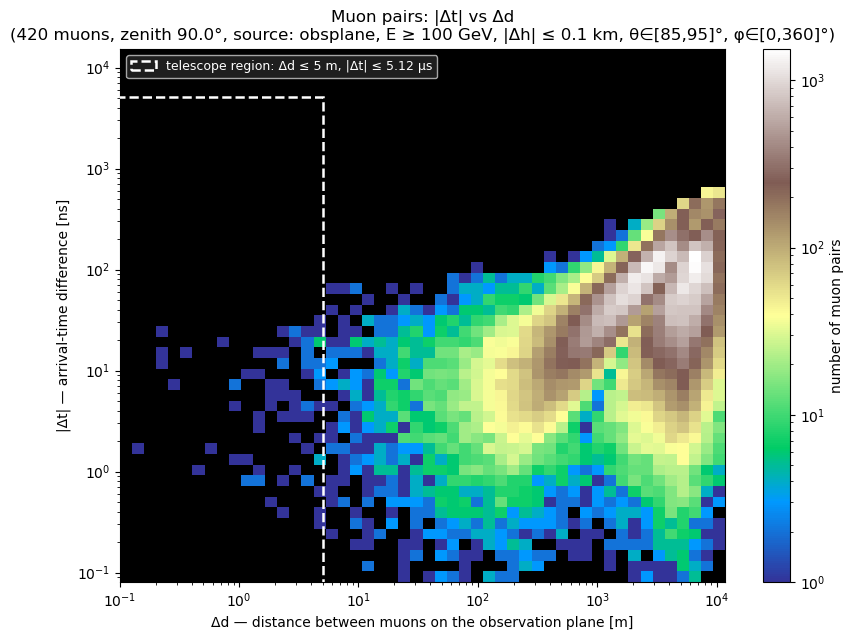

pairs in telescope box (bin-resolution): 60 of 87,347 plotted (0.07%) | full-sample estimate: 60


In [12]:
# Muon pair correlations at the observation plane (log-log), standalone
#   counts of muon pairs: |Δt| vs Δd
# Altitude cut: keep muons with |h_mu - h_tel| <= ALT_WIN_M, where h is the
# altitude above the (curved, spherical) Earth surface.
# Direction cut: keep muons whose per-particle (zenith, azimuth) lies in a
# user-chosen window.
# Reads the CORSIKA 8 output directly:
#   SOURCE = "obsplane" -> <Sim_Folder>/particles/particles.parquet   (x, y on the plane)
#   SOURCE = "3d"       -> <Sim_Folder>/particles_3d/particles_3d.parquet
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ------------------------- input options ---------------------------------
#Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV_h1500_zen92_az270"
Sim_Folder  = "/scratch/general/vast/u1520754/test3d_proton_1e7GeV"

SOURCE      = "obsplane"           # "obsplane" or "3d"

OBS_FILE    = Sim_Folder + "/particles/particles.parquet"
P3D_FILE    = Sim_Folder + "/particles_3d/particles_3d.parquet"
SLICES_YAML = Sim_Folder + "/particles_3d/particles_3d_slices.yaml"

Ground_Height = 1500               # [m] ground / observation level (as in the viewer)
SHELL_TOL_M   = 5.0                # "3d" mode: keep muons with |r - R_ground| < this [m]
TIME_IN_UNIT  = 1.0                # seconds per unit of the time column (C8: seconds -> 1.0)
TIME_UNIT     = "ns"               # plotting unit: "ns", "us", "s"
ZENITH_DEG    = None               # None = estimate from the data; or e.g. 92.0

# --- direction cut (per-particle zenith / azimuth) ---
DIR_CUT     = True
ZEN_MIN_DEG = 85                  # keep muons with zenith in [ZEN_MIN_DEG, ZEN_MAX_DEG] [deg]
ZEN_MAX_DEG = 95
AZ_MIN_DEG  = 0                  # keep muons with azimuth in [AZ_MIN_DEG, AZ_MAX_DEG] [deg]
AZ_MAX_DEG  = 360               # AZ_MIN_DEG > AZ_MAX_DEG -> window wraps through 0 deg
DIR_ACTIVE  = DIR_CUT and (ZEN_MIN_DEG > 0.0 or ZEN_MAX_DEG < 180.0
                           or AZ_MIN_DEG > 0.0 or AZ_MAX_DEG < 360.0)

# --- altitude cut (curved Earth) ---
ALT_CUT     = True
ALT_WIN_M   = 100.0               # keep |h_mu - h_tel| <= this [m]
PLANE_ALT_M = None                 # altitude of the obs-plane tangent point [m]; None = Ground_Height
TEL_ALT_M   = None                 # telescope altitude [m]; None = from plane / YAML
TEL_X_M, TEL_Y_M = 0.0, 0.0        # telescope position in plane coordinates [m] (obsplane mode)

# --- telescope acceptance region (dashed box) ---
SHOW_TEL_BOX  = True
TEL_D_MAX_M   = 5.0               # muon-muon distance range: 0 .. this [m]
TEL_DT_MAX_S  = 5.12e-6            # time-difference range: 0 .. this [s]
TEL_BOX_COLOR = "white"

# --- energy cut ---
E_CUT       = True
E_MIN_GEV   = 100.0                 # keep muons with energy >= this [GeV]
E_COL       = "kinetic_energy"     # column used for the cut ("kinetic_energy" or "energy")
E_IN_GEV    = 1.0                  # GeV per unit of the energy column (CORSIKA 8 writes GeV -> 1.0; if eV use 1e-9)
INCLUDE_TEL_BOX_IN_RANGE = True    # force the plotted range to cover the telescope box
TEL_D_MIN_M  = 0.1                 # lowest distance to display when forcing the box in [m]
TEL_DT_MIN_S = 1e-9                # lowest |Δt| to display when forcing the box in [s]
# ------------------------- analysis options ------------------------------
MAX_MU      = 100000
CHUNK       = 1000
NBINS_D     = 50
NBINS_DT    = 50
D_PCT       = 99.0
DT_PCT      = 99.0
D_LO_PCT    = 0.1
DT_LO_PCT   = 0.1
SHOW_FRONT  = False
USE_LOGNORM = True
SHOW_AS      = "counts"     # "prob"   -> probability
                          # "counts" -> number of muon pairs (full-sample, via pair_w)
                          # "auto"   -> probability, fall back to counts if it can't be computed

PROB_NORM    = "all"      # "all"     -> divide by ALL unique pairs  (sum = fraction in window)
                          # "plotted" -> divide by pairs in the plotted window (sum = 1)
PROB_DENSITY = True      # True -> also divide by the bin area in (ln d, ln dt): density per unit log-area
BG_COLOR = "black"
OUT_PNG2 = Sim_Folder + "/muons_pair_dt_vs_dd_loglog.png"
# -------------------------------------------------------------------------

t_fac = {"ns": 1e9, "us": 1e6, "s": 1.0}[TIME_UNIT]
t_lab = {"ns": "ns", "us": "µs", "s": "s"}[TIME_UNIT]


def read_frame_meta():
    """Bare Earth radius R_E [m] and output origin (telescope position in the root frame)."""
    try:
        import yaml
        m = yaml.safe_load(open(SLICES_YAML))
        return float(m["earth_radius_m"]), np.asarray(m["output_origin_m"], float), True
    except Exception as exc:
        R_E = 6371e3
        print(f"NOTE: cannot read {SLICES_YAML} ({exc}); using R_E = {R_E/1e3:.0f} km")
        return R_E, np.array([0.0, 0.0, R_E + Ground_Height]), False


def report_cut(h, h_tel, keep):
    print(f"altitude cut: h_tel = {h_tel:.1f} m, window ±{ALT_WIN_M:.0f} m -> "
          f"kept {keep.sum():,} of {len(keep):,} muons "
          f"(muon h range {h.min():.1f} .. {h.max():.1f} m)")


def direction_cut_mask(nx, ny, nz):
    """Per-particle (zenith, azimuth) keep-mask from the direction cosines.

    zenith  = arccos(-nz)            (0 deg = straight down, 180 deg = straight up)
    azimuth = atan2(ny, nx) mod 360  (0 = +x, 90 = +y)

    A window with AZ_MIN_DEG > AZ_MAX_DEG is treated as wrapping through 0 deg
    (e.g. 350 .. 10).  Returns a boolean array; prints the surviving count when
    the window is not the full sphere.
    """
    n = len(nx)
    if not DIR_CUT:
        return np.ones(n, dtype=bool)

    nz = np.clip(np.asarray(nz, float), -1.0, 1.0)
    zen = np.degrees(np.arccos(np.clip(-nz, -1.0, 1.0)))
    az = np.degrees(np.arctan2(np.asarray(ny, float),
                               np.asarray(nx, float))) % 360.0

    keep = (zen >= ZEN_MIN_DEG) & (zen <= ZEN_MAX_DEG)
    if AZ_MIN_DEG <= AZ_MAX_DEG:
        keep &= (az >= AZ_MIN_DEG) & (az <= AZ_MAX_DEG)
    else:                                    # window wraps through 0 deg
        keep &= (az >= AZ_MIN_DEG) | (az <= AZ_MAX_DEG)

    if DIR_ACTIVE:
        print(f"direction cut: zen [{ZEN_MIN_DEG:g}, {ZEN_MAX_DEG:g}] deg, "
              f"az [{AZ_MIN_DEG:g}, {AZ_MAX_DEG:g}] deg -> kept "
              f"{keep.sum():,} of {n:,} particles")
    return keep


def load_obsplane():
    cols = pd.read_parquet(OBS_FILE).columns
    lc = {c.lower(): c for c in cols}
    need = ["x", "y", "time", "pdg"]
    miss = [c for c in need if c not in lc]
    if miss:
        raise KeyError(f"{OBS_FILE} lacks columns {miss}; available: {list(cols)}")

    ecol = None
    if E_CUT:
        for cand in (E_COL.lower(), "kinetic_energy", "energy"):
            if cand in lc:
                ecol = lc[cand]; break
        if ecol is None:
            raise KeyError(f"energy cut requested but no energy column found; available: {list(cols)}")

    use = [lc[c] for c in need] + [lc[c] for c in ("nx", "ny", "nz") if c in lc]
    if ecol is not None:
        use.append(ecol)
    df = pd.read_parquet(OBS_FILE, columns=use)
    df.columns = [c.lower() for c in df.columns]
    df = df[np.abs(df["pdg"]) == 13]
    df = df[np.isfinite(df[["x", "y", "time"]]).all(axis=1)]

    if E_CUT and len(df):
        e_gev = df[ecol.lower()].to_numpy(float) * E_IN_GEV
        ke = e_gev >= E_MIN_GEV
        print(f"energy cut: E >= {E_MIN_GEV:g} GeV -> kept {ke.sum():,} of {len(ke):,} muons "
              f"(E range {e_gev.min():.3g} .. {e_gev.max():.3g} GeV)")
        df = df[ke]

    if DIR_CUT and len(df):
        if {"nx", "ny", "nz"} <= set(df.columns):
            df = df[direction_cut_mask(df["nx"].to_numpy(float),
                                       df["ny"].to_numpy(float),
                                       df["nz"].to_numpy(float))]
        else:
            print("direction cut requested but no nx/ny/nz columns; skipped")

    if ALT_CUT and len(df):
        R_E, _, _ = read_frame_meta()
        h_pl = Ground_Height if PLANE_ALT_M is None else PLANE_ALT_M
        R_pl = R_E + h_pl
        x = df["x"].to_numpy(float); y = df["y"].to_numpy(float)
        h_mu  = np.sqrt(R_pl**2 + x**2 + y**2) - R_E
        h_tel = (np.sqrt(R_pl**2 + TEL_X_M**2 + TEL_Y_M**2) - R_E
                 if TEL_ALT_M is None else TEL_ALT_M)
        keep = np.abs(h_mu - h_tel) <= ALT_WIN_M
        report_cut(h_mu, h_tel, keep)
        df = df[keep]

    x = df["x"].to_numpy(float); y = df["y"].to_numpy(float)
    t = df["time"].to_numpy(float) * TIME_IN_UNIT
    zen = None
    if {"nx", "ny", "nz"} <= set(df.columns) and len(df):
        n = df[["nx", "ny", "nz"]].to_numpy(float).mean(axis=0)
        n /= np.linalg.norm(n)
        zen = float(np.degrees(np.arccos(np.clip(-n[2], -1, 1))))
    return x, y, t, zen


def load_3d():
    R_E, ORIGIN_M, _ = read_frame_meta()
    R_M = R_E + Ground_Height
    ecol = E_COL if E_COL in ("kinetic_energy", "energy") else "kinetic_energy"
    base = ["X", "Y", "Z", "time", "pdg"] + ([ecol] if E_CUT else [])
    cols = base + ["nx", "ny", "nz"]
    try:
        df = pd.read_parquet(P3D_FILE, columns=cols)
    except Exception:
        cols = base                                   # direction columns unavailable
        df = pd.read_parquet(P3D_FILE, columns=cols)
    df = df[np.isfinite(df).all(axis=1)]
    T_all = df["time"].to_numpy(float)
    P_all = df[["X", "Y", "Z"]].to_numpy(float)

    # zenith from the shower axis (same recipe as the viewer)
    zen = None
    lin_w = (T_all.max() - T_all.min()) / 1000 * 1.5
    c0 = None
    for t0 in np.linspace(T_all.min(), T_all.max(), 1000):
        m = np.abs(T_all - t0) <= lin_w
        if not m.any():
            continue
        c = P_all[m].mean(axis=0)
        if c0 is None:
            c0 = c
        elif np.linalg.norm(c - c0) > 1.0:
            ez = (c - c0) / np.linalg.norm(c - c0)
            zen = float(np.degrees(np.arccos(np.clip(-ez[2], -1, 1))))
            break

    mu = np.abs(df["pdg"].to_numpy()) == 13
    if E_CUT:
        e_gev = df[ecol].to_numpy(float) * E_IN_GEV
        n0 = mu.sum()
        mu &= e_gev >= E_MIN_GEV
        print(f"energy cut: E >= {E_MIN_GEV:g} GeV -> kept {mu.sum():,} of {n0:,} muon rows")
    if DIR_CUT and {"nx", "ny", "nz"} <= set(df.columns):
        n0 = mu.sum()
        mu &= direction_cut_mask(df["nx"].to_numpy(float),
                                 df["ny"].to_numpy(float),
                                 df["nz"].to_numpy(float))
        if DIR_ACTIVE:
            print(f"   -> muon rows kept: {mu.sum():,} of {n0:,}")
    P, t = P_all[mu], T_all[mu] * TIME_IN_UNIT
    r = np.linalg.norm(P + ORIGIN_M, axis=1)
    keep = np.abs(r - R_M) < SHELL_TOL_M
    P, t, r = P[keep], t[keep], r[keep]
    print(f"3d mode: {keep.sum():,} muon rows within ±{SHELL_TOL_M} m of the ground shell")

    if ALT_CUT and len(P):
        h_mu  = r - R_E
        h_tel = (np.linalg.norm(ORIGIN_M) - R_E) if TEL_ALT_M is None else TEL_ALT_M
        kc = np.abs(h_mu - h_tel) <= ALT_WIN_M
        report_cut(h_mu, h_tel, kc)
        P, t = P[kc], t[kc]

    up = ORIGIN_M / np.linalg.norm(ORIGIN_M)
    ex = np.array([1.0, 0.0, 0.0]) - up[0] * up
    ex /= np.linalg.norm(ex)
    ey = np.cross(up, ex)
    return P @ ex, P @ ey, t, zen


# --- load ----------------------------------------------------------------
if SOURCE == "obsplane":
    xs, ys, ts_s, zen_est = load_obsplane()
elif SOURCE == "3d":
    xs, ys, ts_s, zen_est = load_3d()
else:
    raise ValueError("SOURCE must be 'obsplane' or '3d'")
ts = ts_s * t_fac
zen = ZENITH_DEG if ZENITH_DEG is not None else (zen_est if zen_est is not None else 0.0)
print(f"loaded {len(xs):,} muons ({SOURCE}) | zenith {zen:.1f}°")
if len(xs) < 2:
    raise SystemExit("Fewer than 2 muons - check SOURCE / paths / SHELL_TOL_M / ALT_WIN_M / direction cut.")

# --- subsample -----------------------------------------------------------
rng = np.random.default_rng(1)
N_full = len(xs)
if MAX_MU and N_full > MAX_MU:
    pick = rng.choice(N_full, MAX_MU, replace=False)
    px, py, pt = xs[pick], ys[pick], ts[pick]
else:
    px, py, pt = xs, ys, ts
N = len(px)
pair_w = (N_full * (N_full - 1)) / (N * (N - 1))
n_pairs = N * (N - 1) // 2
print(f"muons used: {N:,} of {N_full:,} | pairs: {n_pairs:,} (weight {pair_w:.3g})")

# --- ranges --------------------------------------------------------------
m = min(200_000, n_pairs)
i = rng.integers(0, N, m); j = rng.integers(0, N, m)
ok = i != j
dd_s = np.hypot(px[i[ok]] - px[j[ok]], py[i[ok]] - py[j[ok]])
dt_s = np.abs(pt[i[ok]] - pt[j[ok]])
dd_s, dt_s = dd_s[dd_s > 0], dt_s[dt_s > 0]

D_MIN  = float(np.percentile(dd_s, D_LO_PCT))
D_MAX  = float(np.percentile(dd_s, D_PCT)) * 1.05
DT_MIN = float(np.percentile(dt_s, DT_LO_PCT))
DT_MAX = float(np.percentile(dt_s, DT_PCT)) * 1.05
if SHOW_TEL_BOX and INCLUDE_TEL_BOX_IN_RANGE:
    tel_dt_max = TEL_DT_MAX_S * t_fac                    # box upper |Δt| in plotting unit
    D_MIN  = min(D_MIN,  TEL_D_MIN_M)
    DT_MIN = min(DT_MIN, TEL_DT_MIN_S * t_fac)
    D_MAX  = max(D_MAX,  TEL_D_MAX_M * 3)                # keep some margin above the box
    DT_MAX = max(DT_MAX, tel_dt_max * 3)
    print(f"range widened to include telescope box: "
          f"Δd {D_MIN:.3g}..{D_MAX:.3g} m, |Δt| {DT_MIN:.3g}..{DT_MAX:.3g} {t_lab}")
d_ed  = np.geomspace(D_MIN,  D_MAX,  NBINS_D + 1)
dt_ed = np.geomspace(DT_MIN, DT_MAX, NBINS_DT + 1)
print(f"Δd range: {D_MIN:.3g} .. {D_MAX:.3g} m | |Δt| range: {DT_MIN:.3g} .. {DT_MAX:.3g} {t_lab}")

# --- chunked histogram over all unique pairs -----------------------------
H = np.zeros((NBINS_D, NBINS_DT))
n_used = 0
for i0 in range(0, N, CHUNK):
    i1 = min(i0 + CHUNK, N)
    dx = px[i0:i1, None] - px[None, i0:]
    dy = py[i0:i1, None] - py[None, i0:]
    dt = np.abs(pt[i0:i1, None] - pt[None, i0:])
    upper = np.arange(i0, N)[None, :] > np.arange(i0, i1)[:, None]
    h = np.histogram2d(np.hypot(dx, dy)[upper], dt[upper], bins=[d_ed, dt_ed])[0]
    H += h
    n_used += h.sum()

# --- counts -> probability, with fall-back to counts ----------------------
def make_prob():
    if PROB_NORM == "plotted":
        denom = n_used
        lab = "probability (normalised to pairs in the window)"
    else:
        denom = n_pairs
        lab = "probability (fraction of all muon pairs)"
    if denom <= 0:
        raise ValueError("no pairs to normalise by")
    Pm = H / denom                                   # pair_w cancels
    if PROB_DENSITY:
        lnd  = np.diff(np.log(d_ed))[:, None]
        lndt = np.diff(np.log(dt_ed))[None, :]
        Pm = Pm / (lnd * lndt)
        lab = "probability density per unit ln(Δd) ln(|Δt|)"
    if not np.isfinite(Pm).all() or Pm.max() <= 0:
        raise ValueError("probability map is empty / non-finite")
    return Pm, lab

H_counts = H * pair_w                                # counts rescaled to the full sample
mode = SHOW_AS.lower()
if mode == "counts":
    A, clab = H_counts, "number of muon pairs"
else:
    try:
        A, clab = make_prob()
        print(f"sum of plotted probabilities = {A.sum():.4g} "
              f"({100*n_used/n_pairs:.1f}% of pairs are inside the plotted window)")
    except Exception as exc:
        if mode == "prob":
            raise
        print(f"NOTE: probability not available ({exc}); falling back to number of pairs")
        A, clab = H_counts, "number of muon pairs"

# --- plot ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 6.5))
c_unit = 299_792_458.0 / t_fac

Am = np.ma.masked_equal(A.T, 0)
norm = None
if USE_LOGNORM and Am.count():
    vmin = Am.min()
    norm = LogNorm(vmin=vmin, vmax=max(Am.max(), vmin * 10))
pcm = ax.pcolormesh(d_ed, dt_ed, Am, cmap="terrain", shading="flat", norm=norm)
plt.colorbar(pcm, ax=ax).set_label(clab)

if SHOW_FRONT:
    s = abs(np.sin(np.radians(zen)))
    d_line = np.geomspace(D_MIN, D_MAX, 200)
    ax.plot(d_line, d_line * s / c_unit, "r--", lw=1.2,
            label=fr"flat front: $|\Delta t| = \Delta d\,|\sin\theta|/c$ (θ={zen:.1f}°)")
    ax.legend(loc="upper left", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(D_MIN, D_MAX); ax.set_ylim(DT_MIN, DT_MAX)
ax.set_xlabel("Δd — distance between muons on the observation plane [m]")
ax.set_ylabel(f"|Δt| — arrival-time difference [{t_lab}]")
ax.set_facecolor(BG_COLOR)
if SHOW_TEL_BOX:
    from matplotlib.patches import Rectangle
    tel_dt_max = TEL_DT_MAX_S * t_fac                    # convert s -> plotting unit
    # log axes can't start at 0: draw from well below the axis limits, the view clips it
    x0, y0 = D_MIN * 1e-3, DT_MIN * 1e-3
    rect = Rectangle((x0, y0), TEL_D_MAX_M - x0, tel_dt_max - y0,
                     fill=False, edgecolor=TEL_BOX_COLOR, linestyle="--", linewidth=1.8,
                     label=f"telescope region: Δd ≤ {TEL_D_MAX_M:g} m, "
                           f"|Δt| ≤ {TEL_DT_MAX_S*1e6:g} µs",
                     zorder=5)
    ax.add_patch(rect)
    ax.legend(loc="upper left", fontsize=9, facecolor="0.15", labelcolor="white")
cut_txt = ""
if E_CUT:   cut_txt += f", E ≥ {E_MIN_GEV:g} GeV"
if ALT_CUT: cut_txt += f", |Δh| ≤ {ALT_WIN_M/1e3:g} km"
if DIR_ACTIVE:
    cut_txt += (f", θ∈[{ZEN_MIN_DEG:g},{ZEN_MAX_DEG:g}]°, "
                f"φ∈[{AZ_MIN_DEG:g},{AZ_MAX_DEG:g}]°")
ax.set_title(f"Muon pairs: |Δt| vs Δd\n({N_full:,} muons, zenith {zen:.1f}°, "
             f"source: {SOURCE}{cut_txt})", fontsize=12)
plt.tight_layout()
plt.savefig(OUT_PNG2, dpi=150)
print(f"saved: {OUT_PNG2}")
plt.show()
if SHOW_TEL_BOX:
    tel_dt_max = TEL_DT_MAX_S * t_fac
    id_ = d_ed[1:]  <= TEL_D_MAX_M
    it_ = dt_ed[1:] <= tel_dt_max
    n_box = H[np.ix_(id_, it_)].sum()
    print(f"pairs in telescope box (bin-resolution): {n_box:,.0f} of {n_used:,.0f} plotted "
          f"({100*n_box/max(n_used,1):.2f}%) | full-sample estimate: {n_box*pair_w:,.0f}")


In [14]:
# Shower viewer - 2x2 animated panels, CUMULATIVE (persistent) animation
#   (1,1) global X-Z          (1,2) global Y-Z
#   (2,1) selectable          (2,2) particle counts vs time (3 components)
#         LAT_AXIS = "x"  -> z' along axis vs x'      (longitudinal)
#         LAT_AXIS = "y"  -> z' along axis vs y'      (longitudinal)
#         LAT_AXIS = "xy" -> X global vs Y global     (plan view)
#
#   Animation model
#   ---------------
#   * the figure starts EMPTY (no particle drawn at all);
#   * while playing, the particles of the current time bin appear BRIGHT;
#   * they STAY on screen afterwards as a dim "history" trail;
#   * the history is a fixed-budget random sample of the shower (DIM_MAX_PER_GROUP
#     per group), stored in the HTML only ONCE and split into HIST_COHORTS time
#     cohorts; the frames only toggle each cohort's visibility (a few booleans),
#     so the file size and the rendering cost stay constant instead of growing
#     with the shower.  Scrubbing the slider backwards/forwards always shows the
#     correct accumulated state.
#
#   The Earth's surface (sphere of radius R_M + Ground_Height) and the histogram
#   spectra are re-asserted in EVERY frame and the frames use redraw=True, so the
#   Earth never disappears and the histogram panel is always drawn.
#
# Optimised for HTML size and render speed:
#   * float32 arrays -> plotly >= 6 stores them base64-encoded (not JSON text)
#   * no per-point strings; numeric customdata only (and optional)
#   * bounded number of animated points (ANIM_MAX) and of history points
#   * plain SVG Scatter: VERIFIED that Scattergl traces do NOT refresh during
#     frame animation (headless-Chrome test: stale with redraw=False, blank with
#     redraw=True), so WebGL is opt-in only (USE_GL).
# =====================================================================
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def get_particle_name(pdg):
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")


def get_particle_group(pdg):
    """Colour group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"


# ---------------------------------------------------------------
# Settings
# ---------------------------------------------------------------
#Sim_Folder  = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV_h1500_zen92_az270"
#Sim_Folder = "/scratch/general/vast/u1520754/test3d_proton_1e4GeV"
#Sim_Folder = "/scratch/general/vast/u1520754/test3d_gamma_1e4GeV"
# Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_muon"
Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/cherenkov_hits"
path        = Sim_Folder + "/particles_3d/particles_3d.parquet"
SLICES_YAML = Sim_Folder + "/particles_3d/particles_3d_slices.yaml"
OUT_HTML    = Sim_Folder + "/shower_coords.html"
SAVE_HTML   = True
Ground_Height = 1500                         # height of the drawn ground level [m]
R_EARTH     = 6371e3 + Ground_Height         # fallback Earth radius [m]
E_UNIT      = "GeV"
Z_MIN_KM    = -5# None      # lower limit of the Z axis [km]; None = automatic

nsteps       = 100         # number of time bins (slider frames = nsteps + 1, incl. "start")
TIME_MODE    = "linear"    # "quantile" = equal #particles per frame, "linear" = equal dt
LAT_PCT      = 90          # longitudinal panels: lateral range = this percentile of |lat|
GLOBAL_PCT   = 100         # percentile clip for the two global panels (100 = full range)
EQUAL_ASPECT = False       # True -> 1:1 data units in the two global panels / plan view
START_AT_MAX = False       # True -> start with the state at the shower maximum
FRAME_MS     = 40          # animation speed [ms per frame]

# --- HTML size / rendering speed ---
ANIM_MAX          = 30_000   # particles in the bright (current-bin) layer; None = keep all
DIM_MAX_PER_GROUP = 1_200    # particles per group in the persistent (dim) history layer
HIST_COHORTS      = 12       # time chunks of the history layer (visibility toggled per frame)
BRIGHT_SIZE, DIM_SIZE, DIM_OPACITY = 4, 3, 0.3
USE_GL            = False    # True -> Scattergl (see the note in the header; NOT recommended)
HOVER_DETAIL      = True     # True -> add [E_kin, t] (and PDG for the history) to the hover
REDRAW_FRAMES     = True     # True -> full re-render of every trace on each frame.  This is what
                             # keeps the static traces (Earth fill, histogram spectra) painted
                             # during playback.  False = faster, but they may drop out.

# --- bottom-right panel ---
HIST_LOG_Y = True            # log-scale the counts axis
HIST_MODE  = "per_bin"       # "per_bin" = particles per time bin, "cumulative"

# --- Earth surface (drawn in the three particle panels) ---
SHOW_EARTH        = True
SHOW_EARTH_LONG   = False    # draw the Earth band in the longitudinal panel
EARTH_FILL        = "rgba(139, 90, 43, 0.55)"   # brown, semi-transparent
EARTH_XY_FILL     = "rgba(139, 90, 43, 0.30)"   # plan view: ground is the backdrop
EARTH_LINE_COLOR  = "#C68642"                   # lighter brown for the surface line
EARTH_DEPTH_FRAC  = 0.18     # filled depth below the surface = fraction of the data span
EARTH_NPTS        = 400      # points per surface profile

LAT_AXIS = "xy"      # "x" -> z' vs x'   "y" -> z' vs y'   "xy" -> X global vs Y global

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
cols = ["X", "Y", "Z", "time", "kinetic_energy", "pdg"]
df = pd.read_parquet(path, columns=cols)
df = df[np.isfinite(df[cols]).all(axis=1)].reset_index(drop=True)
df["name"]  = df["pdg"].map(get_particle_name)
df["group"] = df["pdg"].map(get_particle_group)

# frame metadata: R_E and the origin of the global X/Y/Z columns
try:
    import yaml
    _m = yaml.safe_load(open(SLICES_YAML))
    R_M, ORIGIN_M = float(_m["earth_radius_m"]), np.asarray(_m["output_origin_m"], float)
    R_M = R_M + Ground_Height
    print(f"frame: R_E = {R_M/1e3:.3f} km | output origin = {ORIGIN_M} m "
          f"(X/Y/Z are telescope-centred; ground level = z = {(R_M-ORIGIN_M[2])/1e3:.1f} km)")
except Exception as exc:
    R_M, ORIGIN_M = R_EARTH, np.array([0.0, 0.0, R_EARTH])
    print(f"NOTE: cannot read {SLICES_YAML} ({exc}); using R_E = {R_EARTH/1e3:.0f} km")

T      = df["time"].to_numpy(np.float64)
PDG    = df["pdg"].to_numpy()
GROUPS = df["group"].to_numpy()
EK     = df["kinetic_energy"].to_numpy().astype(np.float32)

# global coordinates (telescope-centred, as written by CORSIKA 8) in km
XG = (df["X"].to_numpy(np.float64) / 1e3).astype(np.float32)
YG = (df["Y"].to_numpy(np.float64) / 1e3).astype(np.float32)
ZG = (df["Z"].to_numpy(np.float64) / 1e3).astype(np.float32)
print("rows:", len(df), "| t range [s]:", T.min(), "->", T.max())
print("X global [km] %.3f .. %.3f | Y global [km] %.3f .. %.3f | Z global [km] %.3f .. %.3f"
      % (XG.min(), XG.max(), YG.min(), YG.max(), ZG.min(), ZG.max()))

# ---------------------------------------------------------------
# 2) Colours: one per group
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±":      "#BBACED",
    "e±":      "#D4F30A",
    "γ":       "#F5FAF8",
    "τ±":      "#4CC804",
    "hadrons": "#009E73",
    "ν":       "#DDDDDD",
}
ORDER  = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]
groups = [g for g in ORDER if g in set(GROUPS)]
group_idx = {g: np.flatnonzero(GROUPS == g) for g in groups}

print("Legend (group -> colour):")
for g in groups:
    print(f"  {g:<8} -> {GROUP_COLOR[g]}  ({len(group_idx[g])} rows)")

# ---------------------------------------------------------------
# 3) Shower axis (first two frames with >1 m centroid separation)
# ---------------------------------------------------------------
Pm = np.column_stack([df["X"].to_numpy(np.float64),
                      df["Y"].to_numpy(np.float64),
                      df["Z"].to_numpy(np.float64)])          # [m]

lin_times = np.linspace(T.min(), T.max(), 1000)
lin_w = (T.max() - T.min()) / 1000 * 1.5
c0 = c1 = None
for t0 in lin_times:
    m = np.abs(T - t0) <= lin_w
    if not m.any():
        continue
    c = Pm[m].mean(axis=0)
    if c0 is None:
        c0 = c
    elif np.linalg.norm(c - c0) > 1.0:
        c1 = c
        break
ez = (c1 - c0); ez /= np.linalg.norm(ez)
ref = np.array([0.0, 0.0, 1.0]) if abs(ez[2]) < 0.999 else np.array([1.0, 0.0, 0.0])
ex = np.cross(ref, ez); ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
zen = np.degrees(np.arccos(np.clip(-ez[2], -1, 1)))
azi = np.degrees(np.arctan2(ez[1], ez[0]))
print(f"axis ez = {ez.round(4)}  zenith {zen:.1f}°, azimuth {azi:.1f}°")

Prel = Pm - c0
SU = (Prel @ ex).astype(np.float32)             # x' [m]
SV = (Prel @ ey).astype(np.float32)             # y' [m]
SW = (Prel @ ez / 1e3).astype(np.float32)       # z' along axis [km]
SR = np.maximum(np.hypot(SU, SV), 1e-2)         # r [m]

# --- which quantity goes on the vertical axis of panel (2,1)? ---
if LAT_AXIS not in ("x", "y", "xy"):
    raise ValueError(f"LAT_AXIS must be 'x', 'y' or 'xy', got {LAT_AXIS!r}")
LONG_MODE = LAT_AXIS in ("x", "y")            # (2,1) = longitudinal z' vs lateral
if LONG_MODE:
    SLAT, lat_name = (SU, "x′") if LAT_AXIS == "x" else (SV, "y′")
    lat  = float(np.percentile(np.abs(SLAT), LAT_PCT)) * 1.1
    LAT  = [-lat, lat]
    P21  = (2, 1, SW, SLAT, f"z′ = %{{x:.3f}} km<br>{lat_name} = %{{y:.1f}} m")
    P21_TITLE = f"Longitudinal vs {lat_name}"
    print(f"panel (2,1): longitudinal z′ vs {lat_name} (lateral range ±{lat:.1f} m)")
else:                                           # "xy": plan view, both axes global
    SLAT, lat_name, LAT, lat = None, None, None, None
    P21  = (2, 1, XG, YG, "X = %{x:.3f} km<br>Y = %{y:.3f} km")
    P21_TITLE = "Global X-Y (plan view)"
    print("panel (2,1): global X vs global Y (plan view)")

# ---------------------------------------------------------------
# 4) Time bins
# ---------------------------------------------------------------
if TIME_MODE == "quantile":
    edges = np.unique(np.quantile(T, np.linspace(0, 1, nsteps + 1)))
else:
    edges = np.linspace(T.min(), T.max(), nsteps + 1)
nbins  = len(edges) - 1
BIN    = np.clip(np.searchsorted(edges, T, side="right") - 1, 0, nbins - 1)
labels = [f"{0.5*(edges[k]+edges[k+1])*1e6:.2f} µs" for k in range(nbins)]
names  = [f"f{k}" for k in range(nbins)]
bin_totals = np.bincount(BIN, minlength=nbins)
k0 = int(np.argmax(bin_totals)) if START_AT_MAX else 0      # 0 = empty "start" state

# ---------------------------------------------------------------
# 5) Sub-sampling
#    * anim_idx  : particles used by the bright (current-bin) layer
#    * dim_idx   : subset of anim_idx -> the persistent history layer, split into
#                  HIST_COHORTS time cohorts whose visibility the frames toggle
# ---------------------------------------------------------------
rng = np.random.default_rng(0)

if ANIM_MAX and len(df) > ANIM_MAX:
    anim_idx = {}
    for g in groups:
        idx = group_idx[g]
        share = max(200, int(round(ANIM_MAX * len(idx) / len(df))))
        anim_idx[g] = rng.choice(idx, min(share, len(idx)), replace=False)
else:
    anim_idx = {g: group_idx[g] for g in groups}

anim_bins = {}
for g in groups:
    idx = anim_idx[g]
    order = idx[np.argsort(BIN[idx], kind="stable")]
    cuts = np.searchsorted(BIN[order], np.arange(nbins + 1))
    anim_bins[g] = [order[cuts[k]:cuts[k+1]] for k in range(nbins)]

anim_total = sum(len(v) for v in anim_idx.values())

dim_idx = {g: (anim_idx[g] if len(anim_idx[g]) <= DIM_MAX_PER_GROUP
               else rng.choice(anim_idx[g], DIM_MAX_PER_GROUP, replace=False))
           for g in groups}
dim_total = sum(len(v) for v in dim_idx.values())
print(f"sampling: bright layer {anim_total:,} particles | history layer {dim_total:,} "
      f"in {HIST_COHORTS} time cohorts")

# bin -> cohort (uniform in time) and the per-cohort index sets
coh_of_bin = (np.arange(nbins) * HIST_COHORTS) // nbins
dim_coh = {}
for g in groups:
    idx = dim_idx[g]
    cidx = coh_of_bin[BIN[idx]]
    dim_coh[g] = [idx[cidx == ch] for ch in range(HIST_COHORTS)]


def vis_count(k):
    """Number of history cohorts fully covered by bins 0..k (k = -1 -> none)."""
    return 0 if k < 0 else ((k + 1) * HIST_COHORTS) // nbins


# ---------------------------------------------------------------
# 5b) Species (exact PDG codes) present in each group's samples
# ---------------------------------------------------------------
species = {}
for g in groups:
    present = set(np.unique(PDG[anim_idx[g]])) | set(np.unique(PDG[dim_idx[g]]))
    species[g] = sorted(present, key=lambda p: (abs(int(p)), int(p)))
    print(f"  {g:<8}: " + ", ".join(get_particle_name(int(p)) for p in species[g]))


def hover_tag(p):
    return f"<b>{get_particle_name(int(p))}</b>  (PDG {int(p)})<br>"


# ---------------------------------------------------------------
# 6) Bottom-right: particle counts per time bin, 3 components
# ---------------------------------------------------------------
ABS = np.abs(PDG)
COMPONENTS = [
    ("EM (e±, γ)",  "#D4F30A", np.isin(ABS, (11, 22))),
    ("muonic (μ±)", "#BBACED", ABS == 13),
    ("hadronic",    "#009E73", ~np.isin(ABS, (11, 13, 22))),
]

u_edges = edges * 1e6
hist_x, hist_y = {}, {}
for label, color, mask in COMPONENTS:
    counts = np.bincount(BIN[mask], minlength=nbins).astype(float)
    if HIST_MODE == "cumulative":
        counts = np.cumsum(counts)
    hist_x[label] = 0.5 * (u_edges[:-1] + u_edges[1:])
    hist_y[label] = counts
    print(f"  component {label:<12} total {int(mask.sum()):>7,} particles")

# ---------------------------------------------------------------
# 7) Axis ranges + Earth-surface profiles
# ---------------------------------------------------------------
def robust_range(a, pct=GLOBAL_PCT, pad=0.04):
    lo = float(np.percentile(a, 100 - pct))
    hi = float(np.percentile(a, pct))
    if hi <= lo:
        hi = lo + 1.0
    d = (hi - lo) * pad
    return [lo - d, hi + d]


RXG, RZG = robust_range(XG), robust_range(ZG)
RYG = robust_range(YG)
LON = [0.0, float(np.percentile(SW, 99.5)) * 1.05]      # only used in the longitudinal mode

# --- Earth surface: sphere of radius R_M centred at the root origin, which sits at
#     (-output_origin) in the plotted (telescope-centred) frame.
C_E = -ORIGIN_M / 1e3                                   # Earth centre in the plot frame [km]
R_K = R_M / 1e3                                         # Earth radius [km]


def z_surface(x_km, y_km):
    """Height [km] of the ground-level sphere at the horizontal position (x, y) [km]."""
    r2 = (R_K**2 - (np.asarray(x_km, dtype=float) - C_E[0])**2
          - (np.asarray(y_km, dtype=float) - C_E[1])**2)
    return C_E[2] + np.sqrt(np.maximum(r2, 0.0))


x_c, y_c = float(np.median(XG)), float(np.median(YG))   # profile line through the shower
earth = {}                                              # panel key -> (x, y) of the surface
earth_zg = earth_left = None

if SHOW_EARTH:
    # (1,1) X-Z : ground profile along x at the shower's y
    gx = np.linspace(RXG[0], RXG[1], EARTH_NPTS)
    earth[(1, 1)] = (gx, z_surface(gx, y_c))
    # (1,2) Y-Z : ground profile along y at the shower's x
    gy = np.linspace(RYG[0], RYG[1], EARTH_NPTS)
    earth[(1, 2)] = (gy, z_surface(x_c, gy))

    if LONG_MODE:
        # (2,1) z'-x' : the lateral axis is purely horizontal (ex is horizontal), so the
        # ground of the shower-frame cross-section (the plane holding the axis and the
        # local vertical) projects onto a LINE of constant z' -- the axial position where
        # the shower axis meets the Earth.  The Earth is drawn as a band on the side
        # towards which the altitude decreases (left for upgoing, right for downgoing).
        P0_root = c0 + ORIGIN_M                                 # axis point, root frame [m]
        b_ax = float(P0_root @ ez)
        disc_ax = max(b_ax**2 - float(P0_root @ P0_root) + R_M**2, 0.0)
        s1, s2 = -b_ax - np.sqrt(disc_ax), -b_ax + np.sqrt(disc_ax)
        z_g = (s1 if abs(s1) < abs(s2) else s2) / 1e3           # [km]
        earth_zg, earth_left = z_g, bool(ez[2] > 0.0)
        if SHOW_EARTH_LONG:
            pad = EARTH_DEPTH_FRAC * (LON[1] - LON[0])
            LON = ([min(LON[0], z_g) - pad, LON[1]] if earth_left
                   else [LON[0], max(LON[1], z_g) + pad])
        print("Earth: ground level z = %.3f..%.3f km (X-Z) / %.3f..%.3f km (Y-Z); axis "
              "crosses the ground at z' = %.3f km -> band on the %s"
              % (earth[(1, 1)][1].min(), earth[(1, 1)][1].max(),
                 earth[(1, 2)][1].min(), earth[(1, 2)][1].max(), z_g,
                 "left" if earth_left else "right"))
    else:
        print("Earth: ground level z = %.3f..%.3f km (X-Z) / %.3f..%.3f km (Y-Z); "
              "plan view -> brown backdrop in the X-Y panel"
              % (earth[(1, 1)][1].min(), earth[(1, 1)][1].max(),
                 earth[(1, 2)][1].min(), earth[(1, 2)][1].max()))

    # keep the ground (plus a slab below it) inside the vertical range
    z_lo = min(RZG[0], float(earth[(1, 1)][1].min()), float(earth[(1, 2)][1].min()))
    RZG = [z_lo - EARTH_DEPTH_FRAC * (RZG[1] - RZG[0]), RZG[1]]
if Z_MIN_KM is not None:
    RZG[0] = Z_MIN_KM

if LONG_MODE:
    print(f"ranges: X {RXG[0]:.2f}..{RXG[1]:.2f} km | Y {RYG[0]:.2f}..{RYG[1]:.2f} km | "
          f"Z {RZG[0]:.2f}..{RZG[1]:.2f} km | lateral ±{lat:.1f} m | z′ {LON[0]:.1f}..{LON[1]:.1f} km")
else:
    print(f"ranges: X {RXG[0]:.2f}..{RXG[1]:.2f} km | Y {RYG[0]:.2f}..{RYG[1]:.2f} km | "
          f"Z {RZG[0]:.2f}..{RZG[1]:.2f} km")

# ---------------------------------------------------------------
# 8) Figure
# ---------------------------------------------------------------
Xlab, Ylab, Zlab = "X global [km]", "Y global [km]", "Z global [km]"
PANELS = [  # (row, col, x, y, hovertemplate)
    (1, 1, XG, ZG, "X = %{x:.3f} km<br>Z = %{y:.3f} km"),
    (1, 2, YG, ZG, "Y = %{x:.3f} km<br>Z = %{y:.3f} km"),
    P21,
]
SCAT = go.Scattergl if USE_GL else go.Scatter

fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                    subplot_titles=("Global X-Z", "Global Y-Z", P21_TITLE,
                                    f"Particles per time bin ({HIST_MODE})"))


def ground_fill(xs, ys, ybottom, name="Earth (ground level)", show=False):
    """Filled brown slab: the surface profile closed onto the bottom of the panel."""
    return go.Scatter(
        x=np.concatenate([np.asarray(xs), np.asarray(xs)[::-1]]),
        y=np.concatenate([np.asarray(ys), np.full(len(ys), ybottom)]),
        mode="lines", name=name, legendgroup="earth", showlegend=show,
        line=dict(color=EARTH_LINE_COLOR, width=1.5),
        fill="toself", fillcolor=EARTH_FILL, hoverinfo="skip")


# the Earth first, so the particles are drawn on top of it.
# earth_idx / spec_idx are re-asserted in EVERY frame, which is what stops the
# Earth fill and the histogram spectra from dropping out during the animation.
earth_idx = []
if SHOW_EARTH:
    fig.add_trace(ground_fill(*earth[(1, 1)], RZG[0], show=True), row=1, col=1)
    earth_idx.append(len(fig.data) - 1)
    fig.add_trace(ground_fill(*earth[(1, 2)], RZG[0]), row=1, col=2)
    earth_idx.append(len(fig.data) - 1)
    if LONG_MODE and SHOW_EARTH_LONG:
        x_edge = LON[0] if earth_left else LON[1]
        fig.add_trace(go.Scatter(
            x=[earth_zg, earth_zg, x_edge, x_edge],
            y=[LAT[0], LAT[1], LAT[1], LAT[0]],
            mode="lines", name="Earth (ground level)", legendgroup="earth", showlegend=False,
            line=dict(color=EARTH_LINE_COLOR, width=1.5),
            fill="toself", fillcolor=EARTH_FILL, hoverinfo="skip"), row=2, col=1)
        earth_idx.append(len(fig.data) - 1)
    elif not LONG_MODE:
        # plan view: looking straight down, the ground is the whole background
        fig.add_trace(go.Scatter(
            x=[RXG[0], RXG[1], RXG[1], RXG[0]],
            y=[RYG[0], RYG[0], RYG[1], RYG[1]],
            mode="lines", name="Earth (ground level)", legendgroup="earth", showlegend=False,
            line=dict(color=EARTH_LINE_COLOR, width=1.5),
            fill="toself", fillcolor=EARTH_XY_FILL, hoverinfo="skip"), row=2, col=1)
        earth_idx.append(len(fig.data) - 1)


def tmpl_bright(panel_hover, p):
    """Hover for the bright (current time bin) traces; customdata = [E_kin, t]."""
    s = hover_tag(p) + panel_hover
    if HOVER_DETAIL:
        s += f"<br>E_kin = %{{customdata[0]:.4g}} {E_UNIT}<br>t = %{{customdata[1]:.3f}} µs"
    return s + "<extra></extra>"


def tmpl_hist(panel_hover, g):
    """Hover for the persistent history traces; customdata = [pdg, E_kin, t]."""
    s = f"<b>{g}</b>"
    if HOVER_DETAIL:
        s += ("<br>PDG = %{customdata[0]:.0f}"
              f"<br>E_kin = %{{customdata[1]:.4g}} {E_UNIT}"
              "<br>t = %{customdata[2]:.3f} µs")
    return s + "<br>" + panel_hover + "<extra></extra>"


bright_meta = []      # (trace index, group, pdg, row, col, x-array, y-array)
cohort_meta = []      # (trace index, group, cohort)
hist_idx    = []      # "now" diamond traces

for g in groups:
    c = GROUP_COLOR[g]
    # legend-only entry (one per group)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                             showlegend=True, hoverinfo="skip",
                             marker=dict(size=12, color=c)), row=1, col=1)

    # --- bright layer: current time bin, one trace per species and panel, starts empty
    for p in species[g]:
        for r_, c_, A, B, hov_t in PANELS:
            fig.add_trace(SCAT(x=[], y=[], mode="markers", name=get_particle_name(int(p)),
                               legendgroup=g, showlegend=False,
                               hovertemplate=tmpl_bright(hov_t, p),
                               marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0)),
                          row=r_, col=c_)
            bright_meta.append((len(fig.data) - 1, g, p, r_, c_, A, B))

    # --- persistent history layer: static data, visibility toggled by the frames
    for ch in range(HIST_COHORTS):
        sel = dim_coh[g][ch]
        cd  = (np.column_stack([PDG[sel], EK[sel], T[sel] * 1e6]).astype(np.float32)
               if HOVER_DETAIL else None)
        for r_, c_, A, B, hov_t in PANELS:
            fig.add_trace(SCAT(x=A[sel], y=B[sel], mode="markers", name=g, legendgroup=g,
                               showlegend=False, customdata=cd, visible=False,
                               hovertemplate=tmpl_hist(hov_t, g),
                               marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY)),
                          row=r_, col=c_)
            cohort_meta.append((len(fig.data) - 1, g, ch))

# bottom-right: static component spectra + "now" diamonds (filled by the frames)
spec_idx = []
for label, color, _ in COMPONENTS:
    fig.add_trace(go.Scatter(x=hist_x[label], y=hist_y[label], mode="lines+markers",
                             name=label, legendgroup="hist", showlegend=True,
                             line=dict(color=color, width=2, shape="hv"),
                             marker=dict(size=5, color=color),
                             hovertemplate=label + "<br>t = %{x:.2f} µs<br>N = %{y:.0f}<extra></extra>"),
                  row=2, col=2)
    spec_idx.append(len(fig.data) - 1)
for label, color, _ in COMPONENTS:
    fig.add_trace(go.Scatter(x=[hist_x[label][0]], y=[hist_y[label][0]], mode="markers",
                             name=label + " (now)", legendgroup="hist", showlegend=False,
                             marker=dict(size=13, color=color, symbol="diamond",
                                         line=dict(color="white", width=1)),
                             hoverinfo="skip"), row=2, col=2)
    hist_idx.append(len(fig.data) - 1)

print(f"traces: {len(fig.data)} = {len(bright_meta)} bright + {len(cohort_meta)} history "
      f"cohorts + {len(hist_idx)} histogram markers + {len(earth_idx)} Earth "
      f"+ {len(spec_idx)} spectra + legend  | frames re-assert the Earth/spectra, "
      f"redraw={bool(USE_GL or REDRAW_FRAMES)}")

# ---------------------------------------------------------------
# 9) Frames - one "start" frame (nothing drawn) + one frame per time bin
#    A frame carries (a) the x/y of the current bin's particles, (b) the visibility
#    of every history cohort and (c) a re-assertion of the Earth and histogram
#    spectra, so scrubbing in both directions works and nothing ever drops out.
# ---------------------------------------------------------------
def bin_xy(g, p, k, A, B):
    """x, y and customdata of species p of group g arriving in bin k (k = -1 -> empty)."""
    if k < 0:
        s = np.empty(0, dtype=int)
    else:
        s_all = anim_bins[g][k]
        s = s_all[PDG[s_all] == p]
    cd = np.column_stack([EK[s], T[s] * 1e6]).astype(np.float32) if HOVER_DETAIL else None
    return A[s], B[s], cd


def frame_data(k):
    """Data objects of frame k (k = -1 -> the empty start state)."""
    nvis = vis_count(k)
    fdata = []
    for _, g, p, _, _, A, B in bright_meta:                 # current time bin
        x, y, cd = bin_xy(g, p, k, A, B)
        fdata.append(SCAT(x=x, y=y, customdata=cd))
    for _, g, ch in cohort_meta:                            # persistent history
        fdata.append(go.Scatter(visible=bool(ch < nvis)))
    for label, _, _ in COMPONENTS:                          # "now" diamonds
        kk = 0 if k < 0 else k          # the histogram always shows a position
        fdata.append(go.Scatter(x=[hist_x[label][kk]], y=[hist_y[label][kk]]))
    for _ in earth_idx:                                     # keep the Earth painted
        fdata.append(go.Scatter(visible=True))
    for _ in spec_idx:                                      # keep the spectra painted
        fdata.append(go.Scatter(visible=True))
    return fdata


anim = ([i for i, *_ in bright_meta] + [i for i, *_ in cohort_meta] + hist_idx
        + earth_idx + spec_idx)
frames = [go.Frame(data=frame_data(-1), traces=anim, name="start")]
frames += [go.Frame(data=frame_data(k), traces=anim, name=names[k]) for k in range(nbins)]
fig.frames = frames

# START_AT_MAX: pre-fill the initial (pre-animation) state with everything up to bin k0-1
if k0 > 0:
    for obj, idx in zip(frame_data(k0 - 1), anim):
        if obj.x is not None:          fig.data[idx].x = obj.x
        if obj.y is not None:          fig.data[idx].y = obj.y
        if obj.customdata is not None: fig.data[idx].customdata = obj.customdata
        if obj.visible is not None:    fig.data[idx].visible = obj.visible

# ---------------------------------------------------------------
# 10) Axes
# ---------------------------------------------------------------
ax = dict(gridcolor="#333333", zerolinecolor="#777777", color="white",
          showline=True, linecolor="gray", mirror=True)
fig.update_xaxes(**ax); fig.update_yaxes(**ax)

fig.update_xaxes(title_text=Xlab, range=RXG, row=1, col=1)
fig.update_yaxes(title_text=Zlab, range=RZG, row=1, col=1,
                 **({"scaleanchor": "x", "scaleratio": 1} if EQUAL_ASPECT else {}))
fig.update_xaxes(title_text=Ylab, range=RYG, row=1, col=2)
fig.update_yaxes(title_text=Zlab, range=RZG, row=1, col=2,
                 **({"scaleanchor": "x2", "scaleratio": 1} if EQUAL_ASPECT else {}))
if LONG_MODE:
    fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=1)
    fig.update_yaxes(title_text=f"{lat_name} [m]", range=LAT, row=2, col=1)
else:
    fig.update_xaxes(title_text=Xlab, range=RXG, row=2, col=1)
    fig.update_yaxes(title_text=Ylab, range=RYG, row=2, col=1,
                     **({"scaleanchor": "x3", "scaleratio": 1} if EQUAL_ASPECT else {}))
fig.update_xaxes(title_text="t [µs]", row=2, col=2)
fig.update_yaxes(title_text="particles per bin", type="log" if HIST_LOG_Y else "linear",
                 row=2, col=2)
if HIST_LOG_Y:
    ymax = max(float(v.max()) for v in hist_y.values())
    fig.update_yaxes(range=[0.0, np.log10(max(ymax, 10.0)) + 0.2], row=2, col=2)

# ---------------------------------------------------------------
# 11) Controls + layout
# ---------------------------------------------------------------
redraw = bool(USE_GL or REDRAW_FRAMES)   # full re-render per frame keeps static traces painted
play_args  = dict(frame=dict(duration=FRAME_MS, redraw=redraw),
                  transition=dict(duration=0), fromcurrent=True, mode="immediate")
pause_args = dict(frame=dict(duration=0, redraw=redraw),
                  transition=dict(duration=0), mode="immediate")

slide_names  = ["start"] + names
slide_labels = ["start (empty)"] + labels
steps = [dict(method="animate", label=slide_labels[k],
              args=[[slide_names[k]], dict(frame=dict(duration=0, redraw=redraw),
                                           transition=dict(duration=0), mode="immediate")])
         for k in range(len(slide_names))]

fig.update_layout(
    height=1100, width=1500,
    title=f"Shower coordinates (zenith {zen:.1f}°, azimuth {azi:.1f}°) — {TIME_MODE} bins, "
          "cumulative (particles persist as a dim trail)",
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.06,
        xanchor="left", yanchor="top", bgcolor="#333333", bordercolor="white",
        font=dict(color="white"),
        buttons=[dict(label="▶ Play",  method="animate", args=[None, play_args]),
                 dict(label="⏸ Pause", method="animate", args=[[None], pause_args])])],
    sliders=[dict(active=k0, steps=steps, x=0.12, len=0.85, y=-0.06, yanchor="top",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        font=dict(color="white"), transition={"duration": 0})],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=18),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.01, y=1.0),
    hovermode="closest",
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=20, b=140, t=80),
)
fig.update_annotations(font=dict(size=16, color="white"))

# ---------------------------------------------------------------
# 12) Save
# ---------------------------------------------------------------
if int(plotly.__version__.split(".")[0]) < 6:
    print(f"NOTE: plotly {plotly.__version__} writes arrays as JSON text; "
          "plotly >= 6 base64-encodes them (much smaller).")
if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", auto_play=False, full_html=True,
                   config={"displaylogo": False})
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.2f} MB, plotly {plotly.__version__})")
fig.show()


frame: R_E = 6372.500 km | output origin = [      0.       0. 6373944.] m (X/Y/Z are telescope-centred; ground level = z = -1.4 km)
rows: 49579 | t range [s]: 2.3938870219404194e-07 -> 0.0023940136624987
X global [km] -12.911 .. 5.977 | Y global [km] -0.000 .. 717.597 | Z global [km] -4.013 .. 4.341
Legend (group -> colour):
  μ±       -> #BBACED  (9998 rows)
  e±       -> #D4F30A  (11026 rows)
  γ        -> #F5FAF8  (28555 rows)
axis ez = [ 1.e-03 -1.e+00  6.e-04]  zenith 90.0°, azimuth -89.9°
panel (2,1): global X vs global Y (plan view)
sampling: bright layer 30,000 particles | history layer 3,600 in 12 time cohorts
  μ±      : μ⁻
  e±      : e⁺, e⁻
  γ       : γ
  component EM (e±, γ)   total  39,581 particles
  component muonic (μ±)  total   9,998 particles
  component hadronic     total       0 particles
Earth: ground level z = -4.502..-4.488 km (X-Z) / -45.296..-1.444 km (Y-Z); plan view -> brown backdrop in the X-Y panel
ranges: X -13.67..6.73 km | Y -28.70..746.30 km | Z -5.00

In [ ]:
# 3D viewer — all particles, energy-dimmed, adjustable containment, compact HTML
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go

def get_particle_name(pdg):
    """Convert PDG code to particle name"""
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")

def get_particle_group(pdg):
    """Color group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"

# ---------------------------------------------------------------
# 0) Settings
# ---------------------------------------------------------------
Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV"
path       = Sim_Folder + "/particles_3d/particles_3d.parquet"
OUT_HTML   = Sim_Folder + "/shower_3d.html"
SAVE_HTML  = True

R_EARTH = 6371e3
E_UNIT  = "GeV"              # unit of df["kinetic_energy"]

# --- energy dimming ---
N_EBINS     = 6              # number of log-energy brightness levels
OPACITY_MIN = 0.06           # lowest-energy particles
OPACITY_MAX = 1.0            # highest-energy particles
SIZE_MIN    = 0.5            # marker size for lowest energies
SIZE_MAX    = 1.5            # marker size for highest energies

# --- containment ---
CONTAINMENT_LEVELS  = [50, 68, 90, 95, 99]   # selectable in the HTML slider
CONTAINMENT_DEFAULT = 95                      # shown on load
CONTAINMENT_SHAPE   = "sphere"                # "sphere" or "box"
WEIGHT_BY_ENERGY    = False                   # True -> energy containment instead of particle count
CONTAINMENT_COLOR   = "#FF5555"

# --- file size ---
# Thin out the dimmest energy bins (they're nearly invisible anyway).
# Containment is computed on the FULL data before thinning.
# None = keep everything.
MAX_PER_TRACE_LOW_E = None   # e.g. 20_000
N_THINNED_BINS      = 2      # how many of the lowest bins get thinned

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
df = pd.read_parquet(path, columns=["X", "Y", "Z", "time", "kinetic_energy", "pdg"])
df = df[np.isfinite(df[["X", "Y", "Z", "time", "kinetic_energy"]]).all(axis=1)].reset_index(drop=True)
print("rows:", len(df), "| t range [s]:", df["time"].min(), "->", df["time"].max())

X  = (df["X"].to_numpy() / 1e3).astype(np.float32)
Y  = (df["Y"].to_numpy() / 1e3).astype(np.float32)
Z  = ((df["Z"].to_numpy() - R_EARTH) / 1e3).astype(np.float32)
TUS = (df["time"].to_numpy() * 1e6).astype(np.float32)      # µs
EK = df["kinetic_energy"].to_numpy().astype(np.float32)
PDG = df["pdg"].to_numpy()

# ---------------------------------------------------------------
# 2) Energy bins (log-spaced) -> opacity + size
# ---------------------------------------------------------------
pos = EK[EK > 0]
logE = np.log10(np.clip(EK, pos.min() if pos.size else 1e-12, None))
lo, hi = np.percentile(logE, [1, 99.9])
edges = np.linspace(lo, hi, N_EBINS + 1)
EBIN = np.clip(np.digitize(logE, edges[1:-1]), 0, N_EBINS - 1)

frac = np.linspace(0, 1, N_EBINS)
BIN_OPACITY = OPACITY_MIN + (OPACITY_MAX - OPACITY_MIN) * frac**1.5
BIN_SIZE    = SIZE_MIN + (SIZE_MAX - SIZE_MIN) * frac
print("Energy bins [" + E_UNIT + "]:")
for b in range(N_EBINS):
    print(f"  bin {b}: {10**edges[b]:.3g} – {10**edges[b+1]:.3g}  "
          f"opacity={BIN_OPACITY[b]:.2f}  n={np.sum(EBIN == b)}")

# ---------------------------------------------------------------
# 3) Colors / groups
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±": "#BBACED", "e±": "#D4F30A", "γ": "#F5FAF8",
    "τ±": "#4CC804", "hadrons": "#009E73", "ν": "#DDDDDD",
}
ORDER = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]

unique_pdg = np.unique(PDG)
pdg_group  = {p: get_particle_group(p) for p in unique_pdg}
groups = [g for g in ORDER if g in set(pdg_group.values())]

# ---------------------------------------------------------------
# 4) Containment volumes (computed on full data)
# ---------------------------------------------------------------
W = EK.astype(np.float64) if WEIGHT_BY_ENERGY else np.ones(len(EK))

def wpercentile(a, q, w):
    o = np.argsort(a)
    cw = np.cumsum(w[o])
    return float(a[o][min(np.searchsorted(cw, q / 100 * cw[-1]), len(a) - 1)])

center = np.array([wpercentile(X, 50, W), wpercentile(Y, 50, W), wpercentile(Z, 50, W)])
dist = np.sqrt((X - center[0])**2 + (Y - center[1])**2 + (Z - center[2])**2)

def sphere_lines(c, r, n_lat=7, n_lon=10, n_pts=50):
    xs, ys, zs = [], [], []
    t = np.linspace(0, 2 * np.pi, n_pts)
    for th in np.linspace(-np.pi / 2, np.pi / 2, n_lat + 2)[1:-1]:      # latitude rings
        xs += list(c[0] + r * np.cos(th) * np.cos(t)) + [None]
        ys += list(c[1] + r * np.cos(th) * np.sin(t)) + [None]
        zs += list(c[2] + r * np.sin(th) * np.ones_like(t)) + [None]
    p = np.linspace(-np.pi / 2, np.pi / 2, n_pts)
    for ph in np.linspace(0, 2 * np.pi, n_lon, endpoint=False):         # meridians
        xs += list(c[0] + r * np.cos(p) * np.cos(ph)) + [None]
        ys += list(c[1] + r * np.cos(p) * np.sin(ph)) + [None]
        zs += list(c[2] + r * np.sin(p)) + [None]
    return xs, ys, zs

def box_lines(lo, hi):
    (x0, y0, z0), (x1, y1, z1) = lo, hi
    C = [(x0,y0,z0),(x1,y0,z0),(x1,y1,z0),(x0,y1,z0),(x0,y0,z1),(x1,y0,z1),(x1,y1,z1),(x0,y1,z1)]
    E = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]
    xs, ys, zs = [], [], []
    for a, b in E:
        xs += [C[a][0], C[b][0], None]; ys += [C[a][1], C[b][1], None]; zs += [C[a][2], C[b][2], None]
    return xs, ys, zs

containment = []   # (level, xs, ys, zs, label)
what = "energy" if WEIGHT_BY_ENERGY else "particles"
for p in CONTAINMENT_LEVELS:
    if CONTAINMENT_SHAPE == "sphere":
        r = wpercentile(dist, p, W)
        xs, ys, zs = sphere_lines(center, r)
        label = f"{p}% {what}: R = {r:.3f} km"
    else:  # per-axis central interval (note: box total containment < p%)
        q0, q1 = (100 - p) / 2, (100 + p) / 2
        lo_ = [wpercentile(A, q0, W) for A in (X, Y, Z)]
        hi_ = [wpercentile(A, q1, W) for A in (X, Y, Z)]
        xs, ys, zs = box_lines(lo_, hi_)
        label = f"{p}% box ({what}, per axis)"
    containment.append((p, xs, ys, zs, label))
    print(label)

# ---------------------------------------------------------------
# 5) Axis limits (full range + padding)
# ---------------------------------------------------------------
def axis_range(a, pad=0.05):
    lo_, hi_ = float(a.min()), float(a.max())
    span = max(hi_ - lo_, 1e-3)
    return [lo_ - pad * span, hi_ + pad * span]

XR, YR, ZR = axis_range(X), axis_range(Y), axis_range(Z)
spans = np.array([XR[1] - XR[0], YR[1] - YR[0], ZR[1] - ZR[0]])
aspect = spans / spans.max()

# ---------------------------------------------------------------
# 6) Particle traces: one per (particle name, energy bin)
#    -> name goes in the hovertemplate as literal text (no per-point strings)
#    -> customdata is a numeric float32 array (base64-encoded by plotly >= 6)
# ---------------------------------------------------------------
rng = np.random.default_rng(0)
fig = go.Figure()
n_kept = 0

for g in groups:
    c = GROUP_COLOR[g]
    fig.add_trace(go.Scatter3d(                       # legend-only marker
        x=[None], y=[None], z=[None], mode="markers",
        name=g, legendgroup=g, showlegend=True,
        marker=dict(size=10, color=c), hoverinfo="skip"))

    for p in [p for p in unique_pdg if pdg_group[p] == g]:
        nm = get_particle_name(p)
        hover = (f"<b>{nm}</b><br>"
                 f"E_kin = %{{customdata[0]:.4g}} {E_UNIT}<br>"
                 "t = %{customdata[1]:.3f} µs<br>"
                 "x = %{x:.3f}, y = %{y:.3f}, z = %{z:.3f} km<extra></extra>")
        sel_p = PDG == p
        for b in range(N_EBINS):
            idx = np.flatnonzero(sel_p & (EBIN == b))
            if idx.size == 0:
                continue
            if MAX_PER_TRACE_LOW_E and b < N_THINNED_BINS and idx.size > MAX_PER_TRACE_LOW_E:
                idx = rng.choice(idx, MAX_PER_TRACE_LOW_E, replace=False)
            n_kept += idx.size
            fig.add_trace(go.Scatter3d(
                x=X[idx], y=Y[idx], z=Z[idx], mode="markers",
                name=g, legendgroup=g, showlegend=False,
                customdata=np.column_stack([EK[idx], TUS[idx]]).astype(np.float32),
                hovertemplate=hover,
                marker=dict(size=float(BIN_SIZE[b]), color=c,
                            opacity=float(BIN_OPACITY[b]), line=dict(width=0))))

print(f"points written: {n_kept:,} of {len(df):,}")

# ---------------------------------------------------------------
# 7) Containment traces + slider to switch level
# ---------------------------------------------------------------
cont_idx = []
for p, xs, ys, zs, label in containment:
    fig.add_trace(go.Scatter3d(
        x=xs, y=ys, z=zs, mode="lines", name=label,
        line=dict(color=CONTAINMENT_COLOR, width=2),
        opacity=0.6, hoverinfo="skip", showlegend=True,
        visible=(p == CONTAINMENT_DEFAULT)))
    cont_idx.append(len(fig.data) - 1)

steps = [dict(method="restyle", label=f"{p}%",
              args=[{"visible": [j == i for j in range(len(containment))]}, cont_idx])
         for i, (p, *_ ) in enumerate(containment)]
steps.append(dict(method="restyle", label="off",
                  args=[{"visible": [False] * len(containment)}, cont_idx]))

active = CONTAINMENT_LEVELS.index(CONTAINMENT_DEFAULT) if CONTAINMENT_DEFAULT in CONTAINMENT_LEVELS else 0

# ---------------------------------------------------------------
# 8) Layout
# ---------------------------------------------------------------
axis_style = dict(backgroundcolor="black", gridcolor="gray", color="white",
                  zerolinecolor="gray", showbackground=True, autorange=False)

fig.update_layout(
    title="Particle positions in 3D — color = type, brightness = kinetic energy (hover for details)",
    sliders=[dict(
        active=active, steps=steps,
        x=0.25, len=0.5, y=0.02, yanchor="bottom",
        currentvalue={"prefix": "Containment: ", "font": {"color": "white"}},
        font=dict(color="white"), pad=dict(t=20),
    )],
    legend=dict(
        title=dict(text="Particle type", font=dict(size=22)),
        font=dict(size=18), itemsizing="constant",
        bgcolor="rgba(0,0,0,0.6)", bordercolor="white", borderwidth=1,
        x=0.01, y=0.99, xanchor="left", yanchor="top",
    ),
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    scene=dict(
        xaxis=dict(title="X [km]", range=XR, **axis_style),
        yaxis=dict(title="Y [km]", range=YR, **axis_style),
        zaxis=dict(title="Z [km]", range=ZR, **axis_style),
        bgcolor="black", aspectmode="manual",
        aspectratio=dict(x=aspect[0], y=aspect[1], z=aspect[2]),
    ),
    margin=dict(l=0, r=0, b=0, t=40),
)

ZOOM = 5
fig.update_layout(scene_camera=dict(
    eye=dict(x=1.25/ZOOM, y=1.25/ZOOM, z=1.25/ZOOM),
    center=dict(x=0, y=0, z=0), up=dict(x=0, y=0, z=1)))

# ---------------------------------------------------------------
# 9) Save + show
# ---------------------------------------------------------------
if int(plotly.__version__.split(".")[0]) < 6:
    print(f"NOTE: plotly {plotly.__version__} writes arrays as JSON text. "
          "`pip install -U plotly` (>=6) to get base64 binary arrays (much smaller HTML).")

if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", full_html=True,
                   config={"displaylogo": False})
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()

In [ ]:
# 3D viewer - all particles, energy-dimmed, adjustable containment,
#             spherical Earth surface, compact HTML
# ---------------------------------------------------------------------
# Frame of the input columns (verified against CORSIKA 8
# muon_cherenkov_3d.cpp / README_CHERENKOV.md sec. 18.5 and this run's own
# particles_3d_slices.yaml):
#   X, Y, Z [m] : global position relative to the OUTPUT ORIGIN, which is the
#                 telescope centre (output_origin_m, e.g. (0, 0, 6374000))
#                 -> NOT Earth-centred!
#   h       [m] : altitude above sea level = |pos - EarthCentre| - R_E
#   x, y    [m] : plane-local lateral offsets from the slice centre
# The Earth is therefore a sphere of radius earth_radius_m about the ROOT
# origin; in the telescope-centred plot frame its centre is (0, 0, -6374) km
# and its top (sea level) sits at z = -3 km.
# =====================================================================
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go


def get_particle_name(pdg):
    """Convert PDG code to particle name"""
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")


def get_particle_group(pdg):
    """Color group: muons, electrons, gamma, taus, hadrons (+ neutrinos if any)"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"


# ---------------------------------------------------------------
# 0) Settings
# ---------------------------------------------------------------
Sim_Folder  = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV"
path        = Sim_Folder + "/particles_3d/particles_3d.parquet"
SLICES_YAML = Sim_Folder + "/particles_3d/particles_3d_slices.yaml"
OUT_HTML    = Sim_Folder + "/shower_3d_earth.html"
SAVE_HTML   = True

R_EARTH = 6371e3              # fallback mean Earth radius [m] (= CORSIKA8 EarthRadius::Mean)
E_UNIT  = "GeV"               # unit of df["kinetic_energy"]

# --- vertical axis / Earth frame ---
# "telescope": z = Z/1e3 km, height relative to the telescope -> the Earth is a
#              real sphere (default, physically faithful)
# "altitude" : z = h/1e3 km, altitude above sea level         -> the Earth is
#              the sea-level plane z = 0 (unrolled/plan view)
VERTICAL_MODE = "telescope"

# --- energy dimming ---
N_EBINS     = 6               # number of log-energy brightness levels
OPACITY_MIN = 0.06            # lowest-energy particles
OPACITY_MAX = 1.0             # highest-energy particles
SIZE_MIN    = 0.5             # marker size for lowest energies
SIZE_MAX    = 1.5             # marker size for highest energies

# --- containment ---
CONTAINMENT_LEVELS  = [50, 68, 90, 95, 99]   # selectable in the HTML slider
CONTAINMENT_DEFAULT = 95                      # shown on load
CONTAINMENT_SHAPE   = "sphere"                # "sphere" or "box"
WEIGHT_BY_ENERGY    = False                   # True -> energy containment instead of particle count
CONTAINMENT_COLOR   = "#FF5555"

# --- Earth surface ---
EARTH_SHAPE          = "sphere"   # "sphere" (real geoid patch) or "plane" (local ground plane)
EARTH_COLOR          = "#1E5F9E"  # surface colour (constant colourscale)
EARTH_OPACITY        = 0.30       # keep <= ~0.35 so sub-surface particles stay visible
EARTH_VIS_RADIUS_KM  = None       # None -> true earth_radius_m; a smaller value exaggerates the
                                  # curvature for display only (cloud then floats above the surface)
EARTH_MESH_STEP_KM   = 2.0        # fine ring spacing across the shower footprint [km]
EARTH_MESH_REFINE_KM = 200.0      # radius of the finely meshed cap around the shower [km]
EARTH_MESH_NAZ       = 96         # azimuthal mesh resolution
EARTH_MESH_GROWTH    = 1.25       # ring growth factor outside the fine cap
EARTH_GRID_KM        = 20.0       # ring/spoke grid drawn ON the sphere (0 or None = off)
EARTH_GRID_COLOR     = "#9CC8EA"
EARTH_TOGGLE         = True       # add "Earth: on/off" buttons

# --- file size ---
# Thin out the dimmest energy bins (they're nearly invisible anyway).
# Containment is computed on the FULL data before thinning.
# None = keep everything.
MAX_PER_TRACE_LOW_E = None        # e.g. 20_000
N_THINNED_BINS      = 2           # how many of the lowest bins get thinned

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
try:
    df = pd.read_parquet(path, columns=["X", "Y", "Z", "time", "kinetic_energy", "pdg", "h"])
    HAVE_H = True
except Exception as exc:                     # older files have no 'h' column -> recompute it
    print(f"NOTE: 'h' column not available ({exc}); it will be recomputed from X,Y,Z.")
    df = pd.read_parquet(path, columns=["X", "Y", "Z", "time", "kinetic_energy", "pdg"])
    HAVE_H = False

df = df[np.isfinite(df[["X", "Y", "Z", "time", "kinetic_energy"]]).all(axis=1)].reset_index(drop=True)
print("rows:", len(df), "| t range [s]:", df["time"].min(), "->", df["time"].max())

# ---------------------------------------------------------------
# 2) Frame metadata (authoritative source: particles_3d_slices.yaml)
# ---------------------------------------------------------------
def read_frame_meta(slices_yaml, sim_folder):
    """Return (R_E [m], output origin [m]) of the X/Y/Z columns."""
    try:
        import yaml
        with open(slices_yaml) as f:
            meta = yaml.safe_load(f)
        return float(meta["earth_radius_m"]), np.asarray(meta["output_origin_m"], dtype=float)
    except Exception as exc:
        print(f"NOTE: cannot read {slices_yaml} ({exc})")
    try:                                     # fallback: --observation-level from config.yaml
        import re, yaml
        with open(os.path.join(sim_folder, "config.yaml")) as f:
            args = str(yaml.safe_load(f).get("args", ""))
        m = re.search(r"--observation-level\s+([0-9.eE+-]+)", args)
        h_obs = float(m.group(1)) if m else 0.0
        print(f"NOTE: using config.yaml fallback (observation level = {h_obs:g} m)")
        return R_EARTH, np.array([0.0, 0.0, R_EARTH + h_obs])
    except Exception as exc:
        print(f"NOTE: config.yaml fallback failed ({exc}); assuming origin = (0, 0, R_E)")
        return R_EARTH, np.array([0.0, 0.0, R_EARTH])


R_M, ORIGIN_M = read_frame_meta(SLICES_YAML, Sim_Folder)

# ---------------------------------------------------------------
# 3) Positions in the chosen plot frame [km]
# ---------------------------------------------------------------
X = (df["X"].to_numpy() / 1e3).astype(np.float32)          # relative to the telescope
Y = (df["Y"].to_numpy() / 1e3).astype(np.float32)
Z_TEL = (df["Z"].to_numpy() / 1e3).astype(np.float32)      # height relative to the telescope

P_ROOT_M = np.column_stack([df["X"].to_numpy() + ORIGIN_M[0],
                            df["Y"].to_numpy() + ORIGIN_M[1],
                            df["Z"].to_numpy() + ORIGIN_M[2]])          # Earth-centred [m]
H_ALT = ((np.sqrt((P_ROOT_M ** 2).sum(axis=1)) - R_M) / 1e3).astype(np.float32)
if HAVE_H:
    h_col = (df["h"].to_numpy() / 1e3).astype(np.float32)
    print("frame self-check: max |h(recomputed from X,Y,Z,origin) - h(column)| = %.4f m"
          % (1e3 * float(np.abs(h_col - H_ALT).max())))
    H_ALT = h_col

Z = Z_TEL if VERTICAL_MODE == "telescope" else H_ALT
TUS = (df["time"].to_numpy() * 1e6).astype(np.float32)      # µs
EK = df["kinetic_energy"].to_numpy().astype(np.float32)
PDG = df["pdg"].to_numpy()

Z_SEA_KM = (R_M - ORIGIN_M[2]) / 1e3                        # sea level in the telescope frame
if VERTICAL_MODE == "telescope":
    Z_TITLE = f"Z [km] (telescope-centred, sea level = {Z_SEA_KM:.1f} km)"
    Z_HOVER = "z (rel. telescope) [km]"
    SPHERE_POSSIBLE = True
else:
    Z_TITLE = "Z = altitude a.s.l. [km]"
    Z_HOVER = "altitude [km]"
    SPHERE_POSSIBLE = False

print(f"frame: {VERTICAL_MODE} | R_E = {R_M/1e3:.3f} km | origin = {ORIGIN_M} m")
print("X [km] %.3f .. %.3f | Y [km] %.3f .. %.3f | Z [km] %.3f .. %.3f | h [km] %.3f .. %.3f"
      % (X.min(), X.max(), Y.min(), Y.max(), Z.min(), Z.max(), H_ALT.min(), H_ALT.max()))

# ---------------------------------------------------------------
# 4) Energy bins (log-spaced) -> opacity + size
# ---------------------------------------------------------------
pos = EK[EK > 0]
logE = np.log10(np.clip(EK, pos.min() if pos.size else 1e-12, None))
lo, hi = np.percentile(logE, [1, 99.9])
edges = np.linspace(lo, hi, N_EBINS + 1)
EBIN = np.clip(np.digitize(logE, edges[1:-1]), 0, N_EBINS - 1)

frac = np.linspace(0, 1, N_EBINS)
BIN_OPACITY = OPACITY_MIN + (OPACITY_MAX - OPACITY_MIN) * frac**1.5
BIN_SIZE    = SIZE_MIN + (SIZE_MAX - SIZE_MIN) * frac
print("Energy bins [" + E_UNIT + "]:")
for b in range(N_EBINS):
    print(f"  bin {b}: {10**edges[b]:.3g} – {10**edges[b+1]:.3g}  "
          f"opacity={BIN_OPACITY[b]:.2f}  n={np.sum(EBIN == b)}")

# ---------------------------------------------------------------
# 5) Colors / groups
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±": "#BBACED", "e±": "#D4F30A", "γ": "#F5FAF8",
    "τ±": "#4CC804", "hadrons": "#009E73", "ν": "#DDDDDD",
}
ORDER = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]

unique_pdg = np.unique(PDG)
pdg_group  = {p: get_particle_group(p) for p in unique_pdg}
groups = [g for g in ORDER if g in set(pdg_group.values())]

# ---------------------------------------------------------------
# 6) Containment volumes (computed on full data, in the plot frame)
# ---------------------------------------------------------------
W = EK.astype(np.float64) if WEIGHT_BY_ENERGY else np.ones(len(EK))


def wpercentile(a, q, w):
    o = np.argsort(a)
    cw = np.cumsum(w[o])
    return float(a[o][min(np.searchsorted(cw, q / 100 * cw[-1]), len(a) - 1)])


center = np.array([wpercentile(X, 50, W), wpercentile(Y, 50, W), wpercentile(Z, 50, W)])
dist = np.sqrt((X - center[0])**2 + (Y - center[1])**2 + (Z - center[2])**2)


def sphere_lines(c, r, n_lat=7, n_lon=10, n_pts=50):
    xs, ys, zs = [], [], []
    t = np.linspace(0, 2 * np.pi, n_pts)
    for th in np.linspace(-np.pi / 2, np.pi / 2, n_lat + 2)[1:-1]:      # latitude rings
        xs += list(c[0] + r * np.cos(th) * np.cos(t)) + [None]
        ys += list(c[1] + r * np.cos(th) * np.sin(t)) + [None]
        zs += list(c[2] + r * np.sin(th) * np.ones_like(t)) + [None]
    p = np.linspace(-np.pi / 2, np.pi / 2, n_pts)
    for ph in np.linspace(0, 2 * np.pi, n_lon, endpoint=False):         # meridians
        xs += list(c[0] + r * np.cos(p) * np.cos(ph)) + [None]
        ys += list(c[1] + r * np.cos(p) * np.sin(ph)) + [None]
        zs += list(c[2] + r * np.sin(p)) + [None]
    return xs, ys, zs


def box_lines(lo, hi):
    (x0, y0, z0), (x1, y1, z1) = lo, hi
    C = [(x0,y0,z0),(x1,y0,z0),(x1,y1,z0),(x0,y1,z0),(x0,y0,z1),(x1,y0,z1),(x1,y1,z1),(x0,y1,z1)]
    E = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]
    xs, ys, zs = [], [], []
    for a, b in E:
        xs += [C[a][0], C[b][0], None]; ys += [C[a][1], C[b][1], None]; zs += [C[a][2], C[b][2], None]
    return xs, ys, zs


containment = []   # (level, xs, ys, zs, label)
what = "energy" if WEIGHT_BY_ENERGY else "particles"
for p in CONTAINMENT_LEVELS:
    if CONTAINMENT_SHAPE == "sphere":
        r = wpercentile(dist, p, W)
        xs, ys, zs = sphere_lines(center, r)
        label = f"{p}% {what}: R = {r:.3f} km"
    else:  # per-axis central interval (note: box total containment < p%)
        q0, q1 = (100 - p) / 2, (100 + p) / 2
        lo_ = [wpercentile(A, q0, W) for A in (X, Y, Z)]
        hi_ = [wpercentile(A, q1, W) for A in (X, Y, Z)]
        xs, ys, zs = box_lines(lo_, hi_)
        label = f"{p}% box ({what}, per axis)"
    containment.append((p, xs, ys, zs, label))
    print(label)

# ---------------------------------------------------------------
# 7) Axis limits (full range + padding)
# ---------------------------------------------------------------
def axis_range(a, pad=0.05):
    lo_, hi_ = float(a.min()), float(a.max())
    span = max(hi_ - lo_, 1e-3)
    return [lo_ - pad * span, hi_ + pad * span]


XR, YR, ZR = axis_range(X), axis_range(Y), axis_range(Z)
spans = np.array([XR[1] - XR[0], YR[1] - YR[0], ZR[1] - ZR[0]])
aspect = spans / spans.max()

# ---------------------------------------------------------------
# 8) Particle traces: one per (particle name, energy bin)
#    -> name goes in the hovertemplate as literal text (no per-point strings)
#    -> customdata is a numeric float32 array (base64-encoded by plotly >= 6)
# ---------------------------------------------------------------
rng = np.random.default_rng(0)
fig = go.Figure()
n_kept = 0

for g in groups:
    c = GROUP_COLOR[g]
    fig.add_trace(go.Scatter3d(                       # legend-only marker
        x=[None], y=[None], z=[None], mode="markers",
        name=g, legendgroup=g, showlegend=True,
        marker=dict(size=10, color=c), hoverinfo="skip"))

    for p in [p for p in unique_pdg if pdg_group[p] == g]:
        nm = get_particle_name(p)
        hover = (f"<b>{nm}</b><br>"
                 f"E_kin = %{{customdata[0]:.4g}} {E_UNIT}<br>"
                 "t = %{customdata[1]:.3f} µs<br>"
                 f"x = %{{x:.3f}}, y = %{{y:.3f}}, {Z_HOVER} = %{{z:.3f}}<extra></extra>")
        sel_p = PDG == p
        for b in range(N_EBINS):
            idx = np.flatnonzero(sel_p & (EBIN == b))
            if idx.size == 0:
                continue
            if MAX_PER_TRACE_LOW_E and b < N_THINNED_BINS and idx.size > MAX_PER_TRACE_LOW_E:
                idx = rng.choice(idx, MAX_PER_TRACE_LOW_E, replace=False)
            n_kept += idx.size
            fig.add_trace(go.Scatter3d(
                x=X[idx], y=Y[idx], z=Z[idx], mode="markers",
                name=g, legendgroup=g, showlegend=False,
                customdata=np.column_stack([EK[idx], TUS[idx]]).astype(np.float32),
                hovertemplate=hover,
                marker=dict(size=float(BIN_SIZE[b]), color=c,
                            opacity=float(BIN_OPACITY[b]), line=dict(width=0))))

print(f"points written: {n_kept:,} of {len(df):,}")

# ---------------------------------------------------------------
# 9) Containment traces + slider to switch level
# ---------------------------------------------------------------
cont_idx = []
for p, xs, ys, zs, label in containment:
    fig.add_trace(go.Scatter3d(
        x=xs, y=ys, z=zs, mode="lines", name=label,
        line=dict(color=CONTAINMENT_COLOR, width=2),
        opacity=0.6, hoverinfo="skip", showlegend=True,
        visible=(p == CONTAINMENT_DEFAULT)))
    cont_idx.append(len(fig.data) - 1)

steps = [dict(method="restyle", label=f"{p}%",
              args=[{"visible": [j == i for j in range(len(containment))]}, cont_idx])
         for i, (p, *_ ) in enumerate(containment)]
steps.append(dict(method="restyle", label="off",
                  args=[{"visible": [False] * len(containment)}, cont_idx]))

active = CONTAINMENT_LEVELS.index(CONTAINMENT_DEFAULT) if CONTAINMENT_DEFAULT in CONTAINMENT_LEVELS else 0

# ---------------------------------------------------------------
# 10) Earth surface (sphere of radius earth_radius_m about the root origin)
# ---------------------------------------------------------------
def local_frame(u):
    """Orthonormal basis (u, e1, e2); u is the local vertical (the mesh pole)."""
    u = np.asarray(u, dtype=float)
    u = u / np.linalg.norm(u)
    a = np.array([0.0, 0.0, 1.0]) if abs(u[2]) < 0.9 else np.array([1.0, 0.0, 0.0])
    e1 = np.cross(a, u); e1 /= np.linalg.norm(e1)
    e2 = np.cross(u, e1)
    return u, e1, e2


def sphere_mesh(center, R, u, e1, e2, step_km, refine_km, naz, growth):
    """Graded mesh of a sphere, refined around the sub-shower point.
    A uniform lat/lon mesh would put ~400 km facets across the (few km wide)
    visible patch; the fine rings here keep the surface smooth where it matters."""
    rad = [0.0]                                                   # cap centre (alpha = 0)
    rad += list(np.arange(step_km, refine_km + step_km, step_km))  # fine rings
    r = refine_km
    while r < np.pi * R:                                          # geometric growth to the antipode
        r = min(r * growth, np.pi * R)
        rad.append(r)
    alpha = np.asarray(rad) / R
    az = np.linspace(0.0, 2 * np.pi, naz, endpoint=False)
    A, B = np.meshgrid(alpha, az, indexing="ij")
    D = (np.cos(A)[..., None] * u
         + np.sin(A)[..., None] * (np.cos(B)[..., None] * e1 + np.sin(B)[..., None] * e2))
    P = center + R * D
    return P[..., 0], P[..., 1], P[..., 2], len(rad), naz


def grid_lines(center, R, u, e1, e2, grid_km, reach_km, naz, npts=96):
    """Ring + spoke grid drawn ON the sphere (reveals the real curvature)."""
    xs, ys, zs = [], [], []
    for rr in np.arange(grid_km, reach_km + grid_km, grid_km):     # concentric rings
        a = rr / R
        b = np.linspace(0, 2 * np.pi, npts)
        D = np.cos(a) * u + np.sin(a) * (np.cos(b)[:, None] * e1 + np.sin(b)[:, None] * e2)
        P = center + R * D
        xs += list(P[:, 0]) + [None]; ys += list(P[:, 1]) + [None]; zs += list(P[:, 2]) + [None]
    for b0 in np.linspace(0, 2 * np.pi, naz, endpoint=False):      # radial spokes
        a = np.linspace(0, reach_km / R, npts)
        D = np.cos(a)[:, None] * u + np.sin(a)[:, None] * (np.cos(b0) * e1 + np.sin(b0) * e2)
        P = center + R * D
        xs += list(P[:, 0]) + [None]; ys += list(P[:, 1]) + [None]; zs += list(P[:, 2]) + [None]
    return xs, ys, zs


# radial direction of the shower (root frame), used as the mesh pole
centroid_root = np.array([np.median(X), np.median(Y), np.median(Z_TEL)]) + ORIGIN_M / 1e3   # [km]
u_dir = centroid_root / np.linalg.norm(centroid_root)

if EARTH_VIS_RADIUS_KM is None:
    R_VIS = R_M / 1e3                                   # true radius: faithful geometry
    center_root = np.zeros(3)                           # true Earth centre (root origin)
else:
    R_VIS = float(EARTH_VIS_RADIUS_KM)                  # display-only exaggeration
    center_root = centroid_root - R_VIS * u_dir         # surface still touches the shower
    print(f"NOTE: Earth drawn with exaggerated curvature (visual radius {R_VIS:.1f} km instead "
          f"of {R_M/1e3:.1f} km); the particle cloud no longer follows the drawn surface.")
center_plot = center_root - ORIGIN_M / 1e3              # same point in the plotted frame

shape = EARTH_SHAPE
if shape == "sphere" and not SPHERE_POSSIBLE:
    print("NOTE: EARTH_SHAPE='sphere' cannot be shown in VERTICAL_MODE='altitude'; using the plane.")
    shape = "plane"

earth_idx = []
if shape == "sphere":
    u, e1, e2 = local_frame(u_dir)
    Xs, Ys, Zs, n_ring, n_az = sphere_mesh(center_plot, R_VIS, u, e1, e2, EARTH_MESH_STEP_KM,
                                           EARTH_MESH_REFINE_KM, EARTH_MESH_NAZ, EARTH_MESH_GROWTH)
    fig.add_trace(go.Surface(
        x=Xs, y=Ys, z=Zs, name=f"Earth (R = {R_VIS:,.0f} km)", showlegend=True,
        colorscale=[[0.0, EARTH_COLOR], [1.0, EARTH_COLOR]], showscale=False,
        opacity=EARTH_OPACITY, hoverinfo="skip", visible=True,
        lighting=dict(ambient=0.75, diffuse=0.55, specular=0.05, roughness=1.0)))
    earth_idx.append(len(fig.data) - 1)
    err = float(np.abs(np.sqrt(((np.column_stack([Xs.ravel(), Ys.ravel(), Zs.ravel()])
                                 - center_plot) ** 2).sum(axis=1)) - R_VIS).max())
    print(f"Earth sphere: centre {np.round(center_plot, 3)} km, R = {R_VIS:.3f} km, "
          f"top z = {center_plot[2] + R_VIS:.3f} km, mesh {n_ring}x{n_az} = {n_ring*n_az:,} pts, "
          f"max |r-R| = {err:.2e} km")

    if EARTH_GRID_KM:
        reach = 0.6 * float(np.hypot(XR[1] - XR[0], YR[1] - YR[0]))
        gx, gy, gz = grid_lines(center_plot, R_VIS, u, e1, e2, EARTH_GRID_KM, reach,
                                max(8, EARTH_MESH_NAZ // 2))
        fig.add_trace(go.Scatter3d(
            x=gx, y=gy, z=gz, mode="lines", name=f"Earth grid ({EARTH_GRID_KM:g} km)",
            line=dict(color=EARTH_GRID_COLOR, width=1), opacity=0.5, hoverinfo="skip",
            visible=True, showlegend=True))
        earth_idx.append(len(fig.data) - 1)
else:                                                   # locally flat ground
    if VERTICAL_MODE == "altitude":
        base = np.array([0.0, 0.0, 0.0])                # sea level in the unrolled frame
    else:
        base = center_plot + (Z_SEA_KM - center_plot[2]) * np.array([0.0, 0.0, 1.0])
        base[0], base[1] = center_plot[0], center_plot[1]
    pad = 0.75 * float(np.hypot(XR[1] - XR[0], YR[1] - YR[0]))
    g = np.array([-pad, pad])
    S, T = np.meshgrid(g, g, indexing="ij")
    fig.add_trace(go.Surface(
        x=base[0] + S, y=base[1] + T, z=np.full_like(S, base[2]),
        name="Earth (flat plane)", showlegend=True,
        colorscale=[[0.0, EARTH_COLOR], [1.0, EARTH_COLOR]], showscale=False,
        opacity=EARTH_OPACITY, hoverinfo="skip", visible=True))
    earth_idx.append(len(fig.data) - 1)
    print(f"Earth plane: z = {base[2]:.3f} km, half-size {pad:.1f} km")

# ---------------------------------------------------------------
# 11) Layout
# ---------------------------------------------------------------
axis_style = dict(backgroundcolor="black", gridcolor="gray", color="white",
                  zerolinecolor="gray", showbackground=True, autorange=False)

buttons = []
if EARTH_TOGGLE and earth_idx:          # indexed restyle -> cannot disturb the containment slider
    buttons = [
        dict(label="Earth: on",  method="restyle",
             args=[{"visible": [True] * len(earth_idx)}, earth_idx]),
        dict(label="Earth: off", method="restyle",
             args=[{"visible": [False] * len(earth_idx)}, earth_idx]),
    ]

fig.update_layout(
    title="Particle positions in 3D — color = type, brightness = kinetic energy, "
          "blue surface = Earth (hover for details)",
    sliders=[dict(
        active=active, steps=steps,
        x=0.25, len=0.5, y=0.02, yanchor="bottom",
        currentvalue={"prefix": "Containment: ", "font": {"color": "white"}},
        font=dict(color="white"), pad=dict(t=20),
    )],
    updatemenus=[dict(
        type="buttons", direction="right", showactive=False,
        x=0.5, xanchor="center", y=1.005, yanchor="bottom",
        bgcolor="black", bordercolor="white", font=dict(color="white"),
        buttons=buttons)] if buttons else [],
    legend=dict(
        title=dict(text="Particle type", font=dict(size=22)),
        font=dict(size=18), itemsizing="constant",
        bgcolor="rgba(0,0,0,0.6)", bordercolor="white", borderwidth=1,
        x=0.01, y=0.99, xanchor="left", yanchor="top",
    ),
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    scene=dict(
        xaxis=dict(title="X [km] (rel. telescope)", range=XR, **axis_style),
        yaxis=dict(title="Y [km] (rel. telescope)", range=YR, **axis_style),
        zaxis=dict(title=Z_TITLE, range=ZR, **axis_style),
        bgcolor="black", aspectmode="manual",
        aspectratio=dict(x=aspect[0], y=aspect[1], z=aspect[2]),
    ),
    margin=dict(l=0, r=0, b=0, t=60),
)

ZOOM = 5
fig.update_layout(scene_camera=dict(
    eye=dict(x=1.25/ZOOM, y=1.25/ZOOM, z=1.25/ZOOM),
    center=dict(x=0, y=0, z=0), up=dict(x=0, y=0, z=1)))

# ---------------------------------------------------------------
# 12) Save + show
# ---------------------------------------------------------------
if int(plotly.__version__.split(".")[0]) < 6:
    print(f"NOTE: plotly {plotly.__version__} writes arrays as JSON text. "
          "`pip install -U plotly` (>=6) to get base64 binary arrays (much smaller HTML).")

if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", full_html=True,
                   config={"displaylogo": False})
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()


In [ ]:
# Shower axis viewer — all particles, energy-dimmed, adjustable containment, compact HTML
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def get_particle_name(pdg):
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")

def get_particle_group(pdg):
    """Scatter color group: muons, electrons, gamma, taus, hadrons, neutrinos"""
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"

def get_count_category(pdg):
    """Categories for the particles-vs-time panel"""
    a = abs(int(pdg))
    if a == 13:  return "μ±"
    if a == 11:  return "e±"
    if a == 22:  return "γ"
    if a == 111: return "π⁰"
    if a == 211: return "π±"
    return "others"

# ---------------------------------------------------------------
# 0) Settings
# ---------------------------------------------------------------
Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_tau_1e4GeV"
path       = Sim_Folder + "/particles_3d/particles_3d.parquet"
OUT_HTML   = Sim_Folder + "/shower_coords.html"
SAVE_HTML  = True
R_EARTH    = 6375e3
E_UNIT     = "GeV"            # unit of df["kinetic_energy"]

LAT_PCT    = 90               # lateral axis range = this percentile of r (try 70–99)

# --- energy dimming ---
N_EBINS     = 6
OPACITY_MIN = 0.08
OPACITY_MAX = 1.0
SIZE_MIN    = 0.5
SIZE_MAX    = 1.0

# --- containment ---
CONTAINMENT_LEVELS  = [50, 68, 90, 95, 99]
CONTAINMENT_DEFAULT = 95
WEIGHT_BY_ENERGY    = False   # True -> energy containment instead of particle count
CONTAINMENT_COLOR   = "#FF5555"

# --- particles vs time panel ---
N_TBINS     = 200
COUNT_LOG_Y = True

# --- file size: thin the dimmest energy bins (containment/counts use full data) ---
MAX_PER_TRACE_LOW_E = None    # e.g. 5_000 ; None = keep everything
N_THINNED_BINS      = 2

# ---------------------------------------------------------------
# 1) Load (only needed columns)
# ---------------------------------------------------------------
df = pd.read_parquet(path, columns=["X", "Y", "Z", "time", "kinetic_energy", "pdg"])
df = df[np.isfinite(df[["X", "Y", "Z", "time", "kinetic_energy"]]).all(axis=1)].reset_index(drop=True)

T   = df["time"].to_numpy(np.float64)
TUS = (T * 1e6).astype(np.float32)
EK  = df["kinetic_energy"].to_numpy().astype(np.float32)
PDG = df["pdg"].to_numpy()
Pm  = np.column_stack([df["X"].to_numpy(np.float64),
                       df["Y"].to_numpy(np.float64),
                       df["Z"].to_numpy(np.float64) - R_EARTH])     # [m]
print("rows:", len(df), "| t range [s]:", T.min(), "->", T.max())

# ---------------------------------------------------------------
# 2) Colors
# ---------------------------------------------------------------
GROUP_COLOR = {
    "μ±": "#BBACED", "e±": "#D4F30A", "γ": "#F5FAF8",
    "τ±": "#4CC804", "hadrons": "#009E73", "ν": "#DDDDDD",
}
ORDER = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]

COUNT_COLOR = {
    "μ±": "#BBACED", "e±": "#D4F30A", "γ": "#F5FAF8",
    "π⁰": "#FF9F1C", "π±": "#00B4D8", "others": "#888888",
}
COUNT_ORDER = ["μ±", "e±", "γ", "π⁰", "π±", "others"]

unique_pdg = np.unique(PDG)
pdg_group  = {p: get_particle_group(p) for p in unique_pdg}
groups     = [g for g in ORDER if g in set(pdg_group.values())]

# ---------------------------------------------------------------
# 3) Shower axis (first two time slices with >1 m centroid separation)
# ---------------------------------------------------------------
lin_times = np.linspace(T.min(), T.max(), 1000)
lin_w = (T.max() - T.min()) / 1000 * 1.5
c0 = c1 = None
for t0 in lin_times:
    m = np.abs(T - t0) <= lin_w
    if not m.any():
        continue
    c = Pm[m].mean(axis=0)
    if c0 is None:
        c0 = c
    elif np.linalg.norm(c - c0) > 1.0:
        c1 = c
        break
ez = (c1 - c0); ez /= np.linalg.norm(ez)
ref = np.array([0.0, 0.0, 1.0]) if abs(ez[2]) < 0.999 else np.array([1.0, 0.0, 0.0])
ex = np.cross(ref, ez); ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
zen = np.degrees(np.arccos(np.clip(-ez[2], -1, 1)))
azi = np.degrees(np.arctan2(ez[1], ez[0]))
print(f"axis ez = {ez.round(4)}  zenith {zen:.1f}°, azimuth {azi:.1f}°")

Prel = Pm - c0
SU = Prel @ ex                    # x' [m]
SV = Prel @ ey                    # y' [m]
SW = Prel @ ez / 1e3              # z' [km]
R_TRUE = np.hypot(SU, SV)         # r [m]
SUf, SVf, SWf = SU.astype(np.float32), SV.astype(np.float32), SW.astype(np.float32)

# ---------------------------------------------------------------
# 4) Energy bins (log-spaced) -> opacity + size
# ---------------------------------------------------------------
pos  = EK[EK > 0]
logE = np.log10(np.clip(EK, pos.min() if pos.size else 1e-12, None))
lo, hi = np.percentile(logE, [1, 99.9])
eedges = np.linspace(lo, hi, N_EBINS + 1)
EBIN = np.clip(np.digitize(logE, eedges[1:-1]), 0, N_EBINS - 1)

frac = np.linspace(0, 1, N_EBINS)
BIN_OPACITY = OPACITY_MIN + (OPACITY_MAX - OPACITY_MIN) * frac**1.5
BIN_SIZE    = SIZE_MIN + (SIZE_MAX - SIZE_MIN) * frac
print("Energy bins [" + E_UNIT + "]:")
for b in range(N_EBINS):
    print(f"  bin {b}: {10**eedges[b]:.3g} – {10**eedges[b+1]:.3g}  "
          f"opacity={BIN_OPACITY[b]:.2f}  n={np.sum(EBIN == b)}")

# ---------------------------------------------------------------
# 5) Containment (full data)
# ---------------------------------------------------------------
W = EK.astype(np.float64) if WEIGHT_BY_ENERGY else np.ones(len(EK))

def wpercentile(a, q, w):
    o = np.argsort(a)
    cw = np.cumsum(w[o])
    return float(a[o][min(np.searchsorted(cw, q / 100 * cw[-1]), len(a) - 1)])

what = "energy" if WEIGHT_BY_ENERGY else "particles"
CONT = []
for p in CONTAINMENT_LEVELS:
    q0, q1 = (100 - p) / 2, (100 + p) / 2
    CONT.append(dict(
        p=p,
        r=wpercentile(R_TRUE, p, W),                 # radial, shower plane
        rx=wpercentile(np.abs(SU), p, W),            # |x'|
        ry=wpercentile(np.abs(SV), p, W),            # |y'|
        z0=wpercentile(SW, q0, W), z1=wpercentile(SW, q1, W),   # central z' interval
        t0=wpercentile(TUS.astype(np.float64), q0, W),
        t1=wpercentile(TUS.astype(np.float64), q1, W),          # central time interval
    ))
    c = CONT[-1]
    print(f"{p}% {what}: R={c['r']:.1f} m | z'∈[{c['z0']:.3f},{c['z1']:.3f}] km | "
          f"t∈[{c['t0']:.3f},{c['t1']:.3f}] µs")

# ---------------------------------------------------------------
# 6) Figure
# ---------------------------------------------------------------
PANELS = [(1, 1, SUf, SVf),   # shower plane
          (2, 1, SWf, SUf),   # z' vs x'
          (2, 2, SWf, SVf)]   # z' vs y'

fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                    subplot_titles=("Shower plane (⊥ axis)", "Number of particles vs time",
                                    "Longitudinal vs x′", "Longitudinal vs y′"))

# --- particle scatter: one trace per (species, energy bin, panel) ---
rng = np.random.default_rng(0)
n_kept = 0
for g in groups:
    col = GROUP_COLOR[g]
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                             showlegend=True, hoverinfo="skip",
                             marker=dict(size=12, color=col)), row=1, col=1)
    for p in [p for p in unique_pdg if pdg_group[p] == g]:
        nm = get_particle_name(p)
        hover = (f"<b>{nm}</b><br>"
                 f"E_kin = %{{customdata[0]:.4g}} {E_UNIT}<br>"
                 "t = %{customdata[1]:.3f} µs<extra></extra>")
        sel_p = PDG == p
        for b in range(N_EBINS):
            idx = np.flatnonzero(sel_p & (EBIN == b))
            if idx.size == 0:
                continue
            if MAX_PER_TRACE_LOW_E and b < N_THINNED_BINS and idx.size > MAX_PER_TRACE_LOW_E:
                idx = rng.choice(idx, MAX_PER_TRACE_LOW_E, replace=False)
            n_kept += idx.size
            cd = np.column_stack([EK[idx], TUS[idx]]).astype(np.float32)
            for r_, c_, A, B in PANELS:
                fig.add_trace(go.Scattergl(
                    x=A[idx], y=B[idx], mode="markers", name=g, legendgroup=g,
                    showlegend=False, customdata=cd, hovertemplate=hover,
                    marker=dict(size=float(BIN_SIZE[b]), color=col,
                                opacity=float(BIN_OPACITY[b]), line=dict(width=0))),
                    row=r_, col=c_)
print(f"points written: {n_kept:,} of {len(df):,} (×{len(PANELS)} panels)")

# --- particles vs time (top right, own legend) ---
CAT = np.array([get_count_category(p) for p in unique_pdg])[np.searchsorted(unique_pdg, PDG)]
tedges = np.linspace(TUS.min(), TUS.max(), N_TBINS + 1)
tc = (0.5 * (tedges[1:] + tedges[:-1])).astype(np.float32)
total = np.zeros(N_TBINS)
for cat in COUNT_ORDER:
    m = CAT == cat
    if not m.any():
        continue
    n, _ = np.histogram(TUS[m], tedges)
    total += n
    fig.add_trace(go.Scatter(
        x=tc, y=n.astype(np.float32), mode="lines", name=cat, legend="legend2",
        line=dict(color=COUNT_COLOR[cat], width=2, shape="hv"),
        hovertemplate=f"<b>{cat}</b><br>t = %{{x:.3f}} µs<br>N = %{{y:,.0f}}<extra></extra>"),
        row=1, col=2)
fig.add_trace(go.Scatter(
    x=tc, y=total.astype(np.float32), mode="lines", name="total", legend="legend2",
    line=dict(color="white", width=1.5, dash="dot", shape="hv"),
    hovertemplate="<b>total</b><br>t = %{x:.3f} µs<br>N = %{y:,.0f}<extra></extra>"),
    row=1, col=2)
ymin_c = 0.8 if COUNT_LOG_Y else 0
ymax_c = total.max() * (2 if COUNT_LOG_Y else 1.1)

# --- containment overlays (4 traces per level) ---
th = np.linspace(0, 2 * np.pi, 120)
cont_idx = []
for c in CONT:
    vis = c["p"] == CONTAINMENT_DEFAULT
    lg = f"cont{c['p']}"
    line = dict(color=CONTAINMENT_COLOR, width=2, dash="dash")
    # shower plane: circle of radius R
    fig.add_trace(go.Scatter(
        x=(c["r"] * np.cos(th)).astype(np.float32), y=(c["r"] * np.sin(th)).astype(np.float32),
        mode="lines", line=line, name=f"{c['p']}% {what}: R = {c['r']:.1f} m",
        legendgroup=lg, showlegend=True, hoverinfo="skip", visible=vis), row=1, col=1)
    # longitudinal panels: z' interval × lateral band
    for (r_, c_), half in (((2, 1), c["rx"]), ((2, 2), c["ry"])):
        fig.add_trace(go.Scatter(
            x=[c["z0"], c["z1"], c["z1"], c["z0"], c["z0"]],
            y=[-half, -half, half, half, -half],
            mode="lines", line=line, legendgroup=lg, showlegend=False,
            hoverinfo="skip", visible=vis), row=r_, col=c_)
    # time panel: central time window
    fig.add_trace(go.Scatter(
        x=[c["t0"], c["t0"], None, c["t1"], c["t1"]],
        y=[ymin_c, ymax_c, None, ymin_c, ymax_c],
        mode="lines", line=line, legendgroup=lg, showlegend=False,
        hoverinfo="skip", visible=vis), row=1, col=2)
    cont_idx += list(range(len(fig.data) - 4, len(fig.data)))

steps = [dict(method="restyle", label=f"{c['p']}%",
              args=[{"visible": [j // 4 == i for j in range(len(cont_idx))]}, cont_idx])
         for i, c in enumerate(CONT)]
steps.append(dict(method="restyle", label="off",
                  args=[{"visible": [False] * len(cont_idx)}, cont_idx]))
active = CONTAINMENT_LEVELS.index(CONTAINMENT_DEFAULT) if CONTAINMENT_DEFAULT in CONTAINMENT_LEVELS else 0

# ---------------------------------------------------------------
# 7) Axis ranges
# ---------------------------------------------------------------
lat = float(np.percentile(R_TRUE, LAT_PCT)) * 1.1
LAT = [-lat, lat]
LON = [min(0.0, float(np.percentile(SW, 0.5))), float(np.percentile(SW, 99.5)) * 1.05]
print(f"lateral range ±{lat:.1f} m | z' range {LON} km")

ax = dict(gridcolor="#333333", zerolinecolor="#777777", color="white",
          showline=True, linecolor="gray", mirror=True)
fig.update_xaxes(**ax); fig.update_yaxes(**ax)
fig.update_xaxes(title_text="x′ [m]", range=LAT, row=1, col=1)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=1, col=1, scaleanchor="x", scaleratio=1)
fig.update_xaxes(title_text="t [µs]", row=1, col=2)
if COUNT_LOG_Y:
    fig.update_yaxes(title_text="N particles", type="log",
                     range=[np.log10(ymin_c), np.log10(ymax_c)], row=1, col=2)
else:
    fig.update_yaxes(title_text="N particles", range=[0, ymax_c], row=1, col=2)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=1)
fig.update_yaxes(title_text="x′ [m]", range=LAT, row=2, col=1)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=2)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=2, col=2)

# ---------------------------------------------------------------
# 8) Layout
# ---------------------------------------------------------------
fig.update_layout(
    height=1100, width=1500,
    title=f"Shower coordinates (zenith {zen:.1f}°, azimuth {azi:.1f}°) — "
          f"brightness = kinetic energy, dashed = containment",
    sliders=[dict(active=active, steps=steps, x=0.25, len=0.5, y=-0.05, yanchor="top",
                  currentvalue={"prefix": "Containment: ", "font": {"color": "white"}},
                  font=dict(color="white"))],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=16),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.01, y=0.45, yanchor="top"),
    legend2=dict(title=dict(text="Counts", font=dict(size=16)), font=dict(size=14),
                 bgcolor="rgba(0,0,0,0.6)", bordercolor="white", borderwidth=1,
                 x=0.99, y=0.99, xanchor="right", yanchor="top"),
    hovermode="closest",
    hoverlabel=dict(font=dict(size=14)),
    uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=20, b=120, t=80),
)
fig.update_annotations(font=dict(size=16, color="white"))

# ---------------------------------------------------------------
# 9) Save + show
# ---------------------------------------------------------------
if int(plotly.__version__.split(".")[0]) < 6:
    print(f"NOTE: plotly {plotly.__version__} writes arrays as JSON text. "
          "`pip install -U plotly` (>=6) for base64 binary arrays (much smaller HTML).")

if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", full_html=True,
                   config={"displaylogo": False})
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()

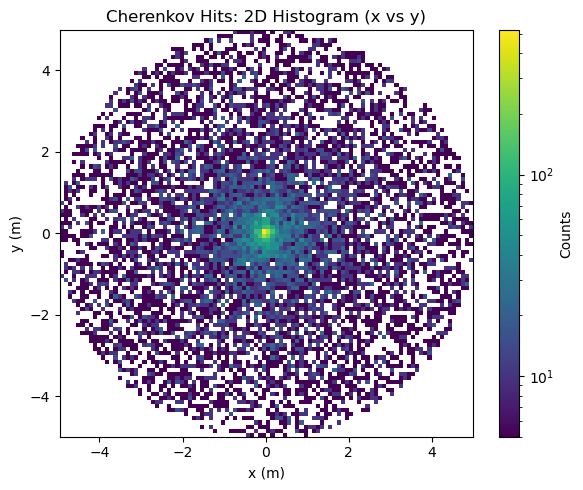

In [25]:
from ReadTrinity import read_cherenkov_hits, plot_CARE

input_file = "/scratch/general/vast/u1520754/cherenkov_hits.dat"
#input_file = "/scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e4_R1/pdg13_E1e4_r1_s1499/zen90.0/az270.0/h43000/x0.0_y0.0_z0.0/CORSIKA8/cherenkov_hits_base.dat"
input_file = "/uufs/chpc.utah.edu/common/home/u1520754/cherenkov_hits.dat"
cherenkov_photon = read_cherenkov_hits(input_file, plot=True)

in_file = "/scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/Muon_pid13_E1e4_R1/pdg13_E1e4_r1_s1499/zen90.0/az270.0/h43000/x0.0_y0.0_z0.0/CARE/cherenkov_hits.root"
#CARE_img = plot_CARE(in_file, plot=True)

In [3]:
#Simple model for muon in magnetic field
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Physical constants (SI)
C = 299792458.0                 # m/s
E_CHARGE = 1.602176634e-19      # C
MEV_TO_J = 1.602176634e-13      # J/MeV


def _trapz(y, x, axis=0):
    f = getattr(np, "trapezoid", None) or np.trapz   # NumPy 1.x / 2.x
    return f(y, x, axis=axis)


def _basis(B, u0):
    """Return (u_par, u_perp0, w) for rotation of u0 about B-hat."""
    bhat = B / np.linalg.norm(B)
    u_par = np.dot(u0, bhat) * bhat
    u_perp0 = u0 - u_par
    w = np.cross(bhat, u_perp0)
    return u_par, u_perp0, w


def _const_or_none(f):
    """Return float if f is a plain number, None if it is callable."""
    return None if callable(f) else float(f)


def _propagate_numeric(B_f, x0, u0, a_f, b_f, t, q, m, E0, E_stop,
                       kBfac, n_steps, s_guess):
    """
    RK4 in path length s for position-dependent a(x), b(x), B(x).
    State: x (m), u (unit vector), E (MeV total), tau (s, elapsed time).
    kBfac = |q| * C / MEV_TO_J, so that du/ds = kBfac*|B|/pc * (sense) u x Bhat.

    Returns x, v, E, s, stopped.
    """
    sgn = np.sign(q) if q != 0 else 0.0

    def rhs(y):
        x, u, E = y[0:3], y[3:6], y[6]
        pc = np.sqrt(max(E * E - m * m, 1e-30))
        beta = pc / E
        dE = -(a_f(x) + b_f(x) * E)
        dtau = 1.0 / (beta * C)
        Bv = B_f(x)
        # d(u)/ds = (q/|p|) u x B  ->  in these units: sgn * kBfac / pc * (u x B)
        du = sgn * kBfac / pc * np.cross(u, Bv) if sgn != 0.0 else np.zeros(3)
        return np.concatenate([u, du, [dE, dtau]])

    y = np.concatenate([x0, u0, [E0, 0.0]])
    s = 0.0
    ds = s_guess / n_steps
    stopped = False

    # Hard cap on the number of steps (adaptive growth allowed, see below)
    max_iter = 50 * n_steps
    for _ in range(max_iter):
        # adapt step: do not lose more than ~0.5% energy or rotate > ~0.02 rad per step
        E = y[6]
        pc = np.sqrt(max(E * E - m * m, 1e-30))
        dEds = abs(a_f(y[0:3]) + b_f(y[0:3]) * E)
        Bn = np.linalg.norm(B_f(y[0:3]))
        h = ds
        if dEds > 0:
            h = min(h, 5e-3 * E / dEds)
        if kBfac * Bn > 0:
            h = min(h, 0.02 * pc / (kBfac * Bn))
        h = max(h, 1e-6)                       # 1 micron floor

        k1 = rhs(y)
        k2 = rhs(y + 0.5 * h * k1)
        k3 = rhs(y + 0.5 * h * k2)
        k4 = rhs(y + h * k3)
        y_new = y + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
        y_new[3:6] /= np.linalg.norm(y_new[3:6])       # keep |u| = 1

        # --- stopping condition ---
        if y_new[6] <= E_stop:
            frac = (y[6] - E_stop) / max(y[6] - y_new[6], 1e-30)
            y = y + frac * (y_new - y)
            y[6] = E_stop
            s += frac * h
            stopped = True
            break

        # --- reached target time: interpolate on this step ---
        if y_new[7] >= t:
            frac = (t - y[7]) / max(y_new[7] - y[7], 1e-30)
            y = y + frac * (y_new - y)
            y[3:6] /= np.linalg.norm(y[3:6])
            s += frac * h
            break

        y = y_new
        s += h
    else:
        raise RuntimeError("propagate_particle: step cap reached "
                           "(increase n_steps or check loss functions).")

    x_f, u_f, E_f = y[0:3], y[3:6], y[6]
    beta_f = np.sqrt(max(E_f * E_f - m * m, 0.0)) / E_f
    return x_f, u_f * beta_f * C, E_f, s, stopped


def propagate_particle(B, x0, v0, a, b, t, charge, mass_MeV,
                       n_steps=20000, E_stop_MeV=None):
    """
    Propagate a charged particle with energy loss dE/ds = -a - b*E in a
    magnetic field.

    Parameters
    ----------
    B        : (Bx, By, Bz) in Tesla, OR callable B(x) -> (3,)
    x0       : (x, y, z) initial position in meters
    v0       : (vx, vy, vz) initial velocity in m/s
    a        : MeV/m, float OR callable a(x) -> float
    b        : 1/m,   float OR callable b(x) -> float
    t        : propagation time, s
    charge   : charge in units of e
    mass_MeV : rest mass energy mc^2 in MeV
    n_steps  : grid resolution (semi-analytic branches) / base step count
               (numeric branch)
    E_stop_MeV : stopping total energy (default: mc^2)

    Returns
    -------
    x_final (m), v_final (m/s), E_final (MeV), s_final (m), stopped (bool)

    Solution strategy
    -----------------
    constant a, b and uniform B (analytic / semi-analytic):
        a = b = 0            : fully closed form (free flight or exact helix)
        b = 0, a > 0         : exact E(t), s(t), phi; position by 1D integral
        b > 0                : E(s) exact; t(s), phi(s), position on a grid
    callable a, b or B (numerical):
        adaptive-step RK4 in path length, state (x, u, E, t)
    """
    x0 = np.asarray(x0, float)
    v0 = np.asarray(v0, float)
    q = charge * E_CHARGE
    m = mass_MeV

    # ---------------- initial state ----------------
    speed0 = np.linalg.norm(v0)
    if speed0 >= C:
        raise ValueError("Initial speed must be < c")
    if speed0 == 0.0:
        raise ValueError("Initial speed must be > 0")
    u0 = v0 / speed0
    gamma0 = 1.0 / np.sqrt(1.0 - (speed0 / C) ** 2)
    E0 = gamma0 * m
    pc0 = np.sqrt(max(E0**2 - m**2, 0.0))
    E_stop = m if E_stop_MeV is None else E_stop_MeV

    # ---------------- decide: analytic or numeric ----------------
    a_const, b_const = _const_or_none(a), _const_or_none(b)
    B_is_func = callable(B)
    use_numeric = (a_const is None) or (b_const is None) or B_is_func

    if use_numeric:
        a_f = a if callable(a) else (lambda x, _v=float(a): _v)
        b_f = b if callable(b) else (lambda x, _v=float(b): _v)
        if B_is_func:
            B_f = lambda x: np.asarray(B(x), float)
        else:
            _B = np.asarray(B, float)
            B_f = lambda x: _B
        kBfac = abs(q) * C / MEV_TO_J        # du/ds = sgn*kBfac*(u x B)/pc
        # step-size scale: max distance the particle can possibly cover
        s_guess = speed0 * t if t > 0 else 1.0
        if t <= 0.0:
            return x0.copy(), v0.copy(), E0, 0.0, False
        return _propagate_numeric(B_f, x0, u0, a_f, b_f, t, q, m, E0,
                                  E_stop, kBfac, n_steps, s_guess)

    # ---------- constant-coefficient analytic paths (unchanged) ----------
    a, b = a_const, b_const
    B = np.asarray(B, float)

    Bmag = np.linalg.norm(B)
    has_field = (Bmag > 0.0) and (q != 0.0)
    kB = abs(q) * Bmag * C / MEV_TO_J if has_field else 0.0   # dphi/ds = kB/pc
    sigma = -np.sign(q) if q != 0 else 0.0                    # rotation sense

    # ---------------- maximum path length ----------------
    if b > 0:
        s_max = np.log((E0 + a / b) / (E_stop + a / b)) / b
    elif a > 0:
        s_max = (E0 - E_stop) / a
    else:
        s_max = np.inf

    # =====================================================
    # CASE 0: a == b == 0  -> fully closed form
    # =====================================================
    if a == 0 and b == 0:
        s_final = speed0 * t
        if not has_field:
            return x0 + v0 * t, v0.copy(), E0, s_final, False

        u_par, u_perp0, w = _basis(B, u0)
        r = pc0 / kB
        phi = s_final / r
        x_final = (x0 + u_par * s_final
                   + r * (u_perp0 * np.sin(phi)
                          + sigma * w * (1.0 - np.cos(phi))))
        u_final = (u_par + u_perp0 * np.cos(phi) + sigma * w * np.sin(phi))
        u_final /= np.linalg.norm(u_final)
        return x_final, u_final * speed0, E0, s_final, False

    # =====================================================
    # CASE 1: b == 0, a > 0 -> analytic time, energy, angle
    # =====================================================
    if b == 0:
        pc_stop = np.sqrt(max(E_stop**2 - m**2, 0.0))
        t_stop = (pc0 - pc_stop) / (a * C)       # pc(t) = pc0 - a*c*t (exact)
        if t >= t_stop:
            stopped = True
            E_final = E_stop
            s_final = s_max
        else:
            stopped = False
            E_final = np.sqrt((pc0 - a * C * t) ** 2 + m**2)
            s_final = (E0 - E_final) / a
        beta_f = np.sqrt(max(E_final**2 - m**2, 0.0)) / E_final

        if not has_field:
            return (x0 + u0 * s_final, u0 * beta_f * C,
                    E_final, s_final, stopped)

        phi_final = (kB / a) * (np.arccosh(E0 / m) - np.arccosh(E_final / m))
        u_par, u_perp0, w = _basis(B, u0)
        ang_f = sigma * phi_final
        u_final = u_par + u_perp0 * np.cos(ang_f) + w * np.sin(ang_f)
        u_final /= np.linalg.norm(u_final)

        s = np.linspace(0.0, s_final, n_steps)
        E = np.maximum(E0 - a * s, E_stop * (1 + 1e-12))
        pc = np.sqrt(np.maximum(E**2 - m**2, 1e-30))
        phi = cumulative_trapezoid(kB / pc, s, initial=0.0)
        ang = sigma * phi
        u_s = (u_par[None, :]
               + u_perp0[None, :] * np.cos(ang)[:, None]
               + w[None, :] * np.sin(ang)[:, None])
        x_final = x0 + _trapz(u_s, s, axis=0)
        return x_final, u_final * beta_f * C, E_final, s_final, stopped

    # =====================================================
    # CASE 2: b > 0 -> E(s) exact, rest on a grid
    # =====================================================
    s = np.linspace(0.0, s_max, n_steps)
    s[-1] *= (1 - 1e-12)                          # avoid singular endpoint
    E = np.maximum((E0 + a / b) * np.exp(-b * s) - a / b,
                   E_stop * (1 + 1e-12))
    pc = np.sqrt(np.maximum(E**2 - m**2, 1e-30))
    beta = pc / E

    t_of_s = cumulative_trapezoid(1.0 / (beta * C), s, initial=0.0)
    stopped = False
    if t >= t_of_s[-1]:
        s_final = s[-1]
        stopped = True
    else:
        s_final = float(np.interp(t, t_of_s, s))

    if has_field:
        phi = cumulative_trapezoid(kB / pc, s, initial=0.0)
        u_par, u_perp0, w = _basis(B, u0)
        ang = sigma * phi
        u_s = (u_par[None, :]
               + u_perp0[None, :] * np.cos(ang)[:, None]
               + w[None, :] * np.sin(ang)[:, None])
    else:
        u_s = np.tile(u0, (n_steps, 1))

    pos = x0[None, :] + cumulative_trapezoid(u_s, s, axis=0, initial=0.0)
    x_final = np.array([np.interp(s_final, s, pos[:, i]) for i in range(3)])
    u_final = np.array([np.interp(s_final, s, u_s[:, i]) for i in range(3)])
    u_final /= np.linalg.norm(u_final)
    E_final = float(np.interp(s_final, s, E))
    beta_f = np.sqrt(max(E_final**2 - m**2, 0.0)) / E_final
    return x_final, u_final * beta_f * C, E_final, s_final, stopped



In [8]:
#Sim_Folder = "/scratch/general/vast/u1520754/test3d_muon_1e2GeV"
Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_muon_1e1GeV_h5000_zen85_az270"
#Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/test3d_muon_1e1GeV_h5000_zen89_az270"
Sim_Folder = "/uufs/chpc.utah.edu/common/home/u1520754/cherenkov_hits"

In [9]:
# Shower display + simple-model muon overlay (CORSIKA 8 comparison)
# Requires: Sim_Folder
import os
import numpy as np
import pandas as pd
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ===============================================================
# Constants (SI / MeV)
# ===============================================================
C         = 299792458.0
E_CHARGE  = 1.602176634e-19
MEV_TO_J  = 1.602176634e-13
ME_MEV    = 0.51099895
M_MU_MEV  = 105.6583755
K_BB      = 0.307075
KBFAC     = C / MEV_TO_J * E_CHARGE          # du/ds = sgn*KBFAC*(u x B)/pc[MeV]
TAU_MU_S  = 2.1969811e-6

def get_particle_name(pdg):
    pdg_map = {
        11: "e⁻", -11: "e⁺", 13: "μ⁻", -13: "μ⁺", 15: "τ⁻", -15: "τ⁺",
        22: "γ", 111: "π⁰", 211: "π⁺", -211: "π⁻",
        2212: "p", -2212: "p̄", 2112: "n", -2112: "n̄",
        321: "K⁺", -321: "K⁻", 130: "K_L", 310: "K_S",
        12: "ν_e", -12: "ν̄_e", 14: "ν_μ", -14: "ν̄_μ", 16: "ν_τ", -16: "ν̄_τ",
    }
    return pdg_map.get(pdg, f"PDG_{pdg}")

def get_particle_group(pdg):
    a = abs(int(pdg))
    if a == 13:            return "μ±"
    if a == 11:            return "e±"
    if a == 22:            return "γ"
    if a == 15:            return "τ±"
    if a in (12, 14, 16):  return "ν"
    return "hadrons"

# ---------------------------------------------------------------
# Settings
# ---------------------------------------------------------------
path       = Sim_Folder + "/particles_3d/particles_3d.parquet"
OUT_HTML   = Sim_Folder + "/shower_coords.html"
SAVE_HTML  = True
R_EARTH    = 6371e3
E_UNIT     = "GeV"

nsteps    = 100
TIME_MODE = "linear"
LAT_PCT   = 90
DIM_MAX_PER_TYPE = 2000
BRIGHT_SIZE, DIM_SIZE, DIM_OPACITY = 4, 3, 0.3
FRAME_MS  = 0.001

# Simple model settings
B_VEC     = np.array([28.6e-6, 0.0, -46.4e-6])   # T, CORSIKA 8 setting
H_ATM     = 112.8292e3
R_TOP     = R_EARTH + H_ATM
H_OBS = 3000.0                                   # C8 Z origin = observation level
R_GROUND  = R_EARTH + H_OBS

# Integrator controls
H_MAX_M        = 500.0
H_MIN_M        = 1e-6
MAX_DEDX_FRAC  = 0.01
MAX_ROT_RAD    = 0.02
E_STOP_KIN_MEV = 1.0
MAX_STEPS      = 5_000_000
TOP_TOL_M      = 1e-3

# ===============================================================
# Atmosphere: Linsley / CORSIKA 5-layer (US Standard)
# ===============================================================
ATM_H_LIM = np.array([0.0, 4.0e3, 10.0e3, 40.0e3, 100.0e3, 112.8292e3])
ATM_A = np.array([-186.5562, -94.9199, 0.61289, 0.0, 0.01128292])
ATM_B = np.array([1222.6562, 1144.9069, 1305.5948, 540.1778, 1.0])
ATM_C = np.array([994186.38, 878153.55, 636143.04, 772170.16, 1.0e9])

def density_gcm3(h_m):
    h = max(float(h_m), 0.0)
    if h >= ATM_H_LIM[-1]:
        return 0.0
    i = int(np.searchsorted(ATM_H_LIM, h, side="right") - 1)
    i = min(max(i, 0), 4)
    hc = h * 100.0
    if i < 4:
        return ATM_B[i] / ATM_C[i] * np.exp(-hc / ATM_C[i])
    return ATM_B[4] / ATM_C[4]

def rho_atm(x):
    return density_gcm3(np.linalg.norm(x) - R_EARTH)

# ===============================================================
# Muon stopping power in dry air (Bethe-Bloch + radiative b(E))
# ===============================================================
I_MEV    = 85.7e-6
Z_OVER_A = 0.49919
RHO_REF  = 1.20479e-3
CBAR, X0_D, X1_D, A_D, K_D = 10.5961, 1.7418, 4.2759, 0.10914, 3.3994
LN10 = np.log(10.0)
DENSITY_SCALED_DELTA = False

def delta_density(x, rho):
    if DENSITY_SCALED_DELTA and rho > 0.0:
        x = x - np.log(RHO_REF / rho) / (2.0 * LN10)
    if x >= X1_D:
        return 2.0 * LN10 * x - CBAR
    if x >= X0_D:
        return 2.0 * LN10 * x - CBAR + A_D * (X1_D - x) ** K_D
    return 0.0

def ion_stopping(E_tot, rho=RHO_REF, m=M_MU_MEV):
    gam = max(E_tot / m, 1.0 + 1e-12)
    bg2 = gam * gam - 1.0
    beta2 = bg2 / (gam * gam)
    Wmax = 2.0 * ME_MEV * bg2 / (1.0 + 2.0 * gam * ME_MEV / m + (ME_MEV / m) ** 2)
    d = delta_density(0.5 * np.log10(bg2), rho)
    arg = 2.0 * ME_MEV * bg2 * Wmax / I_MEV**2
    S = K_BB * Z_OVER_A / beta2 * (0.5 * np.log(arg) - beta2 - 0.5 * d)
    return max(S, 0.0)

B_TAB_EKIN_GEV = np.array([1.0, 3.0, 10.0, 30.0, 100.0, 300.0,
                           1e3, 3e3, 1e4, 1e5, 1e6])
B_TAB_1E6      = np.array([1.20, 1.75, 2.35, 2.60, 2.75, 2.95,
                           3.10, 3.30, 3.50, 3.70, 3.85])
_LB_E = np.log(B_TAB_EKIN_GEV)
_LB_B = np.log(B_TAB_1E6 * 1e-6)

def b_rad(E_tot, m=M_MU_MEV):
    ek_gev = max((E_tot - m) * 1e-3, 1e-6)
    return float(np.exp(np.interp(np.log(ek_gev), _LB_E, _LB_B)))

# ===============================================================
# RK4 in path length. State y = [x(3), u(3), E, t, tau, X_slant, s]
# ===============================================================
def make_rhs(B_vec, charge, loss, m=M_MU_MEV):
    sgn = float(np.sign(charge)) * abs(charge)
    has_B = (sgn != 0.0) and (np.linalg.norm(B_vec) > 0.0)

    def rhs(y):
        x, u, E = y[0:3], y[3:6], y[6]
        E = max(E, m * (1.0 + 1e-12))
        pc = np.sqrt(E * E - m * m)
        beta = pc / E
        rho = rho_atm(x)
        dt = 1.0 / (beta * C)
        dEds = -rho * 100.0 * (ion_stopping(E, rho) + b_rad(E) * E) if loss else 0.0
        du = sgn * KBFAC / pc * np.cross(u, B_vec) if has_B else np.zeros(3)
        return np.concatenate([u, du, [dEds, dt, dt * m / E, rho * 100.0, 1.0]])
    return rhs

def integrate_track(x0, u0, E0, B_vec, charge, loss=True, t_end=None, m=M_MU_MEV):
    """Integrate until ground / top of atmosphere / stopped / lab time t_end.
    Returns dict(rec=(N,10) accepted states, reason)."""
    E_stop = m + E_STOP_KIN_MEV
    B_vec = np.asarray(B_vec, float)
    rhs = make_rhs(B_vec, charge, loss, m)
    kb = abs(charge) * KBFAC * np.linalg.norm(B_vec)

    def rk4(y, h):
        k1 = rhs(y); k2 = rhs(y + 0.5 * h * k1)
        k3 = rhs(y + 0.5 * h * k2); k4 = rhs(y + h * k3)
        yn = y + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
        yn[3:6] /= np.linalg.norm(yn[3:6])
        return yn

    def event(y):
        r = np.linalg.norm(y[0:3])
        if r <= R_GROUND:
            return "hit ground"
        if r > R_TOP + TOP_TOL_M:
            return "left atmosphere"
        if y[6] <= E_stop:
            return "stopped"
        if t_end is not None and y[7] >= t_end:
            return "reached last time"
        return None

    y = np.concatenate([np.asarray(x0, float), np.asarray(u0, float),
                        [E0, 0.0, 0.0, 0.0, 0.0]])
    rec = [y.copy()]
    reason = None
    for _ in range(MAX_STEPS):
        x, E = y[0:3], y[6]
        pc = np.sqrt(max(E * E - m * m, 1e-30))
        rho = rho_atm(x)
        h = H_MAX_M
        if loss and rho > 0.0:
            dEds = rho * 100.0 * (ion_stopping(E, rho) + b_rad(E) * E)
            if dEds > 0.0:
                h = min(h, MAX_DEDX_FRAC * max(E - m, E_STOP_KIN_MEV) / dEds)
        if kb > 0.0:
            h = min(h, MAX_ROT_RAD * pc / kb)
        h = max(h, H_MIN_M)

        yn = rk4(y, h)
        if event(yn) is not None:
            lo, hi = 0.0, h
            for _ in range(60):
                mid = 0.5 * (lo + hi)
                if event(rk4(y, mid)) is None:
                    lo = mid
                else:
                    hi = mid
            yn = rk4(y, hi)
            reason = event(yn)
            rec.append(yn)
            break
        y = yn
        rec.append(y.copy())
    else:
        raise RuntimeError("step cap reached (check settings)")
    return dict(rec=np.array(rec), reason=reason)

# ---------------------------------------------------------------
# 1) Load
# ---------------------------------------------------------------
df = pd.read_parquet(path)
df = df[np.isfinite(df[["X", "Y", "Z", "time"]]).all(axis=1)].reset_index(drop=True)
# wherever R_EARTH was used as the frame offset:
df["Z"] = df["Z"] + R_EARTH + H_OBS
df["name"]  = df["pdg"].map(get_particle_name)
df["group"] = df["pdg"].map(get_particle_group)

T      = df["time"].to_numpy(np.float64)
NAMES  = df["name"].to_numpy()
GROUPS = df["group"].to_numpy()
PDG    = df["pdg"].to_numpy()
EK     = df["kinetic_energy"].to_numpy().astype(np.float64)
Pm = np.column_stack([df["X"].to_numpy(np.float64),
                      df["Y"].to_numpy(np.float64),
                      df["Z"].to_numpy(np.float64) - R_EARTH])
print("rows:", len(df), "| t range [s]:", T.min(), "->", T.max())

CUSTOM = np.empty((len(df), 3), dtype=object)
CUSTOM[:, 0] = NAMES
CUSTOM[:, 1] = EK.astype(np.float32)
CUSTOM[:, 2] = np.round(T * 1e6, 3)
HOVER = ("<b>%{customdata[0]}</b><br>"
         f"E_kin = %{{customdata[1]:.4g}} {E_UNIT}<br>"
         "t = %{customdata[2]} µs<extra></extra>")

# ---------------------------------------------------------------
# 2) Colors
# ---------------------------------------------------------------
GROUP_COLOR = {"μ±": "#BBACED", "e±": "#D4F30A", "γ": "#F5FAF8",
               "τ±": "#4CC804", "hadrons": "#009E73", "ν": "#DDDDDD"}
ORDER  = ["μ±", "e±", "γ", "τ±", "hadrons", "ν"]
groups = [g for g in ORDER if g in set(GROUPS)]
group_idx = {g: np.flatnonzero(GROUPS == g) for g in groups}

# ---------------------------------------------------------------
# 3) Shower axis (unchanged)
# ---------------------------------------------------------------
lin_times = np.linspace(T.min(), T.max(), 1000)
lin_w = (T.max() - T.min()) / 1000 * 1.5
c0 = c1 = None
for t0 in lin_times:
    m = np.abs(T - t0) <= lin_w
    if not m.any():
        continue
    c = Pm[m].mean(axis=0)
    if c0 is None:
        c0 = c
    elif np.linalg.norm(c - c0) > 1.0:
        c1 = c
        break
ez = (c1 - c0); ez /= np.linalg.norm(ez)
ref = np.array([0.0, 0.0, 1.0]) if abs(ez[2]) < 0.999 else np.array([1.0, 0.0, 0.0])
ex = np.cross(ref, ez); ex /= np.linalg.norm(ex)
ey = np.cross(ez, ex)
zen = np.degrees(np.arccos(np.clip(-ez[2], -1, 1)))
azi = np.degrees(np.arctan2(ez[1], ez[0]))
print(f"axis ez = {ez.round(4)}  zenith {zen:.1f}°, azimuth {azi:.1f}°")

def to_shower(P):
    Prel = P - c0
    return Prel @ ex, Prel @ ey, Prel @ ez / 1e3

SU, SV, SW = to_shower(Pm)

# ---------------------------------------------------------------
# 4) Time bins
# ---------------------------------------------------------------
if TIME_MODE == "quantile":
    edges = np.unique(np.quantile(T, np.linspace(0, 1, nsteps + 1)))
else:
    edges = np.linspace(T.min(), T.max(), nsteps + 1)
nbins = len(edges) - 1
BIN = np.clip(np.searchsorted(edges, T, side="right") - 1, 0, nbins - 1)
labels = [f"{0.5*(edges[k]+edges[k+1])*1e6:.2f} µs" for k in range(nbins)]
names  = [f"f{k}" for k in range(nbins)]

group_bins = {}
for g in groups:
    idx = group_idx[g]
    order = idx[np.argsort(BIN[idx], kind="stable")]
    cuts = np.searchsorted(BIN[order], np.arange(nbins + 1))
    group_bins[g] = [order[cuts[k]:cuts[k+1]] for k in range(nbins)]

# ---------------------------------------------------------------
# 5) Reference muon: highest-energy muon per time step (skip empty steps)
# ---------------------------------------------------------------
mu_all = np.flatnonzero(GROUPS == "μ±")
ref_idx = []
for k in range(nbins):
    s = mu_all[BIN[mu_all] == k]
    if len(s):
        ref_idx.append(s[np.argmax(EK[s])])
ref_idx = np.array(ref_idx, dtype=int)
if len(ref_idx) < 2:
    raise RuntimeError("Need at least 2 time steps containing a muon.")

T_REF  = T[ref_idx]
P_REF  = Pm[ref_idx]
EK_REF = EK[ref_idx]                                  # GeV
REF_BIN = BIN[ref_idx]
X0    = P_REF[0] + np.array([0.0, 0.0, R_EARTH])     # Earth-centred
u0    = P_REF[1] - P_REF[0]; u0 /= np.linalg.norm(u0)
CHARGE = -int(np.sign(PDG[ref_idx[0]]))               # 13 -> -1, -13 -> +1
MU_NAME = "μ⁻" if CHARGE < 0 else "μ⁺"
E_KIN0_MEV = EK[ref_idx[0]] * 1e3
E_TOT0 = E_KIN0_MEV + M_MU_MEV
print(f"reference {MU_NAME}: {len(ref_idx)} steps, E_kin0 = {E_KIN0_MEV/1e3:.4g} GeV, "
      f"alt0 = {(np.linalg.norm(X0)-R_EARTH)/1e3:.3f} km, u0 = {u0.round(4)}")

# ---------------------------------------------------------------
# 6) Model time grid: from first muon time through the last sim time,
#    whether or not a C8 muon exists in the bin.
# ---------------------------------------------------------------
k0 = int(REF_BIN[0])
k_to_ref = {int(kbin): j for j, kbin in enumerate(REF_BIN)}
T_MOD, MOD_REF = [float(T_REF[0])], [0]
for k in range(k0 + 1, nbins):
    j = k_to_ref.get(k, -1)
    T_MOD.append(float(T[ref_idx[j]]) if j >= 0 else float(edges[k + 1]))
    MOD_REF.append(j)
T_MOD   = np.asarray(T_MOD, dtype=np.float64)
MOD_REF = np.asarray(MOD_REF, dtype=int)
for i in range(1, T_MOD.size):
    if T_MOD[i] <= T_MOD[i - 1]:
        T_MOD[i] = T_MOD[i - 1] + 1e-12
if T_MOD[-1] < edges[-1]:
    T_MOD   = np.append(T_MOD, edges[-1])
    MOD_REF = np.append(MOD_REF, -1)

# ---------------------------------------------------------------
# 7) Propagate model (single RK4 pass, resample onto T_MOD, decay off)
# ---------------------------------------------------------------
def run_model(loss, label, col):
    t_rel = T_MOD - T_MOD[0]
    out = integrate_track(X0, u0, E_TOT0, B_VEC, CHARGE, loss=loss, t_end=t_rel[-1])
    R = out["rec"]; reason = out["reason"]
    tt = R[:, 7]
    n = int(np.searchsorted(t_rel, tt[-1], side="right"))   # samples covered by the track
    n = max(n, 1)
    tg = t_rel[:n]
    col_i = lambda j: np.interp(tg, tt, R[:, j])
    P  = np.column_stack([col_i(0), col_i(1), col_i(2)]) - np.array([0.0, 0.0, R_EARTH])
    E  = col_i(6)                                          # total MeV
    tau = col_i(8)                                         # proper time [s]
    w   = np.exp(-tau / TAU_MU_S)
    t   = T_MOD[:n]
    U, V, W = to_shower(P)
    EK_M = (E - M_MU_MEV) / 1e3                            # GeV

    has = MOD_REF[:n] >= 0
    mr  = MOD_REF[:n][has]
    dr, de_signed, de, ek_ref = (np.full(n, np.nan) for _ in range(4))
    dr[has]  = np.maximum(np.linalg.norm(P[has] - P_REF[mr], axis=1), 1e-3)
    de_signed[has] = EK_M[has] - EK_REF[mr]
    de[has]  = np.maximum(np.abs(de_signed[has]), 1e-6)
    ek_ref[has] = EK_REF[mr]

    cd = np.column_stack([[f"{MU_NAME} model: {label}"] * n, EK_M,
                          np.round(t * 1e6, 3), w, 1 - w, dr,
                          ek_ref, de_signed]).astype(object)
    ilast = np.flatnonzero(has)
    if len(ilast):
        i = int(ilast[-1])
        print(f"[{label}] {reason}; {n} pts ({len(ilast)} with C8 muon), "
              f"E_kin end = {EK_M[-1]:.4g} GeV, P_surv end = {w[-1]:.3f}, "
              f"Δr end = {dr[i]:.2f} m, ΔE end = {de_signed[i]:.4g} GeV")
    else:
        print(f"[{label}] {reason}; {n} pts (no C8 match), E_kin end = {EK_M[-1]:.4g} GeV")
    return dict(label=label, col=col, T=t, U=U, V=V, W=W, DR=dr, cd=cd, reason=reason,
                DE=de, DE_S=de_signed)

MODELS = [run_model(False, "no energy loss", "#FF4FD8"),
          run_model(True,  "with energy loss", "#FF8C5A")]

HOVER_M = ("<b>%{customdata[0]}</b><br>E_kin = %{customdata[1]:.4g} GeV<br>"
           "t = %{customdata[2]} µs<br>P(survive) = %{customdata[3]:.4f}<br>"
           "P(decayed) = %{customdata[4]:.4f}<br>Δr = %{customdata[5]:.3g} m<extra></extra>")

DE_COL = "#00E5FF"
HOVER_DE = ("<b>ΔE (energy-loss model − C8)</b><br>t = %{customdata[2]} µs<br>"
            "E_kin model = %{customdata[1]:.4g} GeV<br>"
            "E_kin C8 = %{customdata[6]:.4g} GeV<br>"
            "ΔE = %{customdata[7]:+.4g} GeV<extra></extra>")

# ---------------------------------------------------------------
# 8) Figure
# ---------------------------------------------------------------
PANELS = [(1, 1, SU, SV), (2, 1, SW, SU), (2, 2, SW, SV)]
fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                    specs=[[{}, {"secondary_y": True}],
                           [{}, {}]],
                    subplot_titles=("Shower plane (⊥ axis)",
                                    "Δr (left) and ΔE<sub>loss model</sub> (right) vs time",
                                    "Longitudinal vs x′", "Longitudinal vs y′"))
rng = np.random.default_rng(0)
anim = []
for g in groups:
    c = GROUP_COLOR[g]
    idx = group_idx[g]
    if len(idx) > DIM_MAX_PER_TYPE:
        idx = rng.choice(idx, DIM_MAX_PER_TYPE, replace=False)
    s0 = group_bins[g][0]
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                             showlegend=True, hoverinfo="skip",
                             marker=dict(size=12, color=c)), row=1, col=1)
    for r_, c_, A, B in PANELS:
        fig.add_trace(go.Scatter(x=A[idx], y=B[idx], mode="markers", legendgroup=g,
                                 showlegend=False, customdata=CUSTOM[idx], hovertemplate=HOVER,
                                 marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY)),
                      row=r_, col=c_)
        fig.add_trace(go.Scatter(x=A[s0], y=B[s0], mode="markers", legendgroup=g,
                                 showlegend=False, customdata=CUSTOM[s0], hovertemplate=HOVER,
                                 marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0)),
                      row=r_, col=c_)
        anim.append(len(fig.data) - 1)

def model_xy(md):
    return [(1, 1, md["U"], md["V"]), (1, 2, md["T"] * 1e6, md["DR"]),
            (2, 1, md["W"], md["U"]), (2, 2, md["W"], md["V"])]

model_anim = []
for md in MODELS:
    lg = "model_" + md["label"]
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines+markers", legendgroup=lg,
                             name=f"{MU_NAME} model: {md['label']} ({md['reason']})",
                             line=dict(color=md["col"]), marker=dict(color=md["col"])),
                  row=1, col=1)
    for r_, c_, A, B in model_xy(md):
        sy = dict(secondary_y=False) if (r_, c_) == (1, 2) else {}
        fig.add_trace(go.Scatter(x=A, y=B, mode="lines", legendgroup=lg, showlegend=False,
                                 hoverinfo="skip", opacity=0.35,
                                 line=dict(color=md["col"], width=1)),
                      row=r_, col=c_, **sy)
        fig.add_trace(go.Scatter(x=A[:1], y=B[:1], mode="lines+markers", legendgroup=lg,
                                 showlegend=False, customdata=md["cd"][:1],
                                 hovertemplate=HOVER_M,
                                 line=dict(color=md["col"], width=3),
                                 marker=dict(size=5, color=md["col"])),
                      row=r_, col=c_, **sy)
        anim.append(len(fig.data) - 1)
        model_anim.append((md, A, B))

fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines+markers", legendgroup="dE",
                         showlegend=True, hoverinfo="skip",
                         name="ΔE = |E_kin,model(loss) − E_kin,C8| (right axis)",
                         line=dict(color=DE_COL, width=3, dash="dot"),
                         marker=dict(size=5, symbol="diamond", color=DE_COL)),
              row=1, col=1)

md_el = MODELS[1]
A_de = md_el["T"] * 1e6
B_de = md_el["DE"]
fig.add_trace(go.Scatter(x=A_de, y=B_de, mode="lines", legendgroup="dE", showlegend=False,
                         hoverinfo="skip", opacity=0.35,
                         line=dict(color=DE_COL, width=1, dash="dot")),
              row=1, col=2, secondary_y=True)
fig.add_trace(go.Scatter(x=A_de[:1], y=B_de[:1], mode="lines+markers", legendgroup="dE",
                         showlegend=False, customdata=md_el["cd"][:1],
                         hovertemplate=HOVER_DE,
                         line=dict(color=DE_COL, width=3, dash="dot"),
                         marker=dict(size=5, symbol="diamond", color=DE_COL)),
              row=1, col=2, secondary_y=True)
anim.append(len(fig.data) - 1)
model_anim.append((md_el, A_de, B_de))

frames = []
for k in range(nbins):
    fdata = []
    for g in groups:
        s = group_bins[g][k]
        for _, _, A, B in PANELS:
            fdata.append(go.Scatter(x=A[s], y=B[s], customdata=CUSTOM[s]))
    for md, A, B in model_anim:
        n = max(1, int(np.searchsorted(md["T"], edges[k + 1], side="right")))
        fdata.append(go.Scatter(x=A[:n], y=B[:n], customdata=md["cd"][:n]))
    assert len(fdata) == len(anim), \
        f"frame {k}: {len(fdata)} frame traces vs {len(anim)} animated traces"
    frames.append(go.Frame(data=fdata, traces=anim, name=names[k]))
fig.frames = frames

# ---------------------------------------------------------------
# 9) Axis ranges
# ---------------------------------------------------------------
SR = np.maximum(np.hypot(SU, SV), 1e-2)
lat = float(np.percentile(SR, LAT_PCT)) * 1.1
LAT = [-lat, lat]
LON = [0.0, float(np.percentile(SW, 99.5)) * 1.05]
dr_all = np.concatenate([md["DR"] for md in MODELS])
dr_all = dr_all[np.isfinite(dr_all)]
DRLOG = ([np.log10(dr_all.min()) - 0.2, np.log10(dr_all.max()) + 0.2]
         if dr_all.size else [-3.0, 6.0])
TRNG  = [T.min() * 1e6, T.max() * 1e6]
de_all = MODELS[1]["DE"]
de_all = de_all[np.isfinite(de_all) & (de_all > 1e-6)]
DELOG = ([np.log10(de_all.min()) - 0.2, np.log10(de_all.max()) + 0.2]
         if de_all.size else [-6.0, 0.0])

ax = dict(gridcolor="#333333", zerolinecolor="#777777", color="white",
          showline=True, linecolor="gray", mirror=True)
fig.update_xaxes(**ax); fig.update_yaxes(**ax)
fig.update_xaxes(title_text="x′ [m]", range=LAT, row=1, col=1)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=1, col=1, scaleanchor="x", scaleratio=1)
fig.update_xaxes(title_text="t [µs]", range=TRNG, row=1, col=2)
fig.update_yaxes(title_text="Δr [m]", type="log", range=DRLOG, row=1, col=2,
                 secondary_y=False, mirror=False)
fig.update_yaxes(title_text="ΔE [GeV]", type="log", range=DELOG,
                 row=1, col=2, secondary_y=True,
                 color=DE_COL, showgrid=False, showline=True, linecolor=DE_COL)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=1)
fig.update_yaxes(title_text="x′ [m]", range=LAT, row=2, col=1)
fig.update_xaxes(title_text="z′ along axis [km]", range=LON, row=2, col=2)
fig.update_yaxes(title_text="y′ [m]", range=LAT, row=2, col=2)

# ---------------------------------------------------------------
# 10) Controls + layout
# ---------------------------------------------------------------
play_args  = dict(frame=dict(duration=FRAME_MS, redraw=False),
                  transition=dict(duration=0), fromcurrent=True, mode="immediate")
pause_args = dict(frame=dict(duration=0, redraw=False),
                  transition=dict(duration=0), mode="immediate")
steps = [dict(method="animate", label=labels[k],
              args=[[names[k]], dict(frame=dict(duration=0, redraw=False),
                                     transition=dict(duration=0), mode="immediate")])
         for k in range(nbins)]

fig.update_layout(
    height=1100, width=1500,
    title=(f"Shower coordinates (zenith {zen:.1f}°, azimuth {azi:.1f}°) — time bins: {TIME_MODE}"
           f"<br>Model {MU_NAME}: E_kin0 = {E_KIN0_MEV/1e3:.4g} GeV, "
           f"B = (28.6, 0, −46.4) µT, Bethe-Bloch + b(E) × ρ(h) [Linsley], "
           f"decay off (weight in hover)"),
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.06,
        xanchor="left", yanchor="top", bgcolor="#333333", bordercolor="white",
        font=dict(color="white"),
        buttons=[dict(label="▶ Play",  method="animate", args=[None, play_args]),
                 dict(label="⏸ Pause", method="animate", args=[[None], pause_args])])],
    sliders=[dict(active=0, steps=steps, x=0.12, len=0.85, y=-0.06, yanchor="top",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        font=dict(color="white"), transition={"duration": 0})],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=16),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.06, y=1.0),
    hovermode="closest", hoverlabel=dict(font=dict(size=14)), uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=40, b=140, t=100),
)
fig.update_annotations(font=dict(size=16, color="white"))

if SAVE_HTML:
    fig.write_html(OUT_HTML, include_plotlyjs="cdn", auto_play=False, full_html=True)
    print(f"saved: {OUT_HTML}  ({os.path.getsize(OUT_HTML)/1e6:.1f} MB, plotly {plotly.__version__})")
fig.show()
# Global CORSIKA 8 coordinates vs time: z(t), x(t), y(t) + Δr/ΔE panel
# Requires the previous cell to have run (Pm, T, MODELS, group_bins, edges, ...)

OUT_HTML_G = Sim_Folder + "/shower_global_xyz.html"
TUS = T * 1e6                                   # particle time [µs]
GX, GY, GZ = Pm[:, 0] / 1e3, Pm[:, 1] / 1e3, Pm[:, 2] / 1e3   # km, z = Z − R_EARTH

# model tracks back to global coords: P = c0 + U ex + V ey + (W·1e3) ez
def model_global(md):
    P = (c0[None, :] + md["U"][:, None] * ex[None, :] + md["V"][:, None] * ey[None, :]
         + (md["W"] * 1e3)[:, None] * ez[None, :]) / 1e3
    return P[:, 0], P[:, 1], P[:, 2]

PANELS_G = [(1, 1, TUS, GZ), (2, 1, TUS, GX), (2, 2, TUS, GY)]

figg = make_subplots(rows=2, cols=2, horizontal_spacing=0.08, vertical_spacing=0.12,
                     specs=[[{}, {"secondary_y": True}], [{}, {}]],
                     subplot_titles=("z vs t (global)",
                                     "Δr (left) and ΔE<sub>loss model</sub> (right) vs time",
                                     "x vs t (global)", "y vs t (global)"))
rng_g = np.random.default_rng(0)
anim_g = []

# --- particles
for g in groups:
    c = GROUP_COLOR[g]
    idx = group_idx[g]
    if len(idx) > DIM_MAX_PER_TYPE:
        idx = rng_g.choice(idx, DIM_MAX_PER_TYPE, replace=False)
    s0 = group_bins[g][0]
    figg.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=g, legendgroup=g,
                              hoverinfo="skip", marker=dict(size=12, color=c)), row=1, col=1)
    for r_, c_, A, B in PANELS_G:
        figg.add_trace(go.Scatter(x=A[idx], y=B[idx], mode="markers", legendgroup=g,
                                  showlegend=False, customdata=CUSTOM[idx], hovertemplate=HOVER,
                                  marker=dict(size=DIM_SIZE, color=c, opacity=DIM_OPACITY)),
                       row=r_, col=c_)
        figg.add_trace(go.Scatter(x=A[s0], y=B[s0], mode="markers", legendgroup=g,
                                  showlegend=False, customdata=CUSTOM[s0], hovertemplate=HOVER,
                                  marker=dict(size=BRIGHT_SIZE, color=c, opacity=1.0)),
                       row=r_, col=c_)
        anim_g.append(len(figg.data) - 1)

# --- models (faint full line + growing bright segment)
model_anim_g = []
for md in MODELS:
    mx, my, mz = model_global(md)
    tm = md["T"] * 1e6
    lg = "model_" + md["label"]
    figg.add_trace(go.Scatter(x=[None], y=[None], mode="lines+markers", legendgroup=lg,
                              name=f"{MU_NAME} model: {md['label']} ({md['reason']})",
                              line=dict(color=md["col"]), marker=dict(color=md["col"])),
                   row=1, col=1)
    for r_, c_, A, B in [(1, 1, tm, mz), (1, 2, tm, md["DR"]), (2, 1, tm, mx), (2, 2, tm, my)]:
        sy = dict(secondary_y=False) if (r_, c_) == (1, 2) else {}
        figg.add_trace(go.Scatter(x=A, y=B, mode="lines", legendgroup=lg, showlegend=False,
                                  hoverinfo="skip", opacity=0.35,
                                  line=dict(color=md["col"], width=1)), row=r_, col=c_, **sy)
        figg.add_trace(go.Scatter(x=A[:1], y=B[:1], mode="lines+markers", legendgroup=lg,
                                  showlegend=False, customdata=md["cd"][:1],
                                  hovertemplate=HOVER_M, line=dict(color=md["col"], width=3),
                                  marker=dict(size=5, color=md["col"])), row=r_, col=c_, **sy)
        anim_g.append(len(figg.data) - 1)
        model_anim_g.append((md, A, B))

# --- ΔE (energy-loss model) on right axis
figg.add_trace(go.Scatter(x=[None], y=[None], mode="lines+markers", legendgroup="dE",
                          name="ΔE = |E_kin,model(loss) − E_kin,C8| (right axis)",
                          hoverinfo="skip", line=dict(color=DE_COL, width=3, dash="dot"),
                          marker=dict(size=5, symbol="diamond", color=DE_COL)), row=1, col=1)
A_de, B_de = md_el["T"] * 1e6, md_el["DE"]
figg.add_trace(go.Scatter(x=A_de, y=B_de, mode="lines", legendgroup="dE", showlegend=False,
                          hoverinfo="skip", opacity=0.35,
                          line=dict(color=DE_COL, width=1, dash="dot")),
               row=1, col=2, secondary_y=True)
figg.add_trace(go.Scatter(x=A_de[:1], y=B_de[:1], mode="lines+markers", legendgroup="dE",
                          showlegend=False, customdata=md_el["cd"][:1], hovertemplate=HOVER_DE,
                          line=dict(color=DE_COL, width=3, dash="dot"),
                          marker=dict(size=5, symbol="diamond", color=DE_COL)),
               row=1, col=2, secondary_y=True)
anim_g.append(len(figg.data) - 1)
model_anim_g.append((md_el, A_de, B_de))

# --- frames
frames_g = []
for k in range(nbins):
    fdata = []
    for g in groups:
        s = group_bins[g][k]
        for _, _, A, B in PANELS_G:
            fdata.append(go.Scatter(x=A[s], y=B[s], customdata=CUSTOM[s]))
    for md, A, B in model_anim_g:
        n = max(1, int(np.searchsorted(md["T"], edges[k + 1], side="right")))
        fdata.append(go.Scatter(x=A[:n], y=B[:n], customdata=md["cd"][:n]))
    assert len(fdata) == len(anim_g)
    frames_g.append(go.Frame(data=fdata, traces=anim_g, name=names[k]))
figg.frames = frames_g

# --- axis ranges (particles + models, robust to outliers)
def rng_of(part, models_vals, pad=0.05):
    v = np.concatenate([np.percentile(part, [0.5, 99.5])] +
                       [mv[np.isfinite(mv)] for mv in models_vals])
    lo, hi = v.min(), v.max(); d = (hi - lo) * pad or 0.1
    return [lo - d, hi + d]
MG = [model_global(md) for md in MODELS]
XR = rng_of(GX, [m_[0] for m_ in MG])
YR = rng_of(GY, [m_[1] for m_ in MG])
ZR = rng_of(GZ, [m_[2] for m_ in MG])

figg.update_xaxes(**ax); figg.update_yaxes(**ax)
figg.update_xaxes(title_text="t [µs]", range=TRNG)
figg.update_yaxes(title_text="z [km] (Z − R_Earth)", range=ZR, row=1, col=1)
figg.update_yaxes(title_text="Δr [m]", type="log", range=DRLOG, row=1, col=2,
                  secondary_y=False, mirror=False)
figg.update_yaxes(title_text="ΔE [GeV]", type="log", range=DELOG, row=1, col=2,
                  secondary_y=True, color=DE_COL, showgrid=False, linecolor=DE_COL)
figg.update_yaxes(title_text="x [km]", range=XR, row=2, col=1)
figg.update_yaxes(title_text="y [km]", range=YR, row=2, col=2)

figg.update_layout(
    height=1100, width=1500,
    title=(f"Global CORSIKA 8 coordinates vs time (zenith {zen:.1f}°, azimuth {azi:.1f}°)"
           f"<br>Model {MU_NAME}: E_kin0 = {E_KIN0_MEV/1e3:.4g} GeV, B = (28.6, 0, −46.4) µT, "
           f"decay off (weight in hover)"),
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.06,
        xanchor="left", yanchor="top", bgcolor="#333333", bordercolor="white",
        font=dict(color="white"),
        buttons=[dict(label="▶ Play",  method="animate", args=[None, play_args]),
                 dict(label="⏸ Pause", method="animate", args=[[None], pause_args])])],
    sliders=[dict(active=0, steps=steps, x=0.12, len=0.85, y=-0.06, yanchor="top",
        currentvalue={"prefix": "t = ", "font": {"color": "white"}},
        font=dict(color="white"), transition={"duration": 0})],
    legend=dict(title=dict(text="Particle type", font=dict(size=20)), font=dict(size=16),
                itemsizing="constant", bgcolor="rgba(0,0,0,0.6)",
                bordercolor="white", borderwidth=1, x=1.06, y=1.0),
    hovermode="closest", hoverlabel=dict(font=dict(size=14)), uirevision="constant",
    paper_bgcolor="black", plot_bgcolor="black", font=dict(color="white"),
    margin=dict(l=70, r=40, b=140, t=100),
)
figg.update_annotations(font=dict(size=16, color="white"))

if SAVE_HTML:
    figg.write_html(OUT_HTML_G, include_plotlyjs="cdn", auto_play=False, full_html=True)
    print(f"saved: {OUT_HTML_G}  ({os.path.getsize(OUT_HTML_G)/1e6:.1f} MB)")
figg.show()

rows: 49579 | t range [s]: 2.3938870219404194e-07 -> 0.0023940136624987
axis ez = [ 1.e-03 -1.e+00  6.e-04]  zenith 90.0°, azimuth -89.9°
reference μ⁻: 100 steps, E_kin0 = 1e+04 GeV, alt0 = 43.048 km, u0 = [ 1.e-03 -1.e+00  6.e-04]


[no energy loss] hit ground; 100 pts (100 with C8 muon), E_kin end = 1e+04 GeV, P_surv end = 0.989, Δr end = 8.44 m, ΔE end = 250.3 GeV
[with energy loss] hit ground; 99 pts (99 with C8 muon), E_kin end = 9088 GeV, P_surv end = 0.989, Δr end = 11.75 m, ΔE end = -663 GeV
saved: /uufs/chpc.utah.edu/common/home/u1520754/cherenkov_hits/shower_coords.html  (19.4 MB, plotly 6.1.0)


saved: /uufs/chpc.utah.edu/common/home/u1520754/cherenkov_hits/shower_global_xyz.html  (19.5 MB)
